<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-032-physics-sk-spin-glass.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 032 <br>
<hr/>

# Lab 032 — The Sherrington–Kirkpatrick spin glass

A ferromagnet below its critical temperature is easy to recognise: one look at a snapshot shows large domains of aligned spins, and the
magnetisation $m=\frac1N\sum_i s_i$ is non-zero. A **spin glass** also freezes at low temperature, every spin picks a preferred direction and keeps it
for a very long time, but the frozen directions look random. A snapshot of a frozen spin glass is indistinguishable by eye from a snapshot of a hot,
disordered paramagnet, and the magnetisation is zero in both. The order is real, but it is hidden.

This notebook is about the physics of the simplest model with this property, the **Sherrington–Kirkpatrick (SK) model** [Sherrington & Kirkpatrick 1975]:
$N$ Ising spins, every pair coupled by a random coupling of random sign. No deep learning is used here. The notebook is the physics foundation for
the anomaly-detection study of spin-glass data later in Lecture 5, and it produces the Monte Carlo data set used there.

We start in Section 1 with the reasons to study such a model: disorder and frustration in magnetic alloys, hard optimisation problems, and energy landscapes in machine learning.
Section 2 defines the model, explains the $1/N$ scaling of the couplings and the gauge symmetry, and introduces the two kinds of averages, thermal and over the disorder;
the annealed free energy is computed exactly there and compared with exact enumeration. Section 3 introduces frustration: a triangle with a negative product of couplings cannot satisfy all its bonds,
and in the SK model half of all triangles are frustrated. Section 4 builds the language needed to describe order without a pattern: the Edwards–Anderson order parameter, the overlap between two replicas,
its distribution $P(q)$, the high-temperature spin-glass susceptibility, and the main results of the replica theory, which we state with their meaning and check numerically rather than derive.
With these tools, Section 5 tests the transition at $T_c=J$ with parallel-tempering Monte Carlo in JAX for $N=32,64,128$, checked by an exact equilibration test: it measures $P(q)$ and the Binder cumulant, whose crossings lie somewhat below $T_c$ at these sizes and move towards it as $N$ grows.
Section 6 explores the energy landscape: ground-state energies from exact enumeration and from Monte Carlo compared with Parisi's value, the number of metastable states, and slow dynamics.
Section 7 contrasts the SK model with the Mattis model, whose random signs carry no frustration, so that it is a ferromagnet in disguise and never forms a glass.
Section 8 shows that a single snapshot carries no visible order while the overlap field $q_i=s_i^as_i^b$ of two replicas does; this is the bridge to the
machine-learning notebook. A summary, exercises with solutions and references close the notebook.

Throughout, Boltzmann's constant is $k_B=1$ and $\beta=1/T$. The coupling scale $J$ is kept in the formulas and set to $J=1$ in the code, so temperatures and
energies are in units of $J$. Square brackets $[\,\cdot\,]$ denote the average over the random couplings, angular brackets $\langle\cdot\rangle$ the thermal
average at fixed couplings.

> **Running the notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**, in order: later cells use variables defined earlier.
> 3. The packages `jax`, `numpy`, `scipy`, `sympy` and `matplotlib` are pre-installed in Colab; no `pip install` is required. The notebook runs on the CPU.
> 4. The Monte Carlo data set (Section 5) is saved once and loaded on later runs. Generating it takes several
>    minutes; every other cell runs in seconds.
> 5. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"            # the whole notebook runs on the CPU
os.environ["CUDA_VISIBLE_DEVICES"] = ""        # never touch a GPU

import time, itertools
from functools import partial

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.special import logsumexp
import sympy as sp

import jax
import jax.numpy as jnp
from jax import lax

print("JAX", jax.__version__, "| devices:", jax.devices(), "| SymPy", sp.__version__, "| NumPy", np.__version__)

# UJ colours
UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
SIZE_COLORS = {32: "#9CC3E6", 64: UJBlue, 128: UJNavy}           # light -> dark: small N -> large N
SPIN_CMAP = ListedColormap(["#FFFFFF", UJNavy])                     # s = -1 white, s = +1 navy
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titlecolor": UJNavy, "axes.titlelocation": "left",
                     "font.size": 10})

DATA = "data"; os.makedirs(DATA, exist_ok=True)
FIG = "figures"; os.makedirs(FIG, exist_ok=True)
savefig = lambda fig, name: fig.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight")

rng = np.random.default_rng(2032)              # NumPy generator for the small exact calculations
T_C = 1.0                                       # SK critical temperature in units of J (Section 4)
E0_PARISI = -0.76321                            # Parisi ground-state energy per spin, Crisanti & Rizzo (2002), see Section 4.7

JAX 0.11.0 | devices: [CpuDevice(id=0)] | SymPy 1.13.3 | NumPy 2.1.3


<hr/>
## 1. Disorder and frustration

### 1.1 Glassy magnets
The name *spin glass* was coined for metallic alloys of a non-magnetic metal with a few percent of randomly substituted magnetic atoms, such as iron in gold
[Cannella & Mydosh 1972] or manganese in copper. Experiments found a low-temperature phase in which the magnetic moments freeze in **non-periodic**
directions, with a very slow, strongly history-dependent response to external perturbations [Binder & Young 1986; Billoire 2007].

The moments interact through the conduction electrons. A standard model of this interaction is the RKKY (Ruderman–Kittel–Kasuya–Yosida) coupling
$$
J(r)\propto\frac{\cos(2k_F r)}{r^3},
$$
with $k_F$ the Fermi wave number. Its sign **oscillates** with the distance $r$. Combined with random positions of the magnetic atoms, any such coupling
produces couplings of **random sign**: some pairs prefer to be parallel (ferromagnetic, $J>0$), others antiparallel (antiferromagnetic, $J<0$).
The positions are fixed when the alloy is made, so the couplings are random but **frozen**, or *quenched*. A short computation shows the random signs:
$n$ moments are placed uniformly at random in a cube, and we histogram the factor that carries the sign, $\cos(2k_Fr_{ij})$, for the strongest couplings
(pairs at distances $1<r_{ij}<3$ in units of the lattice constant; $k_F=3$, any value of order a few gives the same picture).

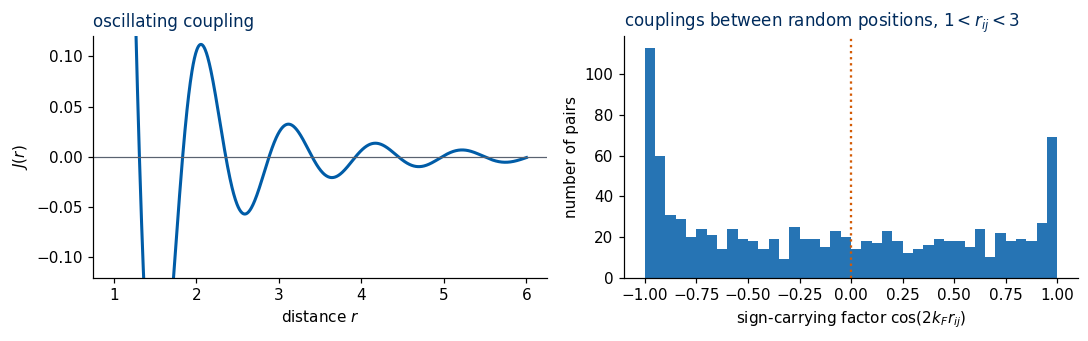

pairs with 1 < r < 3: 945;  fraction with J > 0 (ferromagnetic): 0.433,  fraction with J < 0 (antiferromagnetic): 0.567


In [2]:
def rkky(r, kF=3.0):
    # RKKY-like coupling: magnitude 1/r^3, sign oscillating with the distance r
    return np.cos(2 * kF * r) / r**3

n_moments, box = 400, 20.0
pos = rng.uniform(0, box, size=(n_moments, 3))                      # (n_moments, 3) random positions of the magnetic atoms
diff = pos[:, None, :] - pos[None, :, :]                            # (n_moments, n_moments, 3) pair separations
r_pairs = np.sqrt((diff**2).sum(-1))[np.triu_indices(n_moments, 1)] # all pair distances, each pair once
near = (r_pairs > 1) & (r_pairs < 3)                                 # the strongest couplings

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
rr = np.linspace(1, 6, 1000)
ax[0].plot(rr, rkky(rr), color=UJBlue, lw=2); ax[0].axhline(0, color=UJGray, lw=0.8)
ax[0].set_ylim(-0.12, 0.12); ax[0].set_xlabel("distance $r$"); ax[0].set_ylabel("$J(r)$"); ax[0].set_title("oscillating coupling")
ax[1].hist(np.cos(6.0 * r_pairs[near]), bins=40, color=UJBlue, alpha=0.85); ax[1].axvline(0, color=DSOrange, ls=":")
ax[1].set_xlabel(r"sign-carrying factor $\cos(2k_F r_{ij})$"); ax[1].set_ylabel("number of pairs")
ax[1].set_title("couplings between random positions, $1<r_{ij}<3$")
fig.tight_layout(); plt.show()
print(f"pairs with 1 < r < 3: {near.sum()};  fraction with J > 0 (ferromagnetic): {np.mean(rkky(r_pairs[near]) > 0):.3f},"
      f"  fraction with J < 0 (antiferromagnetic): {np.mean(rkky(r_pairs[near]) < 0):.3f}")

Both signs occur in comparable numbers (43% ferromagnetic and 57% antiferromagnetic pairs in this example). The SK model keeps exactly this ingredient, random signs, and drops the geometry: every spin is coupled to every
other spin, with a Gaussian random coupling.

### 1.2 Hard optimisation problems
Finding the lowest-energy configuration of $E(\boldsymbol s)=-\sum_{i<j}J_{ij}s_is_j$ for given couplings is a **combinatorial optimisation problem** over
$2^N$ configurations. With the couplings chosen appropriately, many classic hard problems of computer science (graph partitioning, maximum cut,
satisfiability, all of Karp's 21 NP-complete problems, where NP stands for *nondeterministic polynomial time*) can be expressed in exactly this form [Lucas 2014]; the computational complexity of finding
spin-glass ground states was analysed early by Barahona [Barahona 1982]. Conversely, spin-glass physics produced general-purpose
algorithms: **simulated annealing** [Kirkpatrick, Gelatt & Vecchi 1983] was proposed by one of the two authors of the SK model, and the parallel-tempering
method used in Section 5 was designed for spin glasses [Hukushima & Nemoto 1996].

### 1.3 Energy landscapes in machine learning
A network of binary units with symmetric weights $W_{ij}$ and energy $E(\boldsymbol s)=-\frac12\sum_{ij}W_{ij}s_is_j$ is the Hopfield network
[Hopfield 1982]: the same Hamiltonian, with couplings constructed from data instead of drawn at random. The loss function of a neural network is likewise a
function on a very high-dimensional space with many local minima. The SK model is the solvable prototype of such a **rugged landscape**: exponentially many
minima, barriers between them, and slow dynamics. The vocabulary developed for it (metastable states, overlaps between minima, replicas) is used
throughout the theory of learning [Mézard & Montanari 2009; Charbonneau et al. 2023].

In this notebook the spins have no positions at all: the SK model has no lattice, so there is no spatial pattern to look at. We will
see that the low-temperature phase is nevertheless sharply defined, and that the right tool to see it is a comparison of **two independent copies**
of the system with the same couplings.

<hr/>
## 2. The Sherrington–Kirkpatrick model

### 2.1 The Hamiltonian
The model consists of $N$ Ising spins $s_i=\pm1$, $i=1,\dots,N$, and **every pair** $(i,j)$ is coupled:
$$
\begin{aligned}
H(\boldsymbol s) &= -\sum_{i<j} J_{ij}\, s_i s_j = -\frac12\,\boldsymbol s^{T} J\, \boldsymbol s ,\\
J_{ij}&=J_{ji}\sim\mathcal N\!\left(0,\frac{J^2}{N}\right)\ \text{independent for } i<j,\qquad J_{ii}=0 .
\end{aligned}
$$
Here $\mathcal N(\mu,\sigma^2)$ is the Gaussian distribution with mean $\mu$ and variance $\sigma^2$. The mean is zero: ferromagnetic and antiferromagnetic
couplings are equally likely. A fixed matrix $J$ is called a **disorder realisation** or **sample**.

The figure below draws one sample with $N=8$ spins placed on a circle; the positions carry no meaning, since the model has no lattice. Every pair is connected: a solid blue line is a ferromagnetic coupling $J_{ij}>0$, a dashed green line an antiferromagnetic coupling $J_{ij}<0$, and the line width is proportional to $|J_{ij}|$. The spins follow the convention of all sketches in this course (navy disc $s_i=+1$, white disc with an orange rim $s_i=-1$).

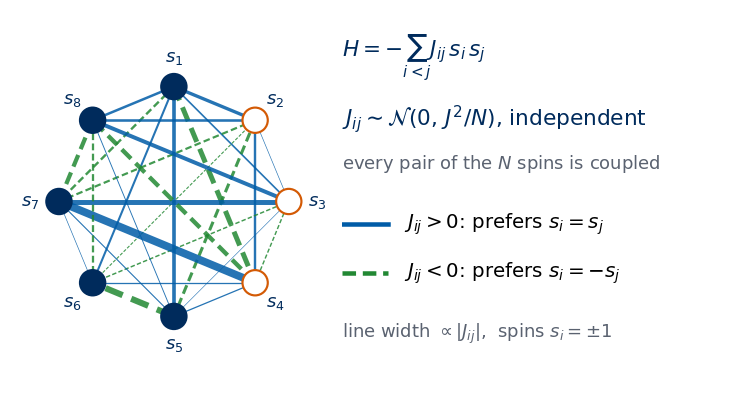

In [3]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("../beamer/figures", exist_ok=True)
    for d in ("../beamer/figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_sk_model():
    N = 8
    rng = np.random.default_rng(1)                                  # one fixed disorder sample and spin configuration
    Jm = np.triu(rng.normal(0.0, 1.0 / np.sqrt(N), (N, N)), 1)      # J_ij ~ N(0, J^2/N) for i < j, with J = 1
    s = rng.choice([-1, 1], N)
    phi = np.pi / 2 - 2 * np.pi * np.arange(N) / N
    X, Y = np.cos(phi), np.sin(phi)
    fig = plt.figure(figsize=(5.5, 2.9))
    ax = fig.add_axes([0.0, 0.0, 0.45, 1.0]); tx = fig.add_axes([0.46, 0.0, 0.54, 1.0]); tx.axis("off")
    # every pair is coupled: blue solid for J_ij > 0 (ferromagnetic), green dashed for J_ij < 0; width proportional to |J_ij|
    scale = 4.0 / np.abs(Jm).max()
    for i in range(N):
        for j in range(i + 1, N):
            ax.plot([X[i], X[j]], [Y[i], Y[j]], color=BLUE if Jm[i, j] > 0 else GREEN, lw=0.3 + scale * abs(Jm[i, j]),
                    ls="-" if Jm[i, j] > 0 else (0, (3, 1.5)), alpha=0.85, zorder=1)
    for i in range(N):
        draw_spin(ax, X[i], Y[i], s[i], r=0.11, lw=1.2)
        ax.text(1.25 * X[i], 1.25 * Y[i], f"$s_{i + 1}$", ha="center", va="center", fontsize=10, color=NAVY)
    ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4); ax.set_aspect("equal"); ax.axis("off")

    tx.set_xlim(0, 1); tx.set_ylim(0, 1)
    tx.text(0.0, 0.88, r"$H=-\sum_{i<j}J_{ij}\,s_i\,s_j$", fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.72, r"$J_{ij}\sim\mathcal{N}(0,\,J^2/N)$, independent", fontsize=12, color=NAVY, va="center")
    tx.text(0.0, 0.6, r"every pair of the $N$ spins is coupled", fontsize=10, color=GRAY, va="center")
    tx.plot([0.0, 0.12], [0.44, 0.44], color=BLUE, lw=2.5)
    tx.text(0.16, 0.44, r"$J_{ij}>0$: prefers $s_i=s_j$", fontsize=11, va="center")
    tx.plot([0.0, 0.12], [0.31, 0.31], color=GREEN, lw=2.5, ls=(0, (3, 1.5)))
    tx.text(0.16, 0.31, r"$J_{ij}<0$: prefers $s_i=-s_j$", fontsize=11, va="center")
    tx.text(0.0, 0.15, r"line width $\propto|J_{ij}|$,  spins $s_i=\pm1$", fontsize=10, color=GRAY, va="center")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_sk_model()
save_sketch(fig, "sketch_sk_card.png")
plt.show()


Two quantities are used throughout. The **local field** on spin $i$ is $h_i=\sum_{j\neq i}J_{ij}s_j$, so that $H=-\frac12\sum_i s_ih_i$.
A flip $s_i\to-s_i$ changes the sign of only the $N-1$ terms containing $s_i$, so the **energy change of one flip** is $\Delta E_i = 2s_ih_i$. A configuration is therefore
stable against every single flip if and only if $s_ih_i>0$ for all $i$, that is, if every spin is aligned with its local field.

### 2.2 Scaling of the couplings
The variance is chosen as $J^2/N$, not $J^2$, and the reason is the size of the local field. Take **any** fixed configuration $\boldsymbol s$. Then $J_{ij}s_j$ has the same Gaussian distribution as $J_{ij}$
(the distribution is symmetric under $J\to-J$), so the local field is a sum of $N-1$ independent Gaussians:
$$
\operatorname{Var}(h_i) = (N-1)\,\sigma^2,\qquad \sigma^2=\operatorname{Var}(J_{ij}).
$$
With $\sigma^2=J^2/N$ we get $\operatorname{Var}(h_i)=J^2(N-1)/N\to J^2$: the field on a spin stays **of order one** as $N$ grows, temperatures of order $J$
compete with it, and the transition temperature has a finite limit. Without the scaling, $\sigma^2=J^2$, the field would grow like $\sqrt N\,J$, and so would every characteristic temperature;
there would be no thermodynamic limit. The contrast with the ferromagnet is instructive. A ferromagnet with all-to-all couplings needs $J_{ij}=J_0/N$ (the Curie–Weiss model), because there the $N$ terms add **coherently**, $h_i=J_0m$.
Random signs add **incoherently**, like a random walk, so the coupling is scaled by $1/\sqrt N$ in magnitude, i.e. $1/N$ in variance.

The energy of a configuration is $H=-\sum_{i<j}J_{ij}s_is_j$, a sum of $N(N-1)/2$ independent terms. For a **random** configuration it has mean $0$ and
variance $\frac{N(N-1)}2\,\sigma^2 = \frac{(N-1)J^2}{2}$: a typical configuration has energy of order $\sqrt N$. The low-energy configurations, which
dominate at low temperature, have energies of order $-N$ (Section 6); the energy is **extensive**.

We check these statements symbolically with SymPy (the Gaussian moments by direct integration, then the sums by independence) and then numerically.

In [4]:
x = sp.symbols("x", real=True)
sigma, Jc, N_s, alpha = sp.symbols("sigma J N alpha", positive=True)

gauss = sp.exp(-x**2 / (2 * sigma**2)) / sp.sqrt(2 * sp.pi * sigma**2)    # density of N(0, sigma^2)
moment = lambda k: sp.simplify(sp.integrate(x**k * gauss, (x, -sp.oo, sp.oo)))
print("normalisation   :", moment(0))
print("E[J_ij]         :", moment(1))
print("E[J_ij^2]       :", moment(2))
print("E[J_ij^4]       :", moment(4))

# independent terms: the variance of a sum is the sum of the variances
var_h = (N_s - 1) * moment(2)                       # local field: N-1 couplings
var_H = N_s * (N_s - 1) / 2 * moment(2)             # energy of a random configuration: N(N-1)/2 couplings
print("\nVar(h_i)               =", var_h)
print("Var(H), random config  =", var_H)

var_h_SK = sp.simplify(var_h.subs(sigma**2, Jc**2 / N_s))
print("\nwith sigma^2 = J^2/N:  Var(h_i) =", var_h_SK, "  ->  N -> oo:", sp.limit(var_h_SK, N_s, sp.oo))
print("with sigma^2 = J^2/N:  Var(H)   =", sp.simplify(var_H.subs(sigma**2, Jc**2 / N_s)))

# general scaling sigma^2 = J^2 / N^alpha: the field has a finite, non-zero limit only for alpha = 1
var_h_alpha = var_h.subs(sigma**2, Jc**2 / N_s**alpha)
for a in (sp.Rational(1, 2), 1, 2):
    print(f"alpha = {a}:  Var(h_i) = {sp.simplify(var_h_alpha.subs(alpha, a))}  ->  N -> oo: {sp.limit(var_h_alpha.subs(alpha, a), N_s, sp.oo)}")

normalisation   : 1
E[J_ij]         : 0


E[J_ij^2]       : sigma**2
E[J_ij^4]       : 3*sigma**4

Var(h_i)               = sigma**2*(N - 1)
Var(H), random config  = N*sigma**2*(N - 1)/2

with sigma^2 = J^2/N:  Var(h_i) = J**2*(N - 1)/N   ->  N -> oo: J**2
with sigma^2 = J^2/N:  Var(H)   = J**2*(N - 1)/2
alpha = 1/2:  Var(h_i) = J**2*(N - 1)/sqrt(N)  ->  N -> oo: oo
alpha = 1:  Var(h_i) = J**2*(N - 1)/N  ->  N -> oo: J**2
alpha = 2:  Var(h_i) = J**2*(N - 1)/N**2  ->  N -> oo: 0


SymPy reproduces the Gaussian moments and the two variances, and it shows that only the exponent $\alpha=1$ in $\sigma^2=J^2/N^\alpha$ keeps the local field finite and non-zero for $N\to\infty$.
For the numerical check we draw, for several $N$, `n_dis` coupling matrices of shape `(n_dis, N, N)`, one random configuration per matrix, and compute the
local fields $h=J\boldsymbol s$ (shape `(n_dis, N)`) and the energies $H=-\frac12\boldsymbol s^TJ\boldsymbol s$ (shape `(n_dis,)`). The function
`sk_couplings` defined here is used in the whole notebook: it draws the upper triangle and symmetrises.

In [5]:
def sk_couplings(key, n_dis, N, J=1.0):
    """n_dis independent SK coupling matrices, shape (n_dis, N, N): symmetric, zero diagonal, J_ij ~ N(0, J^2/N)."""
    A = jax.random.normal(key, (n_dis, N, N)) * (J / jnp.sqrt(N))
    upper = jnp.triu(A, 1)                                   # keep i < j only
    return upper + jnp.swapaxes(upper, 1, 2)                 # J_ji = J_ij, J_ii = 0

def random_spins(key, shape):
    """Uniformly random configurations s_i = +-1 (float32)."""
    return jnp.where(jax.random.bernoulli(key, 0.5, shape), 1.0, -1.0)

print("   N   Var(h_i) measured   (N-1)/N    Var(H)/N measured         (N-1)/(2N)   samples")
key = jax.random.PRNGKey(1)
for N in (16, 64, 256, 1024):
    n_batch, batch = 16, max(4, 2**21 // N**2)               # 16 batches; the batch size keeps the memory bounded
    hv, Hs = [], []
    for _ in range(n_batch):
        key, k1, k2 = jax.random.split(key, 3)
        Jm = sk_couplings(k1, batch, N)                       # (batch, N, N)
        s = random_spins(k2, (batch, N))                      # one random configuration per sample
        h = jnp.einsum("dij,dj->di", Jm, s)                   # (batch, N) local fields
        hv.append(np.asarray(h).ravel()); Hs.append(np.asarray(-0.5 * jnp.sum(s * h, axis=1)))   # energies (batch,)
    hv, Hs = np.concatenate(hv), np.concatenate(Hs)
    n = len(Hs)
    var_H, err_H = Hs.var() / N, Hs.var() / N * np.sqrt(2 / (n - 1))   # standard error of a variance estimate
    print(f"{N:5d}   {hv.var():8.4f}            {(N - 1) / N:7.4f}    {var_H:8.4f} ± {err_H:.4f}         {(N - 1) / (2 * N):7.4f}     {n}")

   N   Var(h_i) measured   (N-1)/N    Var(H)/N measured         (N-1)/(2N)   samples


   16     0.9379             0.9375      0.4680 ± 0.0018          0.4688     131072


   64     0.9843             0.9844      0.4833 ± 0.0076          0.4922     8192


  256     0.9889             0.9961      0.4798 ± 0.0300          0.4980     512


 1024     1.0022             0.9990      0.4186 ± 0.0746          0.4995     64


The measured variances agree with the formulas within the sampling fluctuations of the finite number of samples. The local field stays of order one for every $N$;
the energy of a *random* configuration is of order $\sqrt N$, small compared with the extensive energies of the low-lying states.

### 2.3 Global flip and gauge symmetry
The Hamiltonian has two symmetries. The first is the global flip: $H(-\boldsymbol s)=H(\boldsymbol s)$ for every sample, hence $\langle s_i\rangle=0$ exactly at any finite $N$.
The second is a gauge transformation. Choose any signs $\tau_i=\pm1$ and transform
$$
s_i\to\tau_is_i,\qquad J_{ij}\to\tau_i\tau_jJ_{ij}.
$$
Each term $J_{ij}s_is_j\to\tau_i^2\tau_j^2J_{ij}s_is_j=J_{ij}s_is_j$ is unchanged, so the energy of every configuration is unchanged. Because the Gaussian
distribution of $J_{ij}$ is symmetric, the transformed couplings $\tau_i\tau_jJ_{ij}$ moreover have **the same distribution** as the original ones.

The gauge symmetry has a strong consequence. Every quantity averaged over the disorder must be invariant under the transformation. The magnetisation of a
sample, $\frac1N\sum_i\langle s_i\rangle$, is not invariant ($s_i\to\tau_is_i$ flips arbitrary spins), so it carries no information about the
ordering after averaging over samples. The invariant combinations are products in which every spin index appears twice, such as
$\langle s_is_j\rangle^2$ or, for two copies $a,b$ of the system, $s_i^as_i^b$. These are the building blocks of the spin-glass order parameter (Section 4).
The cell below verifies the invariance symbolically for $N=4$ and numerically for one sample of $N=200$ spins, where the energy is unchanged and the magnetisation is not.

In [6]:
# symbolic check of the gauge invariance for N = 4: spins s_i, signs tau_i, couplings J_ij
Ng = 4
s_sym = sp.symbols(f"s1:{Ng + 1}")
t_sym = sp.symbols(f"tau1:{Ng + 1}")
J_sym = {(i, j): sp.Symbol(f"J{i + 1}{j + 1}") for i in range(Ng) for j in range(i + 1, Ng)}

H_sym = -sum(Jij * s_sym[i] * s_sym[j] for (i, j), Jij in J_sym.items())
H_gauge = -sum(t_sym[i] * t_sym[j] * Jij * (t_sym[i] * s_sym[i]) * (t_sym[j] * s_sym[j]) for (i, j), Jij in J_sym.items())
difference = sp.expand(sp.expand(H_gauge).subs({t**2: 1 for t in t_sym}) - H_sym)   # use tau_i^2 = 1
print("H(s; J) =", H_sym)
print("H(tau s; tau_i tau_j J_ij) - H(s; J) =", difference)

# numerical check on one sample with N = 200
key, k1, k2, k3 = jax.random.split(key, 4)
Jm = sk_couplings(k1, 1, 200)[0]
s = random_spins(k2, (200,)); tau = random_spins(k3, (200,))
E = lambda s, J: -0.5 * s @ J @ s
print(f"\nN = 200:  E(s; J) = {float(E(s, Jm)):.6f},   E(tau*s; tau_i tau_j J_ij) = {float(E(tau * s, Jm * jnp.outer(tau, tau))):.6f}")
print(f"magnetisation before {float(s.mean()):+.3f}, after the gauge transformation {float((tau * s).mean()):+.3f}  (not invariant)")

H(s; J) = -J12*s1*s2 - J13*s1*s3 - J14*s1*s4 - J23*s2*s3 - J24*s2*s4 - J34*s3*s4
H(tau s; tau_i tau_j J_ij) - H(s; J) = 0



N = 200:  E(s; J) = -8.619366,   E(tau*s; tau_i tau_j J_ij) = -8.619366
magnetisation before +0.050, after the gauge transformation +0.090  (not invariant)


### 2.4 Quenched disorder
A spin glass has two sources of randomness, on two very different time scales. The first is thermal noise: at fixed couplings $J$ the spins fluctuate, and thermal averages are Boltzmann averages at fixed $J$,
$$
\begin{aligned}
\langle A\rangle_J&=\frac{1}{Z_J}\sum_{\boldsymbol s}A(\boldsymbol s)\,e^{-\beta H_J(\boldsymbol s)},\\
Z_J&=\sum_{\boldsymbol s}e^{-\beta H_J(\boldsymbol s)} .
\end{aligned}
$$
The second is the disorder itself. The couplings are random but frozen (*quenched*): in the alloy the atoms do not move on the time scale of the spin dynamics. The average
over realisations, $[X]=\int\!\prod_{i<j}dJ_{ij}\,P(J_{ij})\;X(J)$, is therefore taken **after** the thermal average, sample by sample.

The physically relevant free energy is the **quenched** average
$$
f=-\frac{T}{N}\,[\ln Z_J],
$$
not the **annealed** one, $f_{\rm ann}=-\frac{T}{N}\ln[Z_J]$, which would describe couplings that fluctuate and equilibrate together with the spins.
The reason the quenched average is the meaningful one is **self-averaging**: as $N\to\infty$, the free energy per spin of a single large sample,
$-\frac{T}{N}\ln Z_J$, converges to its disorder average. One large sample is representative. $Z_J$ itself is *not* self-averaging: it is exponential
in $N$ and its average is dominated by rare samples.

The logarithm is concave, so Jensen's inequality gives a strict ordering: $[\ln Z_J]\le\ln[Z_J]$, i.e. $f\ge f_{\rm ann}$.

The annealed free energy, unlike the quenched one, can be computed exactly. The average of $Z$ is easy, because the couplings are independent and appear in the exponent:
$$
\begin{aligned}
[Z_J] &= \sum_{\boldsymbol s}\prod_{i<j}\big[e^{\beta J_{ij}s_is_j}\big],\\
\big[e^{\beta J_{ij}s_is_j}\big]&=e^{\beta^2\sigma^2/2}\quad(\text{Gaussian integral; independent of } s_is_j=\pm1).
\end{aligned}
$$
Every configuration contributes the same factor, so $[Z_J]=2^N\exp\!\big(\frac{N(N-1)}2\frac{\beta^2J^2}{2N}\big)$ and, for $N\to\infty$,
$$
\begin{aligned}
-\beta f_{\rm ann}&=\ln2+\frac{\beta^2J^2}{4},\\
u_{\rm ann}&=-\frac{\beta J^2}2,\\
s_{\rm ann}&=\ln2-\frac{\beta^2J^2}{4}.
\end{aligned}
$$
The annealed entropy becomes **negative** below $T^*=J/(2\sqrt{\ln2})$. The entropy of a system with a finite number of discrete states is
$-\sum p\ln p\ge0$, so the annealed result must fail at low temperature. Aizenman, Lebowitz and Ruelle proved that for $T>J$ the quenched free energy
equals the annealed one in the limit $N\to\infty$ [Aizenman, Lebowitz & Ruelle 1987]: the high-temperature phase is simple, and something happens at $T=J$.
We derive the annealed results with SymPy and then compare them with exact enumeration of small systems.

In [7]:
beta, Jc, N_s, sig2 = sp.symbols("beta J N sigma2", positive=True)
x, eps = sp.symbols("x epsilon", real=True)
gauss = sp.exp(-x**2 / (2 * sig2)) / sp.sqrt(2 * sp.pi * sig2)

# one coupling: [exp(beta * J_ij * eps)] with eps = s_i s_j = +-1
for e in (1, -1):
    avg = sp.simplify(sp.integrate(sp.exp(beta * x * e) * gauss, (x, -sp.oo, sp.oo)))
    print(f"[exp(beta J_ij * ({e:+d}))] =", avg)

# [Z] = 2^N * (one-coupling factor)^(number of pairs), with sigma^2 = J^2/N
log_Zann = N_s * sp.log(2) + N_s * (N_s - 1) / 2 * (beta**2 * sig2 / 2)
log_Zann = log_Zann.subs(sig2, Jc**2 / N_s)
minus_beta_f = sp.limit(log_Zann / N_s, N_s, sp.oo)
print("\nln[Z]/N              =", sp.simplify(log_Zann / N_s))
print("-beta f_ann (N->oo)  =", minus_beta_f)

u_ann = sp.simplify(-sp.diff(minus_beta_f, beta))                 # u = d(beta f)/d beta
s_ann = sp.simplify(minus_beta_f + beta * u_ann)                  # s = beta (u - f)
print("u_ann                =", u_ann)
print("s_ann                =", s_ann)
T_star = 1 / sp.solve(sp.Eq(s_ann, 0), beta)[0]
print("s_ann = 0 at T* =", sp.simplify(T_star), "=", sp.N(T_star.subs(Jc, 1), 6), "J")

[exp(beta J_ij * (+1))] = exp(beta**2*sigma2/2)


[exp(beta J_ij * (-1))] = exp(beta**2*sigma2/2)

ln[Z]/N              = (J**2*beta**2*(N - 1)/4 + N*log(2))/N
-beta f_ann (N->oo)  = J**2*beta**2/4 + log(2)
u_ann                = -J**2*beta/2
s_ann                = -J**2*beta**2/4 + log(2)
s_ann = 0 at T* = J/(2*sqrt(log(2))) = 0.600561 J


SymPy confirms the annealed formulas and places the zero of the annealed entropy at $T^*=0.6006\,J$. To see what the quenched average does instead we turn to exact enumeration.

For $N\le 24$ we can visit all $2^N$ configurations. Because $H(-\boldsymbol s)=H(\boldsymbol s)$ we fix $s_N=+1$, enumerate the
$M=2^{N-1}$ remaining configurations, and account for the mirror images by a factor $2$. Configuration number $k$ is encoded by the bits of $k$,
$s_i=2\,\mathrm{bit}_i(k)-1$. For one sample the computation uses the following arrays.

| array | shape | meaning |
|---|---|---|
| `S` | `(M, N)` | all configurations with $s_N=+1$ |
| `Hf = S @ J` | `(M, N)` | local fields $h_i$ of every configuration |
| `E` | `(M,)` | energies $E=-\frac12\sum_is_ih_i$ |
| `logw` | `(n_T, M)` | $-\beta E$ for every temperature on the grid |

From these we obtain $\ln Z_J=\ln2+\operatorname{logsumexp}(-\beta E)$, the energy $U=\langle E\rangle$, the ground-state energy $E_0=\min E$, and the number of
configurations stable against every single flip (all $s_ih_i>0$). For the spin-glass susceptibility (Section 4) we also need the correlation matrix
$C_{ij}=\langle s_is_j\rangle$ of shape `(N, N)`, which is $S^T\mathrm{diag}(p)\,S$ with the Boltzmann probabilities $p$ (the mirror images give the same $s_is_j$).
The cell below compares the vectorised enumeration with a direct loop on one sample.

In [8]:
def half_configs(N):
    """All 2^(N-1) configurations with s_N = +1, shape (2^(N-1), N), float32."""
    k = jnp.arange(2 ** (N - 1), dtype=jnp.int32)
    bits = (k[:, None] >> jnp.arange(N - 1)) & 1
    return jnp.concatenate([2.0 * bits - 1.0, jnp.ones((k.size, 1))], axis=1)

@jax.jit
def enumerate_sample(J, betas, betas_chi):
    """Exact thermodynamics of one sample J (N, N).
    Returns ln Z (n_T,), U (n_T,), E0, number of single-flip-stable configurations, chi_SG (n_chi,)."""
    N = J.shape[0]
    S = half_configs(N)                                        # (M, N)
    Hf = S @ J                                                 # (M, N) local fields
    E = -0.5 * jnp.sum(S * Hf, axis=1)                         # (M,) energies
    n_stable = 2 * jnp.sum(jnp.all(S * Hf > 0, axis=1))        # x2 for the mirror images
    logw = -betas[:, None] * E[None, :]                        # (n_T, M)
    lse = jax.scipy.special.logsumexp(logw, axis=1)
    p = jnp.exp(logw - lse[:, None])                           # Boltzmann probabilities on the half space
    logZ = jnp.log(2.0) + lse
    U = p @ E
    # spin-glass susceptibility chi_SG = (1/N) sum_ij <s_i s_j>^2 at the temperatures betas_chi
    pc = jnp.exp(-betas_chi[:, None] * E[None, :] - jax.scipy.special.logsumexp(-betas_chi[:, None] * E[None, :], axis=1)[:, None])
    C = jnp.einsum("bm,mi,mj->bij", pc, S, S)                  # (n_chi, N, N) correlation matrices
    chi = jnp.sum(C**2, axis=(1, 2)) / N
    return logZ, U, jnp.min(E), n_stable, chi

@partial(jax.jit, static_argnames=("n_chunk",))
def ground_state_chunked(J, n_chunk):
    """E0 and the number of single-flip-stable configurations, enumerating in n_chunk chunks (for N = 22, 24)."""
    N = J.shape[0]
    M = 2 ** (N - 1); m = M // n_chunk
    def body(carry, c):
        k = c * m + jnp.arange(m, dtype=jnp.int32)
        bits = (k[:, None] >> jnp.arange(N - 1)) & 1
        S = jnp.concatenate([2.0 * bits - 1.0, jnp.ones((m, 1))], axis=1)
        Hf = S @ J
        E = -0.5 * jnp.sum(S * Hf, axis=1)
        return (jnp.minimum(carry[0], E.min()), carry[1] + jnp.sum(jnp.all(S * Hf > 0, axis=1))), None
    (E0, n), _ = lax.scan(body, (jnp.inf, 0), jnp.arange(n_chunk))
    return E0, 2 * n

# check against a direct loop over all 2^N configurations (itertools) for one N = 8 sample
J8 = np.asarray(sk_couplings(jax.random.PRNGKey(5), 1, 8)[0], dtype=np.float64)
T_check = np.array([0.5, 1.0, 2.0])
all_s = np.array(list(itertools.product([-1, 1], repeat=8)), dtype=np.float64)
E_all = -0.5 * np.einsum("ri,ij,rj->r", all_s, J8, all_s)
logZ_direct = logsumexp(-E_all[None, :] / T_check[:, None], axis=1)
stable_direct = np.sum(np.all(all_s * (all_s @ J8) > 0, axis=1))
out = enumerate_sample(jnp.asarray(J8, jnp.float32), jnp.asarray(1 / T_check, jnp.float32), jnp.asarray([1.0], jnp.float32))
print("ln Z, direct loop     :", np.round(logZ_direct, 5), "  E0 =", round(E_all.min(), 5), "  stable configurations:", stable_direct)
print("ln Z, enumerate_sample:", np.round(np.asarray(out[0]), 5), "  E0 =", round(float(out[2]), 5), "  stable configurations:", int(out[3]))
E0c, nc = ground_state_chunked(jnp.asarray(J8, jnp.float32), 4)
print("ground_state_chunked  :", "E0 =", round(float(E0c), 5), "  stable configurations:", int(nc))

ln Z, direct loop     : [12.98312  7.98436  6.22453]   E0 = -5.85214   stable configurations: 4
ln Z, enumerate_sample: [12.98312  7.98436  6.22453]   E0 = -5.85214   stable configurations: 4
ground_state_chunked  : E0 = -5.85214   stable configurations: 4


The three implementations give identical $\ln Z$, ground-state energy and number of stable configurations.

Now the disorder average. For each $N$ we draw many samples; the number decreases with $N$ because the cost grows like $2^N$.
The temperature grid `T_enum` is used for the free energy and the energy; the spin-glass susceptibility is computed at the few temperatures `T_chi`.
For $N=22$ and $24$ we only compute ground-state energies and the number of stable configurations (Section 6).

In [9]:
T_enum = np.round(np.linspace(0.2, 3.0, 29), 3)                 # temperature grid of the exact calculation
T_chi = np.array([0.5, 1.0, 1.2, 1.5, 2.0, 3.0])                  # temperatures for chi_SG (all on T_enum)
b_enum, b_chi = jnp.asarray(1 / T_enum, jnp.float32), jnp.asarray(1 / T_chi, jnp.float32)
N_ENUM = {8: 1000, 10: 1000, 12: 800, 14: 500, 16: 300, 18: 150, 20: 60}
N_GS_ONLY = {22: 30, 24: 12}

enum = {}                                                         # enum[N] = dict of per-sample arrays
t0 = time.time()
for N, n_samp in N_ENUM.items():
    Js = sk_couplings(jax.random.PRNGKey(100 + N), n_samp, N)
    res = [enumerate_sample(Js[d], b_enum, b_chi) for d in range(n_samp)]
    enum[N] = {k: np.array([np.asarray(r[i]) for r in res]) for i, k in enumerate(["logZ", "U", "E0", "n_stable", "chi"])}
    print(f"N = {N:2d}: {n_samp:5d} samples,  time so far {time.time() - t0:6.1f} s")
for N, n_samp in N_GS_ONLY.items():
    Js = sk_couplings(jax.random.PRNGKey(100 + N), n_samp, N)
    res = [ground_state_chunked(Js[d], 2 ** (N - 20)) for d in range(n_samp)]
    enum[N] = {"E0": np.array([float(r[0]) for r in res]), "n_stable": np.array([int(r[1]) for r in res])}
    print(f"N = {N:2d}: {n_samp:5d} samples (ground states only),  time so far {time.time() - t0:6.1f} s")

N =  8:  1000 samples,  time so far    1.2 s


N = 10:  1000 samples,  time so far    2.8 s


N = 12:   800 samples,  time so far    4.4 s


N = 14:   500 samples,  time so far    6.5 s


N = 16:   300 samples,  time so far    9.7 s


N = 18:   150 samples,  time so far   17.7 s


N = 20:    60 samples,  time so far   36.4 s


N = 22:    30 samples (ground states only),  time so far   39.2 s


N = 24:    12 samples (ground states only),  time so far   42.8 s


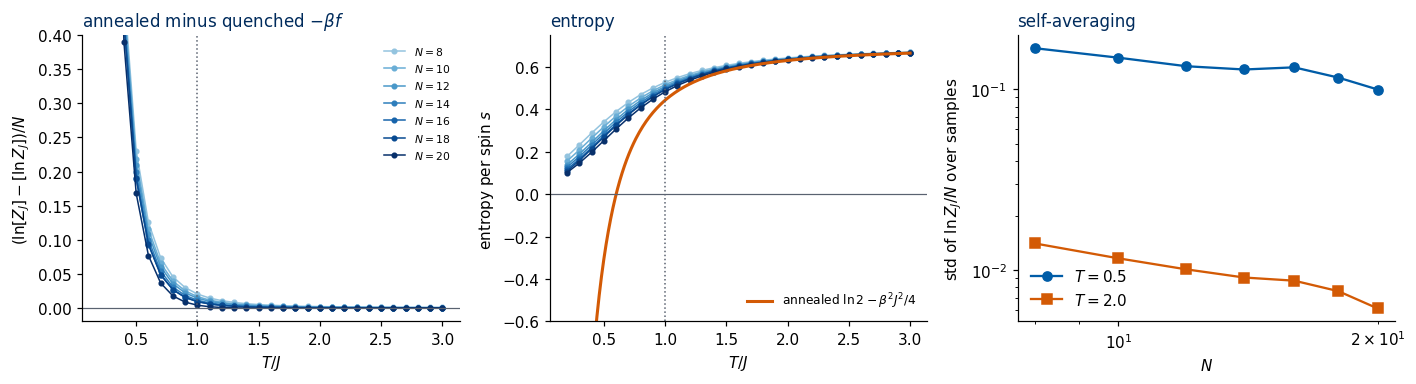

N =  8:  T = 2.0: [ln Z]/N = 0.7460, finite-N annealed ln2 + beta^2 (N-1)/(4N) = 0.7478   |   T = 0.5: [ln Z]/N = 1.3373, annealed 1.5681
N = 20:  T = 2.0: [ln Z]/N = 0.7529, finite-N annealed ln2 + beta^2 (N-1)/(4N) = 0.7525   |   T = 0.5: [ln Z]/N = 1.4753, annealed 1.6431
N = 20: quenched entropy at T = 0.2: 0.1022 (positive);  annealed entropy at T = 0.2: -5.5569


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
TT = np.linspace(0.2, 3.0, 300)
blues = plt.cm.Blues(np.linspace(0.4, 1.0, len(N_ENUM)))
for c, N in zip(blues, N_ENUM):
    mbf = enum[N]["logZ"].mean(0) / N                                  # quenched -beta f = [ln Z]/N
    ent = mbf + enum[N]["U"].mean(0) / (N * T_enum)                    # s = -beta f + beta u
    ann_N = np.log(2) + (N - 1) / (4 * N * T_enum**2)                   # finite-N annealed ln[Z]/N
    ax[0].plot(T_enum, ann_N - mbf, "o-", ms=3, lw=1, color=c, label=f"$N={N}$")
    ax[1].plot(T_enum, ent, "o-", ms=3, lw=1, color=c)
ax[1].plot(TT, np.log(2) - 1 / (4 * TT**2), color=DSOrange, lw=2, label=r"annealed $\ln2-\beta^2J^2/4$")
ax[0].axhline(0, color=UJGray, lw=0.8); ax[0].set_ylim(-0.02, 0.4); ax[1].set_ylim(-0.6, 0.75); ax[1].axhline(0, color=UJGray, lw=0.8)
for a in ax[:2]: a.axvline(T_C, color=UJGray, ls=":", lw=1); a.set_xlabel("$T/J$")
ax[0].set_ylabel(r"$(\ln[Z_J]-[\ln Z_J])/N$"); ax[0].set_title("annealed minus quenched $-\\beta f$"); ax[0].legend(frameon=False, fontsize=7)
ax[1].set_ylabel("entropy per spin $s$"); ax[1].set_title("entropy"); ax[1].legend(frameon=False, fontsize=8)

# self-averaging: sample-to-sample spread of ln Z_J / N
for Tsel, mk in ((0.5, "o"), (2.0, "s")):
    i = np.argmin(abs(T_enum - Tsel))
    Ns = np.array(list(N_ENUM))
    ax[2].loglog(Ns, [enum[N]["logZ"][:, i].std() / N for N in Ns], mk + "-", color=UJBlue if Tsel < 1 else DSOrange, label=f"$T={Tsel}$")
ax[2].set_xlabel("$N$"); ax[2].set_ylabel(r"std of $\ln Z_J/N$ over samples"); ax[2].set_title("self-averaging"); ax[2].legend(frameon=False)
fig.tight_layout(); savefig(fig, "gen_sk_annealed_vs_quenched.png"); plt.show()

i2, i05 = np.argmin(abs(T_enum - 2.0)), np.argmin(abs(T_enum - 0.5))
for N in (8, 20):
    print(f"N = {N:2d}:  T = 2.0: [ln Z]/N = {enum[N]['logZ'][:, i2].mean() / N:.4f}, finite-N annealed ln2 + beta^2 (N-1)/(4N) = "
          f"{np.log(2) + 0.25 * (N - 1) / N / 4:.4f}   |   T = 0.5: [ln Z]/N = {enum[N]['logZ'][:, i05].mean() / N:.4f}, "
          f"annealed {np.log(2) + 4 * (N - 1) / N / 4:.4f}")
ent20 = enum[20]["logZ"].mean(0) / 20 + enum[20]["U"].mean(0) / (20 * T_enum)
print(f"N = 20: quenched entropy at T = 0.2: {ent20[0]:.4f} (positive);  annealed entropy at T = 0.2: {np.log(2) - 1 / (4 * 0.2**2):.4f}")

The left panel shows the difference between the annealed value $\ln[Z_J]/N=\ln2+\beta^2J^2(N-1)/(4N)$ (exact for every $N$) and the quenched $[\ln Z_J]/N$.
Above $T=J$ the difference is close to zero for every $N$: the high-temperature phase is described by the simple annealed calculation.
Below $T\approx J$ the difference grows and is positive, as Jensen's inequality requires. The middle panel shows why the annealed calculation cannot be trusted there: the quenched entropy stays positive
at all temperatures ($0.102$ per spin at $T=0.2$ for $N=20$), while the annealed entropy becomes negative below $T^*\approx0.60\,J$. The annealed calculation misses the physics of the low-temperature phase.
Finally, the right panel shows that the sample-to-sample spread of $\ln Z_J/N$ decreases with $N$ at both temperatures, $T=0.5$ and $T=2$: the free energy per spin is self-averaging.

<hr/>
## 3. Frustration

### 3.1 One triangle
The simplest situation in which random signs matter is a triangle: three spins with couplings $J_{12}=J_{13}=+1$ (ferromagnetic) and $J_{23}=-1$ (antiferromagnetic). A bond $(ij)$ is **satisfied** if $J_{ij}s_is_j>0$,
i.e. if its contribution $-J_{ij}s_is_j$ to the energy is negative.

The sketch below shows three configurations of this triangle with the coupling written next to each bond. In each of them two bonds are satisfied and one is broken (dashed): the minimum energy is $E=-1$, and no configuration reaches $-3$.

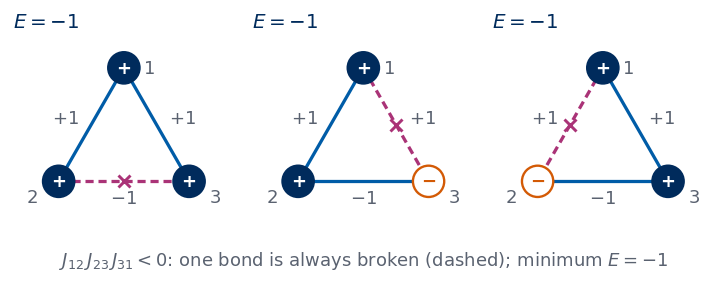

In [11]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("../beamer/figures", exist_ok=True)
    for d in ("../beamer/figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_sk_triangle():
    # couplings J12 = J13 = +1 (ferromagnetic), J23 = -1 (antiferromagnetic): the product J12 J23 J31 is negative
    pos = {1: (0.5, 0.87), 2: (0.0, 0.0), 3: (1.0, 0.0)}
    Jt = {(1, 2): +1, (1, 3): +1, (2, 3): -1}
    states = [(+1, +1, +1), (+1, +1, -1), (+1, -1, +1)]
    fig, axes = plt.subplots(1, 3, figsize=(5.5, 2.2))
    fig.subplots_adjust(left=0.01, right=0.99, bottom=0.13, top=0.86, wspace=0.08)
    for ax, st in zip(axes, states):
        s = dict(zip((1, 2, 3), st))
        E = -sum(J * s[a] * s[b] for (a, b), J in Jt.items())
        for (a, b), J in Jt.items():
            draw_bond(ax, pos[a], pos[b], broken=J * s[a] * s[b] < 0, lw=1.8)
            mx, my = (pos[a][0] + pos[b][0]) / 2, (pos[a][1] + pos[b][1]) / 2
            off = {(1, 2): (-0.2, 0.05), (1, 3): (0.2, 0.05), (2, 3): (0, -0.13)}[(a, b)]
            ax.text(mx + off[0], my + off[1], f"${J:+d}$", ha="center", va="center", fontsize=10, color=GRAY)
        for k, (x, y) in pos.items():
            draw_spin(ax, x, y, s[k], r=0.12, sign=True, fs=10)
            ax.text(x + {1: 0.2, 2: -0.2, 3: 0.2}[k], y + {1: 0.0, 2: -0.12, 3: -0.12}[k], f"{k}", fontsize=10, color=GRAY,
                    ha="center", va="center")
        ax.set_title(f"$E={E:+d}$", fontsize=11, color=NAVY)
        ax.set_xlim(-0.35, 1.35); ax.set_ylim(-0.3, 1.1); ax.set_aspect("equal"); ax.axis("off")
    fig.text(0.5, 0.02, r"$J_{12}\,J_{23}\,J_{31}<0$: one bond is always broken (dashed); minimum $E=-1$",
             ha="center", fontsize=10, color=GRAY)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_sk_triangle()
save_sketch(fig, "sketch_sk_triangle.png")
plt.show()


We list all $2^3=8$ configurations.

In [12]:
J_tri = {(0, 1): +1, (0, 2): +1, (1, 2): -1}
print(" s1  s2  s3 |  E  | broken bonds")
for s in itertools.product([1, -1], repeat=3):
    E = -sum(Jij * s[i] * s[j] for (i, j), Jij in J_tri.items())
    broken = [f"{i + 1}{j + 1}" for (i, j), Jij in J_tri.items() if Jij * s[i] * s[j] < 0]
    print(f"{s[0]:+3d} {s[1]:+3d} {s[2]:+3d} | {E:+3d} | {', '.join(broken)}")

 s1  s2  s3 |  E  | broken bonds
 +1  +1  +1 |  -1 | 23
 +1  +1  -1 |  -1 | 13
 +1  -1  +1 |  -1 | 12
 +1  -1  -1 |  +3 | 12, 13, 23
 -1  +1  +1 |  +3 | 12, 13, 23
 -1  +1  -1 |  -1 | 12
 -1  -1  +1 |  -1 | 13
 -1  -1  -1 |  -1 | 23


The minimum energy is $E=-1$, not $-3$: **every** configuration breaks at least one bond, and the minimum is six-fold degenerate (any one of the three bonds can be
the broken one, times the global flip). The triangle is **frustrated**: no configuration satisfies all its couplings.

### 3.2 Loop products
The triangle suggests a general criterion, and it can be found without enumerating anything. Multiply the three bond terms around the triangle:
$$
(J_{12}s_1s_2)(J_{23}s_2s_3)(J_{31}s_3s_1)=J_{12}J_{23}J_{31}\,s_1^2s_2^2s_3^2=J_{12}J_{23}J_{31}.
$$
The product of the bond terms does not depend on the spins. A satisfied bond has a positive term, so if all three bonds were satisfied the product would be positive.
Hence: **if $J_{12}J_{23}J_{31}<0$, at least one bond is broken in every configuration** (in fact an odd number). The argument works for any closed loop of bonds,
since every spin on a loop appears in exactly two bond terms. The product around a loop is also **gauge invariant**: $\tau_i\tau_jJ_{ij}$ multiplies the
product by $\prod\tau^2=1$. Frustration is a property of the couplings that no relabelling of spins can remove; the signs of individual couplings are not.

For couplings of arbitrary magnitudes $a,b,c>0$ and signs with a negative product, the ground-state energy is $-(a+b+c)+2\min(a,b,c)$: the weakest bond is the
one that breaks. SymPy confirms both statements.

In [13]:
s1, s2, s3 = sp.symbols("s1 s2 s3")
J12, J23, J31 = sp.symbols("J12 J23 J31", real=True)
loop = sp.expand((J12 * s1 * s2) * (J23 * s2 * s3) * (J31 * s3 * s1))
print("product of bond terms             :", loop)
print("with s_i^2 = 1                    :", loop.subs({s1**2: 1, s2**2: 1, s3**2: 1}))

# ground-state energy of a frustrated triangle: J12 = a, J31 = b, J23 = -c with a, b, c > 0
a, b, c = sp.symbols("a b c", positive=True)
Jv = {(0, 1): a, (1, 2): -c, (2, 0): b}
energies = sorted({sp.simplify(-sum(Jij * s[i] * s[j] for (i, j), Jij in Jv.items())) for s in itertools.product([1, -1], repeat=3)},
                  key=lambda e: str(e))
print("distinct energies of the 8 states :", energies)
print("E0 for a = 3, b = 2, c = 1        :", min(e.subs({a: 3, b: 2, c: 1}) for e in energies),
      "   formula -(a+b+c) + 2 min(a,b,c):", -(3 + 2 + 1) + 2 * 1)
print("gauge transformation of the product:", sp.expand((sp.Symbol('t1') * sp.Symbol('t2') * J12) * (sp.Symbol('t2') * sp.Symbol('t3') * J23)
                                                  * (sp.Symbol('t3') * sp.Symbol('t1') * J31)), "  (every tau appears squared)")

product of bond terms             : J12*J23*J31*s1**2*s2**2*s3**2
with s_i^2 = 1                    : J12*J23*J31
distinct energies of the 8 states : [-a + b - c, -a - b + c, a + b + c, a - b - c]
E0 for a = 3, b = 2, c = 1        : -4    formula -(a+b+c) + 2 min(a,b,c): -4
gauge transformation of the product: J12*J23*J31*t1**2*t2**2*t3**2   (every tau appears squared)


### 3.3 Frustrated triangles
In the SK model every triple $(i,j,k)$ forms a triangle. The product of three independent couplings with symmetric distributions is negative with probability
$1/2$ (an odd number of negative factors), so half of the $\binom N3$ triangles are frustrated. For a large $N$ we count them without a triple loop.
Let $\sigma_{ij}=\operatorname{sign}J_{ij}$ (with $\sigma_{ii}=0$). Then
$$
\operatorname{Tr}\sigma^3=\sum_{i,j,k}\sigma_{ij}\sigma_{jk}\sigma_{ki}
$$
runs over ordered triples of **distinct** indices (the zero diagonal removes the others), and each triangle appears $3!=6$ times. Hence
$$
\begin{aligned}
n_{\rm unfrustrated}-n_{\rm frustrated}&=\tfrac16\operatorname{Tr}\sigma^3,\\
n_{\rm unfrustrated}+n_{\rm frustrated}&=\binom N3 .
\end{aligned}
$$
We compare three coupling matrices: the SK couplings, the ferromagnet $J_{ij}=J/N$, and the Mattis couplings $J_{ij}=J\xi_i\xi_j/N$ with random
$\xi_i=\pm1$ (Section 7), which have random signs too. For $N=30$ the trace formula is first compared with an explicit loop over triangles.

In [14]:
def frustrated_fraction(J):
    """Fraction of frustrated triangles from Tr(sign(J)^3), J of shape (N, N) with zero diagonal."""
    N = J.shape[0]
    sg = np.sign(np.asarray(J, dtype=np.float64))
    diff = np.trace(sg @ sg @ sg) / 6                         # n_unfrustrated - n_frustrated
    total = N * (N - 1) * (N - 2) / 6
    return (total - diff) / 2 / total

def frustrated_fraction_loop(J):
    """The same by an explicit loop over all triples (for checking)."""
    J = np.asarray(J); N = J.shape[0]
    f = [J[i, j] * J[j, k] * J[k, i] < 0 for i, j, k in itertools.combinations(range(N), 3)]
    return np.mean(f)

def mattis_couplings(xi, J=1.0):
    """Mattis couplings J xi_i xi_j / N, zero diagonal; xi of shape (N,)."""
    N = xi.shape[0]
    return J * (np.outer(xi, xi) - np.eye(N)) / N

N = 30
J_sk = np.asarray(sk_couplings(jax.random.PRNGKey(7), 1, N)[0])
xi = rng.choice([-1.0, 1.0], size=N)
print(f"check, N = {N}: trace formula {frustrated_fraction(J_sk):.5f}, explicit loop {frustrated_fraction_loop(J_sk):.5f}")

N = 512
J_sk = np.asarray(sk_couplings(jax.random.PRNGKey(8), 1, N)[0])
xi = rng.choice([-1.0, 1.0], size=N)
J_ferro = (np.ones((N, N)) - np.eye(N)) / N
J_mattis = mattis_couplings(xi)
print(f"\nN = {N}, {N * (N - 1) * (N - 2) // 6} triangles")
for name, Jm in (("SK", J_sk), ("ferromagnet", J_ferro), ("Mattis", J_mattis)):
    print(f"  {name:12s} fraction of negative couplings {np.mean(Jm[np.triu_indices(N, 1)] < 0):.3f},   fraction of frustrated triangles {frustrated_fraction(Jm):.4f}")

check, N = 30: trace formula 0.51133, explicit loop 0.51133



N = 512, 22238720 triangles
  SK           fraction of negative couplings 0.499,   fraction of frustrated triangles 0.4999
  ferromagnet  fraction of negative couplings 0.000,   fraction of frustrated triangles 0.0000
  Mattis       fraction of negative couplings 0.501,   fraction of frustrated triangles 0.0000


The trace formula agrees with the explicit count, and for $N=512$ the SK couplings have a fraction $0.4999$ of frustrated triangles.
The Mattis couplings have as many negative signs as the SK couplings, yet not a single frustrated triangle: their loop products are $\xi_i^2\xi_j^2\xi_k^2/N^3>0$.
Random signs alone do not make a spin glass; random signs **with frustration** do. Section 7 shows what this means physically.

<hr/>
## 4. Order without a pattern

### 4.1 Frozen spins with zero magnetisation
In a ferromagnet below $T_c$ the thermal averages $\langle s_i\rangle$ are all equal, and the magnetisation $m=\frac1N\sum_i\langle s_i\rangle$ measures the order.
In a spin glass below its freezing temperature each spin also has a non-zero average $\langle s_i\rangle$ inside the valley the system is trapped in, but the
signs of the $\langle s_i\rangle$ follow the random couplings, not a common direction. Their sum is a sum of $N$ terms of random sign, so $m$ is of order
$1/\sqrt N$ and vanishes for large $N$. (After averaging over the disorder, $[\langle s_i\rangle]=0$ exactly by the gauge symmetry of Section 2.3.)
The SK model has no lattice either, so a snapshot cannot show domains or stripes: the labels $i$ carry no geometry, and any permutation of the labels
(with the couplings permuted accordingly) describes the same system. **A snapshot of the frozen phase looks like noise.**

### 4.2 The Edwards–Anderson order parameter
Edwards and Anderson proposed to measure the freezing itself, regardless of the directions [Edwards & Anderson 1975]:
$$
q_{\rm EA}=\frac1N\sum_i\langle s_i\rangle^2 .
$$
It is zero in the paramagnet ($\langle s_i\rangle=0$) and positive when the spins are frozen; it is invariant under the gauge transformation.
There is a practical difficulty. In a finite system $\langle s_i\rangle=0$ exactly (global flip symmetry), and $\langle s_i\rangle$ restricted to "the valley
we are in" is not something a simulation or an experiment can define directly.

### 4.3 Two replicas and the overlap
The way out is to simulate **two independent copies** $a$ and $b$ of the system, called **replicas**, with **the same couplings** $J$ and independent thermal
noise. Their joint distribution is the product $p_J(\boldsymbol s^a)\,p_J(\boldsymbol s^b)$. The **overlap**
$$
q_{ab}=\frac1N\sum_{i=1}^Ns_i^as_i^b\ \in[-1,1]
$$
is $+1$ for identical configurations, $-1$ for mirror images, and close to $0$ for unrelated ones; the fraction of spins on which the two replicas differ is
$(1-q_{ab})/2$.

The schematic below summarises the last three subsections on a row of $N=12$ spins. A paramagnet looks different at every time (top pair of rows). A spin glass is frozen into one pattern, which does not change in time but has no net magnetisation (middle pair). Two replicas of the same sample (bottom) freeze into similar patterns; the overlap field $q_i=s_i^as_i^b$ is $+1$ (filled green square) where they agree, and the overlap $q_{ab}=\frac1N\sum_iq_i$, here $0.667$, measures how similar they are. Neither $m$ nor a single snapshot reveals the frozen order; the overlap of two replicas does.

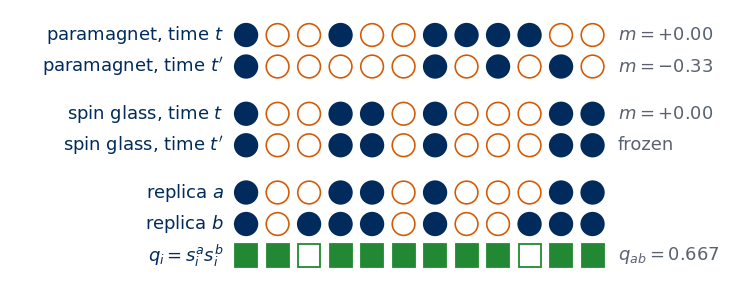

In [15]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("../beamer/figures", exist_ok=True)
    for d in ("../beamer/figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_sk_phases_configs():
    N = 12
    rng = np.random.default_rng(8)                                  # fixed seed: the same schematic every time
    para_t1, para_t2 = rng.choice([-1, 1], N), rng.choice([-1, 1], N)      # paramagnet: a new random pattern at every time
    frozen = rng.permutation(np.repeat([1, -1], N // 2))           # spin glass: a frozen random-looking pattern, m = 0
    rep_a = frozen.copy()
    rep_b = frozen.copy(); rep_b[[2, 9]] *= -1                      # second replica: same valley, two spins differ
    q_field = rep_a * rep_b                                         # overlap field q_i = s_i^a s_i^b
    rows = [(para_t1, "paramagnet, time $t$", f"$m={para_t1.mean():+.2f}$"),
            (para_t2, "paramagnet, time $t'$", f"$m={para_t2.mean():+.2f}$"),
            (frozen, "spin glass, time $t$", f"$m={frozen.mean():+.2f}$"),
            (frozen, "spin glass, time $t'$", "frozen"),
            (rep_a, "replica $a$", ""), (rep_b, "replica $b$", ""),
            (q_field, r"$q_i=s_i^a s_i^b$", rf"$q_{{ab}}={q_field.mean():.3f}$")]
    fig = plt.figure(figsize=(5.5, 2.5))
    ax = fig.add_axes([0.0, 0.0, 1.0, 1.0])
    x0, dy = 7.2, 1.0
    for r, (spins, label, note) in enumerate(rows):
        yy = -r * dy - (0.5 if r >= 2 else 0) - (0.5 if r >= 4 else 0)       # small gaps between the three groups
        for i, s in enumerate(spins):
            if r == 6:                                              # overlap field: +1 where the replicas agree
                ax.add_patch(mpatches.Rectangle((x0 + i - 0.35, yy - 0.35), 0.7, 0.7, fc=GREEN if s > 0 else "white",
                                                ec=GREEN, lw=1.0))
            else:
                draw_spin(ax, x0 + i, yy, s, r=0.36, lw=0.9)
        ax.text(x0 - 0.7, yy, label, ha="right", va="center", fontsize=10, color=NAVY)
        ax.text(x0 + N - 0.2, yy, note, ha="left", va="center", fontsize=10, color=GRAY)
    ax.set_xlim(-0.2, x0 + N + 3.3); ax.set_ylim(-8.0, 0.7); ax.set_aspect("equal"); ax.axis("off")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_sk_phases_configs()
save_sketch(fig, "sketch_sk_phase_configs.png")
plt.show()


Because the replicas are independent at fixed $J$,
$$
\begin{aligned}
\langle q_{ab}^2\rangle&=\frac1{N^2}\sum_{i,j}\langle s_i^as_j^a\rangle\langle s_i^bs_j^b\rangle\\
&=\frac1{N^2}\sum_{i,j}\langle s_is_j\rangle^2 .
\end{aligned}
$$
The global flip makes $\langle q_{ab}\rangle=0$ at finite $N$, but $\langle q_{ab}^2\rangle$ is not affected: it measures the frozen correlations.
If the system sits in one of two mirror valleys with averages $\pm\langle s_i\rangle$, then $q_{ab}=\pm q_{\rm EA}$ and $\langle q^2_{ab}\rangle=q_{\rm EA}^2$.

The full information is in the **overlap distribution** of a sample and its disorder average,
$$
P_J(q)=\big\langle\delta(q-q_{ab})\big\rangle_J,\qquad P(q)=\big[P_J(q)\big].
$$
In the paramagnet $q_{ab}$ is a sum of $N$ weakly correlated terms $\pm1/N$, so $P(q)$ is a single Gaussian peak at $q=0$ of width of order $1/\sqrt N$.
In the spin glass, by contrast, $P(q)$ has weight at $q\neq0$ that does not shrink as $N$ grows (Sections 4.5 and 5).

The **spin-glass susceptibility** collects the frozen correlations,
$$
\chi_{\rm SG}=\frac1N\sum_{i,j}\big[\langle s_is_j\rangle^2\big]=N\,\big[\langle q_{ab}^2\rangle\big],
$$
and in the paramagnet it is the width of $P(q)$: $[\langle q^2\rangle]=\chi_{\rm SG}/N$.

### 4.4 Spin-glass susceptibility
At high temperature $\chi_{\rm SG}$ can be computed by an expansion in powers of $\beta$, and the result tells us where the paramagnet ends. Write each Boltzmann factor as
$e^{\beta J_{ij}s_is_j}=\cosh(\beta J_{ij})\,(1+t_{ij}s_is_j)$ with $t_{ij}=\tanh(\beta J_{ij})\approx\beta J_{ij}$ (small, of order $1/\sqrt N$).
Expanding the product, $\langle s_is_j\rangle$ is a sum over **paths** of bonds from $i$ to $j$, each path contributing the product of its $t$'s.
Now square and average over the disorder. Cross terms between two different paths contain some coupling an odd number of times, and $[J_{kl}]=0$ removes them, so only the squares of single paths survive.
A path of length $\ell$ contributes $\prod[t^2]\approx(\beta^2J^2/N)^\ell$, and the number of paths of length $\ell$ from $i$ to $j$ through distinct intermediate sites is $(N-2)(N-3)\cdots(N-\ell)\approx N^{\ell-1}$;
summing over the end point $j$ gives another factor $N$. Therefore, to leading order in $1/N$,
$$
\begin{aligned}
\chi_{\rm SG}&=\sum_{\ell=0}^{\infty}N^{\ell}\Big(\frac{\beta^2J^2}{N}\Big)^{\ell}=\sum_{\ell=0}^\infty(\beta J)^{2\ell}\\
&=\frac{1}{1-\beta^2J^2}\qquad(T>J).
\end{aligned}
$$
The series diverges at $\beta J=1$: **the paramagnet becomes unstable at $T_c=J$.** This is the value of the SK critical temperature
(the replica solution below uses the same convention, $T_c=J$, as e.g. [Crisanti & Rizzo 2002]). SymPy checks the two ingredients, the path count and the
geometric sum; then we compare with exact enumeration.

In [16]:
N_s, l, bJ = sp.symbols("N ell betaJ", positive=True)
# number of paths of length ell from i to a fixed j through distinct intermediate sites, relative to N^(ell-1)
for ell in (1, 2, 3, 4):
    n_paths = sp.prod([N_s - k for k in range(2, ell + 1)])          # (N-2)(N-3)...(N-ell); empty product = 1 for ell = 1
    print(f"ell = {ell}: number of paths = {sp.expand(n_paths)},   ratio to N^(ell-1) -> {sp.limit(n_paths / N_s**(ell - 1), N_s, sp.oo)}")

chi_series = sp.summation((bJ**2)**l, (l, 0, sp.oo))
print("\nchi_SG = sum_l (beta J)^(2 l) =", sp.simplify(chi_series))
print("chi_SG at T = 1.5 J:", sp.nsimplify(sp.Rational(1, 1) / (1 - sp.Rational(2, 3)**2)), "=", float(1 / (1 - (2 / 3) ** 2)))

ell = 1: number of paths = 1,   ratio to N^(ell-1) -> 1
ell = 2: number of paths = N - 2,   ratio to N^(ell-1) -> 1
ell = 3: number of paths = N**2 - 5*N + 6,   ratio to N^(ell-1) -> 1
ell = 4: number of paths = N**3 - 9*N**2 + 26*N - 24,   ratio to N^(ell-1) -> 1

chi_SG = sum_l (beta J)^(2 l) = Piecewise((-1/(betaJ**2 - 1), betaJ < 1), (Sum(betaJ**(2*ell), (ell, 0, oo)), True))
chi_SG at T = 1.5 J: 9/5 = 1.7999999999999998


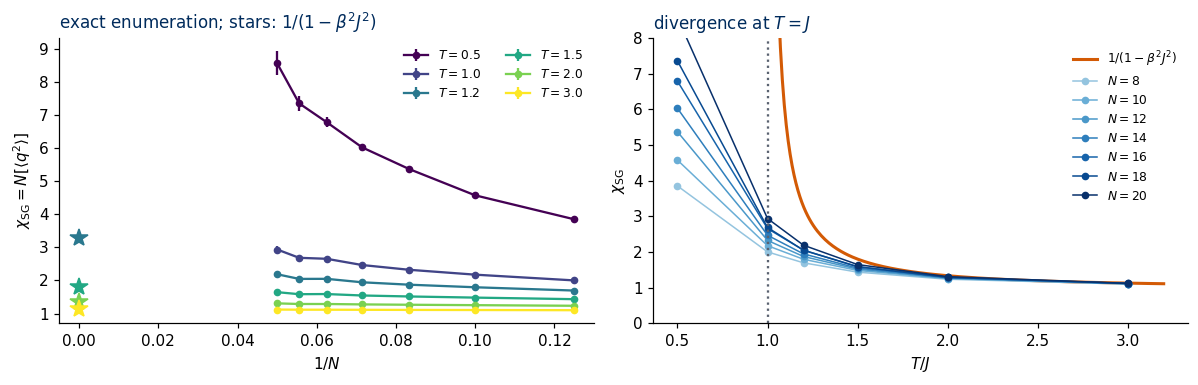

  T     chi_SG(N=20)   chi_SG(N=8)   1/(1-beta^2 J^2)
 0.50       8.578         3.854           inf
 1.00       2.939         2.002           inf
 1.20       2.189         1.695         3.273
 1.50       1.646         1.434         1.800
 2.00       1.307         1.234         1.333
 3.00       1.119         1.100         1.125


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
Ns = np.array(list(N_ENUM))
for k, T in enumerate(T_chi):
    chi = np.array([enum[N]["chi"][:, k].mean() for N in Ns])
    err = np.array([enum[N]["chi"][:, k].std() / np.sqrt(len(enum[N]["chi"])) for N in Ns])
    col = plt.cm.viridis(k / (len(T_chi) - 1))
    ax[0].errorbar(1 / Ns, chi, yerr=err, fmt="o-", ms=4, color=col, label=f"$T={T}$")
    if T > 1:
        ax[0].plot(0, 1 / (1 - 1 / T**2), "*", ms=12, color=col)
ax[0].set_xlabel("$1/N$"); ax[0].set_ylabel(r"$\chi_{\rm SG}=N[\langle q^2\rangle]$"); ax[0].set_xlim(-0.005, 0.13)
ax[0].set_title(r"exact enumeration; stars: $1/(1-\beta^2J^2)$"); ax[0].legend(frameon=False, fontsize=8, ncol=2)

TT = np.linspace(1.05, 3.2, 200)
ax[1].plot(TT, 1 / (1 - 1 / TT**2), color=DSOrange, lw=2, label=r"$1/(1-\beta^2J^2)$")
for c, N in zip(plt.cm.Blues(np.linspace(0.4, 1, len(Ns))), Ns):
    ax[1].plot(T_chi, enum[N]["chi"].mean(0), "o-", ms=4, color=c, lw=1, label=f"$N={N}$")
ax[1].axvline(T_C, color=UJGray, ls=":"); ax[1].set_ylim(0, 8); ax[1].set_xlabel("$T/J$"); ax[1].set_ylabel(r"$\chi_{\rm SG}$")
ax[1].set_title("divergence at $T=J$"); ax[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

print("  T     chi_SG(N=20)   chi_SG(N=8)   1/(1-beta^2 J^2)")
for k, T in enumerate(T_chi):
    pred = 1 / (1 - 1 / T**2) if T > 1 else np.inf
    print(f"{T:5.2f}   {enum[20]['chi'][:, k].mean():9.3f}     {enum[8]['chi'][:, k].mean():9.3f}     {pred:9.3f}")

Above $T=J$ the exact values approach the formula as $N$ grows, roughly linearly in $1/N$ (at $T=1.5$, $1.434$ for $N=8$ and $1.646$ for $N=20$, against $1.800$). At $T=J$ and below, $\chi_{\rm SG}$ keeps growing with $N$:
the correlations $\langle s_is_j\rangle^2$ no longer decay, which is the signature of freezing.

### 4.5 Exact overlap distribution
The susceptibility is only the second moment of $P(q)$; for a small system we can compute the whole distribution. For $N=12$, with all $2^{12}=4096$ configurations in a matrix `S` of shape `(4096, 12)`, the overlaps of all pairs
are the integer matrix `O = S @ S.T` of shape `(4096, 4096)` with values $Nq\in\{-12,-10,\dots,12\}$, and
$$
P_J(q)=\sum_{a,b}p_a\,p_b\,\mathbb 1[O_{ab}=Nq],
$$
a quadratic form in the Boltzmann probabilities $p$ for each of the $13$ possible values.

normalisation check, sum_q P_J(q) for the first sample: [1. 1. 1. 1.]


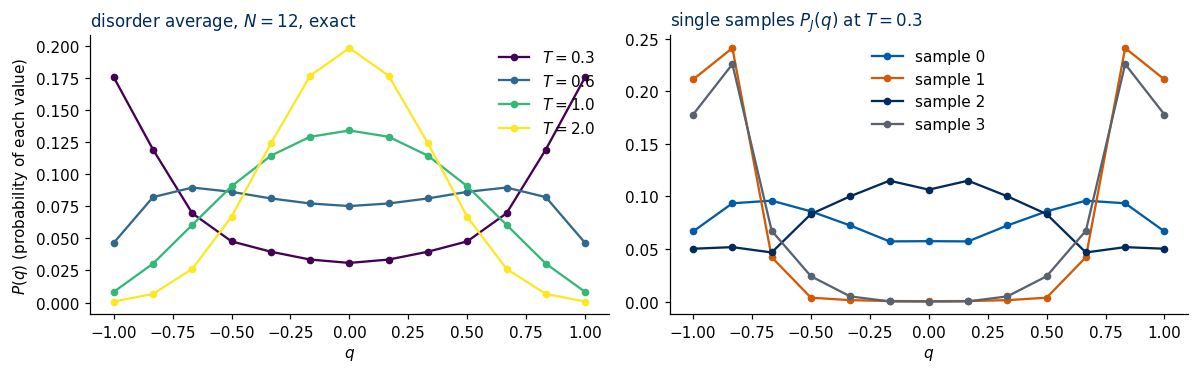

T = 0.3:  [<q^2>] = 0.6122   (a random pair of configurations has <q^2> = 1/N = 0.0833)
T = 0.6:  [<q^2>] = 0.3519   (a random pair of configurations has <q^2> = 1/N = 0.0833)
T = 1.0:  [<q^2>] = 0.1905   (a random pair of configurations has <q^2> = 1/N = 0.0833)
T = 2.0:  [<q^2>] = 0.1051   (a random pair of configurations has <q^2> = 1/N = 0.0833)


In [18]:
N_pq = 12
S_full = jnp.asarray(np.array(list(itertools.product([-1.0, 1.0], repeat=N_pq))), jnp.float32)    # (4096, 12)
O_full = (S_full @ S_full.T).astype(jnp.int8)                                                     # (4096, 4096) N q_ab
q_values = np.arange(-N_pq, N_pq + 1, 2) / N_pq                                                   # the 13 possible overlaps
T_pq = np.array([0.3, 0.6, 1.0, 2.0])

@jax.jit
def exact_Pq(J, betas, S, O):
    """Exact P_J(q) for one sample, shape (n_T, 13). S: (4096, N) all configurations, O: (4096, 4096) values N q_ab."""
    N = S.shape[1]
    E = -0.5 * jnp.sum(S * (S @ J), axis=1)                                            # (4096,)
    p = jax.nn.softmax(-betas[:, None] * E[None, :], axis=1)                          # (n_T, 4096) Boltzmann probabilities
    return jnp.stack([jnp.sum((p @ (O == v).astype(jnp.float32)) * p, axis=1)       # sum_ab p_a p_b 1[O_ab = v]
                      for v in range(-N, N + 1, 2)], axis=1)

Js12 = sk_couplings(jax.random.PRNGKey(12), 150, N_pq)
Pq_exact = np.array([np.asarray(exact_Pq(Js12[d], jnp.asarray(1 / T_pq, jnp.float32), S_full, O_full)) for d in range(150)])   # (150, n_T, 13)
print("normalisation check, sum_q P_J(q) for the first sample:", np.round(Pq_exact[0].sum(1), 6))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for k, T in enumerate(T_pq):
    ax[0].plot(q_values, Pq_exact[:, k].mean(0), "o-", ms=4, color=plt.cm.viridis(k / (len(T_pq) - 1)), label=f"$T={T}$")
ax[0].set_xlabel("$q$"); ax[0].set_ylabel("$P(q)$ (probability of each value)"); ax[0].set_title(f"disorder average, $N={N_pq}$, exact")
ax[0].legend(frameon=False)
for d, col in zip(range(4), [UJBlue, DSOrange, UJNavy, UJGray]):
    ax[1].plot(q_values, Pq_exact[d, 0], "o-", ms=4, color=col, label=f"sample {d}")
ax[1].set_xlabel("$q$"); ax[1].set_title(f"single samples $P_J(q)$ at $T={T_pq[0]}$"); ax[1].legend(frameon=False)
fig.tight_layout(); plt.show()
for k, T in enumerate(T_pq):
    q2 = (Pq_exact[:, k] * q_values**2).sum(1).mean()
    print(f"T = {T}:  [<q^2>] = {q2:.4f}   (a random pair of configurations has <q^2> = 1/N = {1 / N_pq:.4f})")

Even for $12$ spins the trend is visible. At $T=2$ the distribution is a single bump around $q=0$, and $[\langle q^2\rangle]=0.105$ is close to the value $1/N=0.083$ of unrelated configurations. At low temperature the weight moves to large $|q|$
($[\langle q^2\rangle]=0.612$ at $T=0.3$; the replicas are frozen in the same or mirror valleys), but it is spread over the whole interval, and the individual samples differ strongly from each other:
some have most weight at $|q|=1$ (one dominant pair of ground states), others at intermediate $|q|$ (several low-lying states that differ in a few spins).
Section 5 repeats this for $N$ up to $128$ with Monte Carlo.

### 4.6 Replica-symmetric solution
Sherrington and Kirkpatrick computed $[\ln Z]$ with the **replica trick** [Sherrington & Kirkpatrick 1975]. The identity $\ln Z=\lim_{n\to0}(Z^n-1)/n$ replaces
the hard average of a logarithm by averages of $Z^n$, the partition function of $n$ replicas with the same couplings, which are Gaussian integrals as in
Section 2.4. Averaging couples the replicas through the overlaps $q_{ab}$. The simplest assumption, **replica symmetry** (RS), is that all overlaps are equal,
$q_{ab}=q$. We do not repeat the calculation; its result has a transparent meaning.

The central result is a self-consistency equation for $q$, which can be understood directly. In a frozen state, spin $i$ feels the field of the other spins with $i$ itself removed (the *cavity field*),
$h_i=\sum_jJ_{ij}\langle s_j\rangle$. It is a sum of $N$ terms with random signs, hence Gaussian, with variance $\sum_jJ_{ij}^2\langle s_j\rangle^2\approx J^2q$.
The spin then has $\langle s_i\rangle=\tanh(\beta h_i)$, and averaging $\langle s_i\rangle^2$ over the Gaussian field closes the loop:
$$
q=\int\!Dz\;\tanh^2\!\big(\beta J\sqrt q\,z\big),\qquad Dz=\frac{dz}{\sqrt{2\pi}}e^{-z^2/2},
$$
$$
\begin{aligned}
-\beta f_{\rm RS}&=\frac{\beta^2J^2}{4}(1-q)^2+\int\!Dz\,\ln\!\big(2\cosh\beta J\sqrt q\,z\big),\\
u_{\rm RS}&=-\frac{\beta J^2}{2}\big(1-q^2\big).
\end{aligned}
$$
At $q=0$ this is exactly the annealed result of Section 2.4. (The same expression is the constant-$q$ case of Parisi's free energy given in [Crisanti & Rizzo 2002].)

Linearising the equation gives the critical temperature. For small $q$, $\tanh^2x\approx x^2$ and $\int Dz\,z^2=1$, so $q\approx\beta^2J^2q$: a non-zero solution
appears exactly when $\beta J>1$. Expanding one order further gives $q\approx\tau$ with $\tau=1-T/J$: the Edwards–Anderson order parameter grows linearly
below $T_c$. SymPy does the expansion.

In [19]:
a, z, q, bet, tau = sp.symbols("a z q beta tau", positive=True)
Dz = sp.exp(-z**2 / 2) / sp.sqrt(2 * sp.pi)
series = sp.series(sp.tanh(a * z)**2, a, 0, 7).removeO()                         # tanh^2(a z) to order a^6
G = sp.expand(sum(sp.integrate(term * Dz, (z, -sp.oo, sp.oo)) for term in sp.Add.make_args(sp.expand(series))))
print("int Dz tanh^2(a z) =", G, "+ O(a^8)")

rhs = G.subs(a, bet * sp.sqrt(q))                                                   # J = 1: a^2 = beta^2 q
print("RS equation q = ", sp.expand(rhs))
reduced = sp.expand((rhs - q) / q).series(q, 0, 2).removeO()                      # divide out the trivial root q = 0, keep O(q)
print("(rhs - q)/q =", reduced)
q_nonzero = sp.solve(sp.Eq(reduced, 0), q)[0]
print("non-zero solution to leading order: q =", sp.simplify(q_nonzero))
print("with T = 1 - tau:  q =", sp.series(q_nonzero.subs(bet, 1 / (1 - tau)), tau, 0, 2))

int Dz tanh^2(a z) = 17*a**6/3 - 2*a**4 + a**2 + O(a^8)
RS equation q =  17*beta**6*q**3/3 - 2*beta**4*q**2 + beta**2*q
(rhs - q)/q = -2*beta**4*q + beta**2 - 1


non-zero solution to leading order: q = (beta**2 - 1)/(2*beta**4)
with T = 1 - tau:  q = tau + O(tau**2)


The expansion confirms $q=\tau+O(\tau^2)$ just below $T_c$. Further from $T_c$ we need the full RS solution, which we find numerically. The Gaussian integrals are one-dimensional; we evaluate them with `scipy.integrate.quad` on $z>0$ (the integrands are even),
and find $q(T)$ as the root of $q-\int Dz\tanh^2(\beta\sqrt q z)$ with `brentq`. From $q$ we get $f_{\rm RS}$, $u_{\rm RS}$ and the entropy $s_{\rm RS}=\beta(u_{\rm RS}-f_{\rm RS})$.

In [20]:
from scipy.integrate import quad
from scipy.optimize import brentq

phi = lambda z: np.exp(-z**2 / 2) / np.sqrt(2 * np.pi)
gauss_avg = lambda g: 2 * quad(lambda z: phi(z) * g(z), 0, 12, limit=400)[0]          # int Dz g(z) for an even g

def rs_solution(T):
    """Replica-symmetric q, f, u, s at temperature T (J = 1)."""
    b = 1 / T
    F = lambda q: q - gauss_avg(lambda z: np.tanh(b * np.sqrt(q) * z) ** 2)
    q = brentq(F, 1e-10, 1.0) if T < 1 else 0.0
    log2cosh = lambda x: np.abs(x) + np.log1p(np.exp(-2 * np.abs(x)))               # ln(2 cosh x) without overflow
    mbf = b**2 * (1 - q) ** 2 / 4 + gauss_avg(lambda z: log2cosh(b * np.sqrt(q) * z))
    u = -b * (1 - q**2) / 2
    return q, -T * mbf, u, mbf + b * u

T_rs = np.array([0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99, 1.0, 1.2, 1.5])
rs = np.array([rs_solution(T) for T in T_rs])                                   # columns q, f, u, s
print("   T      q_RS      f_RS      u_RS      s_RS")
for T, (qq, ff, uu, ss) in zip(T_rs, rs):
    print(f"{T:5.2f}  {qq:8.4f}  {ff:8.4f}  {uu:8.4f}  {ss:8.4f}")

# check: u = d(beta f)/d beta by a central finite difference at T = 0.5
h_b = 1e-4
bf = lambda b: rs_solution(1 / b)[1] * b
print(f"\nT = 0.5: u_RS formula {rs_solution(0.5)[2]:.6f},  finite difference d(beta f)/d beta {(bf(2 + h_b) - bf(2 - h_b)) / (2 * h_b):.6f}")
print(f"q_RS at T = 0.99 (tau = 0.01): {rs_solution(0.99)[0]:.5f}   (leading order q = tau)")

   T      q_RS      f_RS      u_RS      s_RS
 0.02    0.9839   -0.7948   -0.7978   -0.1485
 0.05    0.9593   -0.7906   -0.7972   -0.1321
 0.10    0.9171   -0.7847   -0.7951   -0.1039
 0.20    0.8280   -0.7772   -0.7861   -0.0445
 0.30    0.7333   -0.7759   -0.7705    0.0180
 0.40    0.6338   -0.7809   -0.7479    0.0824
 0.50    0.5304   -0.7924   -0.7187    0.1474
 0.60    0.4243   -0.8104   -0.6833    0.2117
 0.70    0.3167   -0.8347   -0.6427    0.2743
 0.80    0.2089   -0.8651   -0.5977    0.3343
 0.90    0.1027   -0.9014   -0.5497    0.3908
 0.95    0.0507   -0.9216   -0.5250    0.4175
 0.99    0.0100   -0.9387   -0.5050    0.4381
 1.00    0.0000   -0.9431   -0.5000    0.4431
 1.20    0.0000   -1.0401   -0.4167    0.5195
 1.50    0.0000   -1.2064   -0.3333    0.5820



T = 0.5: u_RS formula -0.718709,  finite difference d(beta f)/d beta -0.718709
q_RS at T = 0.99 (tau = 0.01): 0.01003   (leading order q = tau)


The table shows two features of the RS solution. First, the RS energy at $T\to0$ approaches a finite value, close to $-0.80\,J$. This value can be derived: for $T\to0$, $1-q=\int Dz\,\mathrm{sech}^2(\beta\sqrt q z)\approx\frac{T}{\sqrt q}\,\frac{1}{\sqrt{2\pi}}\int dx\,\mathrm{sech}^2x$,
because $\mathrm{sech}^2$ is concentrated near $z=0$ where $Dz\approx dz/\sqrt{2\pi}$. Then $u_{\rm RS}=-\frac\beta2(1-q)(1+q)\to-(1-q)\beta$, which SymPy evaluates below.
Second, the RS **entropy becomes negative** at low temperature (below about $T=0.3$ in the table), which is impossible for Ising spins. The RS solution is therefore wrong below $T_c$: de Almeida and Thouless showed that it is
unstable for all $T<J$ in zero field [de Almeida & Thouless 1978].

In [21]:
xx, T_s = sp.symbols("x T", positive=True)
F = sp.tanh(xx)                                                         # antiderivative of sech^2
print("d tanh(x)/dx - sech^2(x) =", sp.simplify(sp.diff(F, xx) - sp.sech(xx)**2))
int_sech2 = sp.limit(F, xx, sp.oo) - sp.limit(F.subs(xx, -xx), xx, sp.oo)   # tanh(+oo) - tanh(-oo)
one_minus_q = T_s / sp.sqrt(2 * sp.pi) * int_sech2                       # q -> 1 at T -> 0
u0 = sp.limit(-(1 / T_s) / 2 * one_minus_q * (2 - one_minus_q), T_s, 0)
print("int sech^2(x) dx =", int_sech2)
print("1 - q ~", one_minus_q, "   ->   u_RS(T -> 0) =", u0, "=", sp.N(u0, 6))
print(f"numerical RS energy at T = 0.02: {rs[0, 2]:.4f};  RS entropy at T = 0.02: {rs[0, 3]:.4f} (negative)")

d tanh(x)/dx - sech^2(x) = 0
int sech^2(x) dx = 2
1 - q ~ sqrt(2)*T/sqrt(pi)    ->   u_RS(T -> 0) = -sqrt(2)/sqrt(pi) = -0.797885
numerical RS energy at T = 0.02: -0.7978;  RS entropy at T = 0.02: -0.1485 (negative)


The zero-temperature limit is $u_{\rm RS}=-\sqrt{2/\pi}=-0.7979$, and the numerical RS energy at $T=0.02$, $-0.7978$, has nearly reached it, while the RS entropy there is $-0.1485$.

### 4.7 Parisi's solution
Parisi found the correct solution by breaking the replica symmetry in infinitely many steps [Parisi 1979; Parisi 1980]; his free energy was later proved
rigorously to be exact [Talagrand 2006]. We do not derive it, but its main results have a clear meaning, and the rest of the notebook tests them.

The order parameter becomes a function. Instead of one number $q$, the solution is a non-decreasing function $q(x)$, $0\le x\le1$, whose inverse defines the
overlap distribution, $P(q)=dx/dq$ [Parisi 1983; Crisanti & Rizzo 2002]. Its physical content is that below $T_c$ the Boltzmann distribution of a large sample splits into many "pure states" (valleys) $\alpha$ with weights $w_\alpha$.
Two replicas fall into states $\alpha,\beta$ independently, and $P_J(q)=\sum_{\alpha\beta}w_\alpha w_\beta\,\delta(q-q_{\alpha\beta})$. Pairs in the same state
give the self-overlap $q_{\rm EA}$; pairs in different states give smaller overlaps. Hence $P(q)$ has **peaks at $\pm q_{\rm EA}$ and a continuous
part in between**, not a single pair of delta functions as in a ferromagnet [Mézard, Parisi & Virasoro 1986]. The weights $w_\alpha$ differ from sample to sample, so $P_J(q)$ differs between samples even for large $N$.

The cartoons below compare the overlap distributions met so far, for $N\to\infty$; they are schematic shapes, not computed curves. In the paramagnet two replicas are unrelated and $P(q)$ is a single delta function at $q=0$. A ferromagnet, and the Mattis model of Section 7, has two mirror states and two delta peaks at $\pm m^2$. The replica-symmetric ansatz of Section 4.6 predicts the same shape, two delta peaks at $\pm q$. Parisi's solution adds a continuous part between the peaks at $\pm q_{\rm EA}$, the Edwards–Anderson order parameter of Section 4.2: replicas that fall into different valleys have overlaps smaller than $q_{\rm EA}$. Section 5.6 measures $P(q)$ at finite $N$.

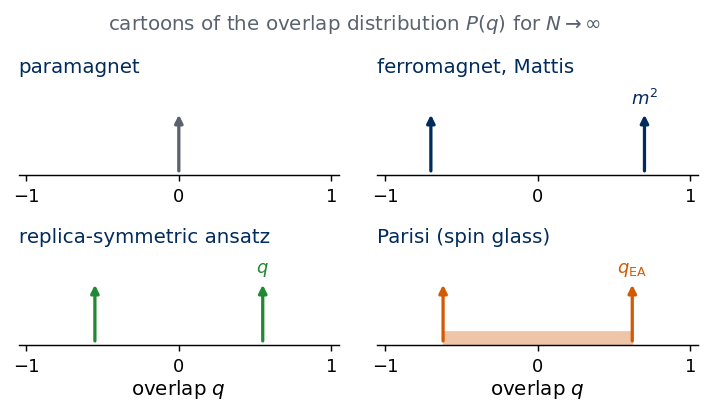

In [22]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("../beamer/figures", exist_ok=True)
    for d in ("../beamer/figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def sketch_overlap_distributions():
    # cartoons of P(q) for N -> infinity: delta functions drawn as arrows, continuous parts as filled curves
    fig, axes = plt.subplots(2, 2, figsize=(5.5, 3.1))
    fig.subplots_adjust(left=0.03, right=0.98, bottom=0.16, top=0.81, wspace=0.12, hspace=0.85)
    q = np.linspace(-1, 1, 400)
    def delta(ax, q0, h=1.0, color=NAVY):
        ax.annotate("", xy=(q0, h), xytext=(q0, 0), arrowprops=dict(arrowstyle="-|>", color=color, lw=1.8, mutation_scale=9))
    a = axes[0, 0]                                                  # paramagnet: a single delta at q = 0 (width 1/sqrt N at finite N)
    delta(a, 0.0, color=GRAY)
    a.set_title("paramagnet", fontsize=11, color=NAVY)
    a = axes[0, 1]                                                  # ferromagnet or Mattis model: two deltas at +-m^2
    delta(a, 0.7); delta(a, -0.7)
    a.text(0.7, 1.05, "$m^2$", ha="center", va="bottom", fontsize=10, color=NAVY)
    a.set_title("ferromagnet, Mattis", fontsize=11, color=NAVY)
    a = axes[1, 0]                                                  # replica-symmetric ansatz: two deltas at +-q
    delta(a, 0.55, color=GREEN); delta(a, -0.55, color=GREEN)
    a.text(0.55, 1.05, "$q$", ha="center", va="bottom", fontsize=10, color=GREEN)
    a.set_title("replica-symmetric ansatz", fontsize=11, color=NAVY)
    a = axes[1, 1]                                                  # Parisi: deltas at +-q_EA and a continuous plateau between
    delta(a, 0.62, color=ORANGE); delta(a, -0.62, color=ORANGE)
    plateau = np.where(np.abs(q) < 0.62, 0.22, 0.0)
    a.fill_between(q, plateau, color=ORANGE, alpha=0.35, lw=0)
    a.text(0.62, 1.05, r"$q_{\rm EA}$", ha="center", va="bottom", fontsize=10, color=ORANGE)
    a.set_title("Parisi (spin glass)", fontsize=11, color=NAVY)
    for a in axes.flat:
        a.set_xlim(-1.05, 1.05); a.set_ylim(0, 1.45); a.set_yticks([]); a.set_xticks([-1, 0, 1])
        a.spines[["left", "top", "right"]].set_visible(False)
    for a in axes[1]:
        a.set_xlabel("overlap $q$", labelpad=1)
    fig.text(0.5, 0.985, "cartoons of the overlap distribution $P(q)$ for $N\\to\\infty$", ha="center", va="top", fontsize=11, color=GRAY)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_overlap_distributions()
save_sketch(fig, "sketch_sk_Pq.png")
plt.show()


The critical temperature remains $T_c=J$, the same as in the RS calculation and in the high-temperature expansion. The ground-state energy per spin for $N\to\infty$ is $e_0=-0.76321\pm0.00003$ [Crisanti & Rizzo 2002], in agreement with Parisi's estimate
$-0.7633\pm0.0001$ [Parisi 1980; as quoted in Crisanti & Rizzo 2002], above the RS value $-\sqrt{2/\pi}\approx-0.798$.

The table lists these statements and the sections of this notebook in which they are checked.

| statement | checked in this notebook |
|---|---|
| paramagnet: single peak of $P(q)$ at $0$, width $\propto1/\sqrt N$ | Section 5.6 |
| $\chi_{\rm SG}=1/(1-\beta^2J^2)$ above $T_c$, divergence at $T_c=J$ | Sections 4.4 and 5.7 |
| broad $P(q)$ with weight between the peaks below $T_c$ | Sections 4.5 and 5.6 |
| $P_J(q)$ differs from sample to sample | Sections 4.5 and 5.6 |
| crossing of the Binder cumulants, drifting towards $T_c=J$; scaling collapse with $T_c=J$ | Section 5.7 |
| $e_0\approx-0.7632$ | Section 6.1 |

<hr/>
## 5. The spin-glass transition

### 5.1 Parallel tempering
Testing these predictions requires equilibrium samples at low temperature, and this is where spin glasses are hard. Below $T_c$ the free-energy landscape has many valleys separated by barriers that grow with $N$. A Metropolis chain at a fixed low temperature (single spin flips,
accepted with probability $\min(1,e^{-\beta\Delta E})$) stays in one valley for a very long time: the samples it produces are correct *locally* but do not
represent the relative weights of the valleys, and the estimate of $P(q)$, which is all about different valleys, is wrong. Section 6.3 shows this directly.

The cartoon below illustrates the difficulty on a one-dimensional caricature of configuration space. The energy has many local minima, the metastable states of Section 6.2, separated by barriers. At low temperature a chain of single spin flips stays in one valley; at high temperature it crosses the barriers easily, but it does not settle in the deep valleys.

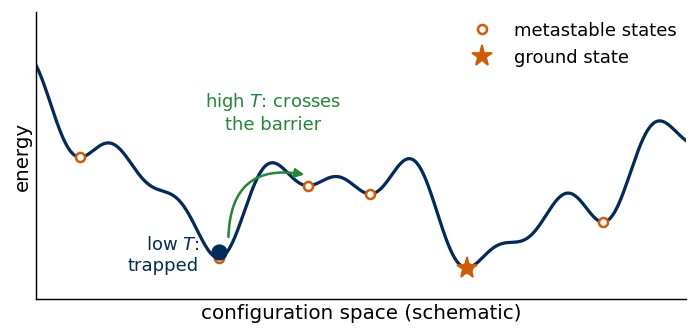

In [23]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("../beamer/figures", exist_ok=True)
    for d in ("../beamer/figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def sketch_rugged_landscape():
    # a one-dimensional cartoon of the energy landscape over configuration space
    x = np.linspace(0, 10, 1000)
    E = (0.55 * np.cos(1.3 * x) + 0.35 * np.cos(3.1 * x + 1.0) + 0.22 * np.cos(5.3 * x + 0.4)
         + 0.03 * (x - 6.2) ** 2)
    fig, ax = plt.subplots(figsize=(5.5, 2.6))
    fig.subplots_adjust(left=0.08, right=0.99, bottom=0.12, top=0.97)
    ax.plot(x, E, color=NAVY, lw=1.8)
    # local minima: metastable states; the lowest one is the ground state
    i_min = np.where((E[1:-1] < E[:-2]) & (E[1:-1] < E[2:]))[0] + 1
    i_gs = i_min[np.argmin(E[i_min])]
    ax.plot(x[i_min], E[i_min], "o", ms=5, mfc="white", mec=ORANGE, mew=1.4, zorder=5, label="metastable states")
    ax.plot(x[i_gs], E[i_gs], "*", ms=12, color=ORANGE, zorder=6, label="ground state")
    # a configuration trapped at low temperature, and a high-temperature path over a barrier
    k = i_min[1]
    ax.plot(x[k], E[k] + 0.09, "o", ms=8, color=NAVY, zorder=7)
    ax.text(x[k] - 0.3, E[k] + 0.05, "low $T$:\ntrapped", ha="right", va="center", fontsize=10, color=NAVY)
    a, b = i_min[1], i_min[2]
    top = a + np.argmax(E[a:b])
    ax.annotate("", xy=(x[b], E[b] + 0.15), xytext=(x[a] + 0.15, E[a] + 0.25),
                arrowprops=dict(arrowstyle="-|>", color=GREEN, lw=1.4, mutation_scale=10,
                                connectionstyle="arc3,rad=-0.6"))
    ax.text(x[top], E[top] + 0.42, "high $T$: crosses\nthe barrier", ha="center", va="bottom", fontsize=10, color=GREEN)
    ax.set_xlim(0, 10); ax.set_ylim(E.min() - 0.45, E.max() + 0.75)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel("configuration space (schematic)", labelpad=2); ax.set_ylabel("energy", labelpad=2)
    ax.legend(loc="upper right", fontsize=10, frameon=False, borderaxespad=0.1)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_rugged_landscape()
save_sketch(fig, "sketch_sk_landscape.png")
plt.show()


**Parallel tempering** (also called *replica exchange* or *exchange Monte Carlo*) [Swendsen & Wang 1986; Hukushima & Nemoto 1996; Earl & Deem 2005] runs $K$ copies
of the same sample at temperatures $T_1<T_2<\dots<T_K$. The joint distribution of the copies is the product of their Boltzmann distributions,
$$
\Pi(\boldsymbol s_1,\dots,\boldsymbol s_K)=\prod_{k=1}^K\frac{e^{-\beta_kE(\boldsymbol s_k)}}{Z(\beta_k)} .
$$
Two kinds of moves alternate. In a local move every copy performs one Metropolis sweep at its own temperature; each copy is updated with a move that preserves its own Boltzmann distribution, so $\Pi$ is preserved.
In an exchange move we propose, for neighbouring temperatures $k,k+1$, to **swap** the two configurations, and accept with probability
$$
\min\Big(1,\ \exp\big[(\beta_k-\beta_{k+1})(E_k-E_{k+1})\big]\Big),
$$
where $E_k$ is the energy of the configuration currently at temperature $T_k$. This is the Metropolis rule for the swap: the ratio
$\Pi(\text{after})/\Pi(\text{before})$ equals the exponential (SymPy below), so detailed balance holds and $\Pi$ is preserved.

The exchanges let a configuration do a random walk in temperature. At high temperature it crosses barriers easily; when it comes back down it can land
in a different valley. The swap is accepted often when the energy histograms of neighbouring temperatures overlap, which sets how dense the temperature grid must be.
For the replica overlap we need **two independent parallel-tempering simulations of the same sample** (replicas $a$ and $b$), each with its own $K$ copies.

The sketch below shows the scheme for $K=4$ temperatures: every copy is updated by Metropolis sweeps at its own temperature, and copies at neighbouring temperatures propose to exchange their configurations with the acceptance probability above.

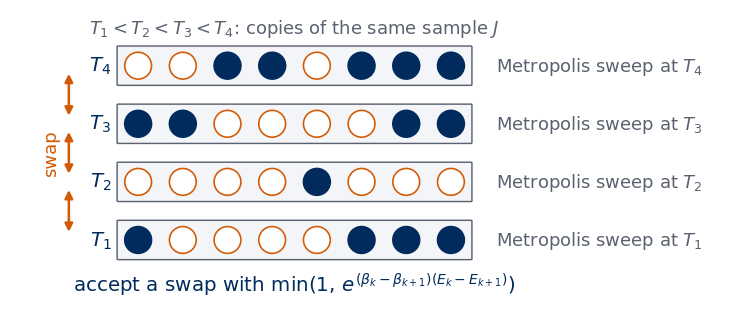

In [24]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("../beamer/figures", exist_ok=True)
    for d in ("../beamer/figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def draw_spin(ax, x, y, s, r=0.26, sign=False, alpha=1.0, fs=10, lw=1.3):
    # one Ising spin at (x, y): navy disc for s = +1, white disc with orange rim for s = -1 (optionally with "+" / "-")
    face, edge, txt = (NAVY, NAVY, "white") if s > 0 else ("white", ORANGE, ORANGE)
    ax.add_patch(mpatches.Circle((x, y), r, fc=face, ec=edge, lw=lw, alpha=alpha, zorder=4))
    if sign:
        ax.text(x, y, "+" if s > 0 else "−", color=txt, ha="center", va="center", alpha=alpha,
                fontsize=fs, fontweight="bold", zorder=5)

def draw_bond(ax, p, q, broken=False, lw=1.5, alpha=1.0, color=None, cross=True):
    # bond between points p and q: solid blue if satisfied, dashed purple with a cross if broken
    c = color or (PURPLE if broken else BLUE)
    ax.plot([p[0], q[0]], [p[1], q[1]], color=c, lw=lw, ls=(0, (2.5, 1.5)) if broken else "-",
            alpha=alpha, solid_capstyle="round", zorder=2)
    if broken and cross:
        ax.plot((p[0] + q[0]) / 2, (p[1] + q[1]) / 2, marker="x", ms=3.5 * lw, mew=lw * 0.9, color=c, alpha=alpha, zorder=3)

def sketch_parallel_tempering():
    K, N = 4, 8                                                     # K temperatures, N spins per copy (schematic)
    rng = np.random.default_rng(3)
    fig = plt.figure(figsize=(5.5, 2.7))
    ax = fig.add_axes([0.0, 0.0, 1.0, 1.0])
    x0 = 2.6                                                        # first spin of each copy
    for k in range(K):
        y = 1.3 * k
        ax.text(x0 - 0.6, y, f"$T_{k + 1}$", ha="right", va="center", fontsize=11, color=NAVY)
        ax.add_patch(mpatches.FancyBboxPatch((x0 - 0.45, y - 0.42), N - 0.1, 0.84, boxstyle="round,pad=0.02",
                                             fc="#F3F5F8", ec=GRAY, lw=0.8))
        for i, s in enumerate(rng.choice([-1, 1], N)):              # one configuration per temperature
            draw_spin(ax, x0 + i, y, s, r=0.3, lw=0.9)
        ax.text(x0 + N, y, "Metropolis sweep at $T_{%d}$" % (k + 1), ha="left", va="center", fontsize=10, color=GRAY)
    for k in range(K - 1):                                          # proposed swaps between neighbouring temperatures
        y = 1.3 * k
        ax.annotate("", xy=(x0 - 1.55, y + 1.2), xytext=(x0 - 1.55, y + 0.1),
                    arrowprops=dict(arrowstyle="<|-|>", color=ORANGE, lw=1.4, mutation_scale=9))
    ax.text(x0 - 1.75, 1.3 * (K - 1) / 2, "swap", ha="right", va="center", fontsize=10, color=ORANGE, rotation=90)
    ax.text(x0 + N / 2 - 0.5, -1.0, r"accept a swap with $\min\left(1,\,e^{(\beta_k-\beta_{k+1})(E_k-E_{k+1})}\right)$",
            ha="center", va="center", fontsize=11, color=NAVY)
    ax.text(x0 + N / 2 - 0.5, 1.3 * (K - 1) + 0.85, r"$T_1<T_2<T_3<T_4$: copies of the same sample $J$", ha="center",
            va="center", fontsize=10, color=GRAY)
    ax.set_xlim(-0.2, x0 + N + 5.2); ax.set_ylim(-1.5, 1.3 * (K - 1) + 1.2); ax.set_aspect("equal"); ax.axis("off")
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_parallel_tempering()
save_sketch(fig, "sketch_sk_tempering.png")
plt.show()


In [25]:
bk, bk1, Ek, Ek1 = sp.symbols("beta_k beta_k1 E_k E_k1", real=True)
weight = lambda E_at_k, E_at_k1: sp.exp(-bk * E_at_k - bk1 * E_at_k1)        # the two factors of Pi that change
ratio = sp.simplify(weight(Ek1, Ek) / weight(Ek, Ek1))                          # after the swap / before the swap
print("Pi(after) / Pi(before) =", ratio)
print("equals exp[(beta_k - beta_k1)(E_k - E_k1)]:", sp.simplify(ratio - sp.exp((bk - bk1) * (Ek - Ek1))) == 0)

Pi(after) / Pi(before) = exp(E_k*beta_k - E_k*beta_k1 - E_k1*beta_k + E_k1*beta_k1)
equals exp[(beta_k - beta_k1)(E_k - E_k1)]: True


### 5.2 Implementation
One simulation handles $D$ disorder samples, $2$ replicas and $K$ temperatures at once. For one sample the $C=2K$ chains (replica $r$, temperature slot $k$,
column $c=rK+k$) are the **columns of a matrix**, and `jax.vmap` maps the per-sample code over the $D$ samples. The arrays are:

| array | shape | meaning |
|---|---|---|
| `J` | `(D, N, N)` | couplings of the $D$ samples |
| `s` | `(D, N, 2, K)` | spins: sample $d$, spin $i$, replica $r\in\{a,b\}$, temperature slot $k$ (reshaped to `(D, N, C)` for the sweep) |
| `h` | `(D, N, 2, K)` | local fields $h_i=\sum_jJ_{ij}s_j$ of every chain, kept up to date |
| `beta` | `(K,)` | inverse temperatures, the same for every sample and replica; `beta_c = tile(beta, 2)` has shape `(C,)` |
| `lab` | `(D, 2, K)` | label of the configuration in each temperature slot (to follow its walk in temperature) |

All spins of the SK model are coupled to each other, so two spins cannot be flipped simultaneously: the energy change of one flip depends on all
other spins. A sweep therefore visits the spins one after another. After a flip of spin $i$ by $\Delta s_i=-2s_i$ every local field changes, $h_j\to h_j+J_{ji}\Delta s_i$,
which is $O(N)$ work per flip and $O(N^2)$ per sweep. Done literally, spin by spin, this reads and writes the whole field array $N$ times per sweep. We organise the same
sequential sweep in **blocks** of $b=16$ spins. Inside a block the spins are visited one by one, and each flip updates only the fields of the $b$ spins of the block (a small `(b, C)` array, couplings `J_bb` of shape `(b, b)`).
After the block, the fields of all $N$ spins are updated at once by one matrix product, $h\leftarrow h+J_{:,\text{block}}\,\Delta s_{\text{block}}$, with shapes `(N, b) @ (b, C)`.
Every spin still sees the exact current field when it is visited, so this is exactly the sequential Metropolis sweep, with the expensive part done as matrix products.

In the exchange step, for one sample and one replica, the $K$ configurations are permuted: slot $k$ receives the configuration from slot $k+1$ and vice versa if the swap
is accepted. Even pairs $(0,1),(2,3),\dots$ and odd pairs $(1,2),(3,4),\dots$ alternate between sweeps, so the attempted swaps never overlap.

In [26]:
from math import gcd

def sweep_sample(s, h, J, beta_c, u, block):
    """One sequential Metropolis sweep of all chains of one sample.
    s, h: (N, C) spins and local fields, one chain per column; J: (N, N); beta_c: (C,) inverse temperature of each chain;
    u: (N, C) uniform random numbers. Spins are visited in the order i = 0, ..., N-1, in blocks of `block` spins."""
    N, C = s.shape
    thr = -jnp.log(u) / (2.0 * beta_c)                             # (N, C): flip spin i iff s_i h_i < thr_i, i.e. u < exp(-2 beta s_i h_i)
    def do_block(kb, carry):
        s, h = carry
        i0 = kb * block
        s_old = lax.dynamic_slice_in_dim(s, i0, block, 0)          # (b, C) spins of the block
        hb = lax.dynamic_slice_in_dim(h, i0, block, 0)             # (b, C) their fields at the start of the block
        tb = lax.dynamic_slice_in_dim(thr, i0, block, 0)           # (b, C) acceptance thresholds
        J_cols = lax.dynamic_slice_in_dim(J, i0, block, 1)         # (N, b) couplings of every spin to the block
        J_bb = lax.dynamic_slice_in_dim(J_cols, i0, block, 0)      # (b, b) couplings inside the block
        rows = []
        for j in range(block):                                     # sequential inside the block (unrolled by jit)
            sj = s_old[j]
            accept = sj * hb[j] < tb[j]                            # Metropolis rule, Delta E = 2 s_j h_j
            d = jnp.where(accept, -2.0 * sj, 0.0)                  # (C,) change of s_j, 0 if rejected
            hb = hb + J_bb[:, j:j + 1] * d[None, :]                # fields of the block spins after this flip
            rows.append(sj + d)
        s_new = jnp.stack(rows)                                    # (b, C)
        s = lax.dynamic_update_slice_in_dim(s, s_new, i0, 0)
        h = h + J_cols @ (s_new - s_old)                           # all N fields, one matrix product per block
        return s, h
    return lax.fori_loop(0, N // block, do_block, (s, h))

def swap_moves(s, h, lab, E, beta, u, parity):
    """Exchange moves for all samples and replicas. s, h: (D, N, 2, K); lab, E: (D, 2, K); beta: (K,); u: (D, 2, K-1).
    Pairs (k, k+1) with k % 2 == parity are attempted; returns the permuted arrays and the accepted swaps (D, 2, K-1)."""
    K = beta.shape[0]
    log_ratio = (beta[:-1] - beta[1:]) * (E[..., :-1] - E[..., 1:])            # (D, 2, K-1)
    acc = (jnp.log(u) < log_ratio) & (jnp.arange(K - 1) % 2 == parity)
    pad = jnp.zeros(acc.shape[:-1] + (1,), bool)
    up = jnp.concatenate([acc, pad], -1).astype(jnp.int32)                     # slot k takes from k+1
    down = jnp.concatenate([pad, acc], -1).astype(jnp.int32)                   # slot k+1 takes from k
    perm = jnp.arange(K) + up - down                                           # (D, 2, K)
    take = lambda a: jnp.take_along_axis(a, perm[:, None], axis=3)             # permute the K axis of (D, N, 2, K)
    return take(s), take(h), jnp.take_along_axis(lab, perm, 2), jnp.take_along_axis(E, perm, 2), acc

@partial(jax.jit, static_argnames=("n_equil", "n_save", "n_meas", "meas_every", "use_swaps"))
def parallel_tempering(J, s0, beta, key, n_equil, n_save, n_meas, meas_every, use_swaps=True):
    """Parallel tempering for D samples x 2 replicas x K temperatures; s0: (D, 2, K, N) initial spins.
    Equilibration: n_equil sweeps. Production: n_save blocks of n_meas measurements, one every meas_every sweeps;
    one configuration per slot is stored at the end of every block. Returns a dict of arrays (shapes in the comments)."""
    D, R, K, N = s0.shape
    C = R * K
    sweep_all = jax.vmap(partial(sweep_sample, block=gcd(N, 16)), in_axes=(0, 0, 0, None, 0))   # over the D samples
    beta_c = jnp.tile(beta, R)                                                  # (C,) column c = r K + k
    s_init = jnp.transpose(s0, (0, 3, 1, 2))                                   # (D, N, 2, K)
    h_init = jnp.einsum("dij,djrk->dirk", J, s_init)
    carry0 = dict(s=s_init, h=h_init, lab=jnp.broadcast_to(jnp.arange(K), (D, R, K)),
                  emin=jnp.full((D, R), jnp.inf), smin=s0[:, :, 0], acc=jnp.zeros(K - 1), t=0, key=key)

    def one_sweep(c, _):
        key, k1, k2 = jax.random.split(c["key"], 3)
        s, h = sweep_all(c["s"].reshape(D, N, C), c["h"].reshape(D, N, C), J, beta_c, jax.random.uniform(k1, (D, N, C)))
        s, h = s.reshape(D, N, R, K), h.reshape(D, N, R, K)
        E = -0.5 * jnp.sum(s * h, axis=1)                                      # (D, 2, K) energies
        lab, acc = c["lab"], jnp.zeros((D, R, K - 1), bool)
        if use_swaps:
            s, h, lab, E, acc = swap_moves(s, h, lab, E, beta, jax.random.uniform(k2, (D, R, K - 1)), c["t"] % 2)
        k_low = jnp.argmin(E, -1)                                              # (D, 2) lowest-energy slot
        s_low = jnp.take_along_axis(s, k_low[:, None, :, None], axis=3)[..., 0]   # (D, N, 2)
        better = E.min(-1) < c["emin"]
        q = jnp.mean(s[:, :, 0] * s[:, :, 1], axis=1)                          # (D, K) overlaps of the two replicas
        new = dict(s=s, h=h, lab=lab, emin=jnp.where(better, E.min(-1), c["emin"]),
                   smin=jnp.where(better[..., None], jnp.swapaxes(s_low, 1, 2), c["smin"]),
                   acc=c["acc"] + acc.sum((0, 1)), t=c["t"] + 1, key=key)
        trace = (E.mean((0, 1)) / N, (q**2).mean(0), lab[0, 0].astype(jnp.int8))   # [E]/N (K,), [q^2] (K,), labels (K,)
        return new, trace

    def measure(c, _):
        c, tr = lax.scan(one_sweep, c, None, length=meas_every)
        q_int = jnp.sum(c["s"][:, :, 0] * c["s"][:, :, 1], axis=1).astype(jnp.int16)   # (D, K): N q
        return c, (tr, q_int)

    def block(c, _):
        c, (tr, q_int) = lax.scan(measure, c, None, length=n_meas)
        return c, (tr, q_int, jnp.transpose(c["s"], (0, 2, 3, 1)).astype(jnp.int8))   # snapshot (D, 2, K, N)

    c, tr_eq = lax.scan(one_sweep, carry0, None, length=n_equil)
    c, (tr_pr, q_int, conf) = lax.scan(block, c, None, length=n_save)
    flat = lambda a: a.reshape((-1,) + a.shape[3:])                             # (n_save, n_meas, meas_every, K) -> (sweeps, K)
    traces = [jnp.concatenate([tr_eq[i], flat(tr_pr[i])]) for i in range(3)]
    return dict(e_trace=traces[0], q2_trace=traces[1], label_trace=traces[2],
                q_int=jnp.transpose(q_int.reshape(-1, D, K), (1, 2, 0)),        # (D, K, n_save * n_meas)
                configs=jnp.transpose(conf, (1, 2, 3, 0, 4)),                   # (D, 2, K, n_save, N)
                E_min=c["emin"], s_min=c["smin"].astype(jnp.int8), acc_count=c["acc"], n_sweeps=c["t"])

### 5.3 Accuracy of the sampler
Before using the sampler where no exact answer exists, we test it where one does. For $N=12$ we know the exact thermal averages of every sample. We run the sampler for $D=32$ samples on a few temperatures and compare the disorder averages
$[e]=[\langle E\rangle]/N$ and $[\langle q^2\rangle]$ with the exact values for the **same** samples. The exact $\langle q^2\rangle=\frac1{N^2}\sum_{ij}\langle s_is_j\rangle^2$
comes from the correlation matrix (Section 2.4). Statistical errors of the Monte Carlo averages are estimated from the spread of 16 consecutive blocks of the production run.

In [27]:
def block_error(x, n_blocks=16):
    """Mean and standard error of a time series x (n_time,) from n_blocks consecutive block means."""
    b = x[: len(x) // n_blocks * n_blocks].reshape(n_blocks, -1).mean(1)
    return b.mean(), b.std(ddof=1) / np.sqrt(n_blocks)

N_chk, D_chk = 12, 32
T_chk = np.array([0.3, 0.45, 0.6, 0.8, 1.0, 1.3, 1.6, 2.0])
J_chk = sk_couplings(jax.random.PRNGKey(900), D_chk, N_chk)
k_init, k_run = jax.random.split(jax.random.PRNGKey(901))
t0 = time.time()
out = parallel_tempering(J_chk, random_spins(k_init, (D_chk, 2, len(T_chk), N_chk)), jnp.asarray(1 / T_chk, jnp.float32), k_run,
                         n_equil=1000, n_save=16, n_meas=64, meas_every=2)
print(f"Monte Carlo: {time.time() - t0:.1f} s")

ex = [enumerate_sample(J_chk[d], jnp.asarray(1 / T_chk, jnp.float32), jnp.asarray(1 / T_chk, jnp.float32)) for d in range(D_chk)]
e_exact = np.mean([np.asarray(r[1]) for r in ex], axis=0) / N_chk                  # [U]/N
q2_exact = np.mean([np.asarray(r[4]) for r in ex], axis=0) / N_chk                 # [chi_SG]/N = [<q^2>]
n_eq = 1000
q2_mc = (np.asarray(out["q_int"], np.float64) / N_chk) ** 2                        # (D, K, n_q)
print("   T    [e] MC              [e] exact   |  [<q^2>] MC          [<q^2>] exact")
for k, T in enumerate(T_chk):
    e_m, e_err = block_error(np.asarray(out["e_trace"])[n_eq:, k])
    q_m, q_err = block_error(q2_mc[:, k].mean(0))
    print(f"{T:5.2f}  {e_m:+.4f} ± {e_err:.4f}    {e_exact[k]:+.4f}     |  {q_m:.4f} ± {q_err:.4f}      {q2_exact[k]:.4f}")

Monte Carlo: 7.2 s


   T    [e] MC              [e] exact   |  [<q^2>] MC          [<q^2>] exact
 0.30  -0.6131 ± 0.0001    -0.6130     |  0.6535 ± 0.0017      0.6551
 0.45  -0.5832 ± 0.0001    -0.5833     |  0.5171 ± 0.0019      0.5176
 0.60  -0.5386 ± 0.0004    -0.5389     |  0.3891 ± 0.0024      0.3878
 0.80  -0.4710 ± 0.0004    -0.4712     |  0.2630 ± 0.0020      0.2636
 1.00  -0.4087 ± 0.0004    -0.4085     |  0.1923 ± 0.0010      0.1931
 1.30  -0.3340 ± 0.0004    -0.3339     |  0.1438 ± 0.0008      0.1423
 1.60  -0.2790 ± 0.0006    -0.2798     |  0.1193 ± 0.0007      0.1196
 2.00  -0.2292 ± 0.0006    -0.2290     |  0.1058 ± 0.0008      0.1053


The Monte Carlo averages agree with the exact values within about two statistical errors at all temperatures, including those far below $T_c$.

### 5.4 An exact energy–overlap identity
For $N=128$ no exact answer is available, so equilibration has to be checked in another way. For Gaussian couplings there is an
**exact identity** between the energy and the overlap [Katzgraber, Palassini & Young 2001], and it rests on two ingredients.
The first is Gaussian integration by parts (Stein's lemma): for $x\sim\mathcal N(0,\sigma^2)$ and a smooth function $g$, $\ [x\,g(x)]=\sigma^2\,[g'(x)]$.
It follows from $\frac{d}{dx}e^{-x^2/2\sigma^2}=-\frac{x}{\sigma^2}e^{-x^2/2\sigma^2}$ and one integration by parts.
The second is the derivative of a correlation with respect to its own coupling. Since $J_{ij}$ enters $Z$ through $e^{\beta J_{ij}s_is_j}$,
$\partial\langle s_is_j\rangle/\partial J_{ij}=\beta\big(\langle(s_is_j)^2\rangle-\langle s_is_j\rangle^2\big)=\beta\big(1-\langle s_is_j\rangle^2\big)$.

Apply both to the disorder-averaged energy, $[U]=-\sum_{i<j}[J_{ij}\langle s_is_j\rangle]=-\sum_{i<j}\sigma^2\beta\big(1-[\langle s_is_j\rangle^2]\big)$,
and use $\sum_{i<j}\langle s_is_j\rangle^2=\frac12\big(N^2\langle q^2\rangle-N\big)$ (Section 4.3). With $\sigma^2=J^2/N$ everything combines into
$$
\boxed{\;\frac{[U]}{N}=-\frac{\beta J^2}{2}\Big(1-\big[\langle q^2\rangle\big]\Big)\;}
$$
exactly, for **every** $N$ and every temperature. In a simulation that starts from random configurations the two sides approach the equilibrium value from
opposite directions: the energy decreases from $0$, while the right-hand side starts near $-\beta J^2/2$ (no overlap yet) and increases. Equality of the two
sides (within errors) is a necessary condition for equilibrium. At high temperature $[\langle q^2\rangle]\to0$ and the identity reduces to the annealed $u=-\beta J^2/2$.

We check Stein's lemma and the sum identity with SymPy, and the boxed identity with the exact enumeration data of Section 2.4.

In [28]:
x = sp.symbols("x", real=True)
sig2, cc = sp.symbols("sigma2 c", positive=True)
rho = sp.exp(-x**2 / (2 * sig2)) / sp.sqrt(2 * sp.pi * sig2)
print("d rho/dx + (x/sigma^2) rho =", sp.simplify(sp.diff(rho, x) + x / sig2 * rho))
for g in (x**3, sp.exp(cc * x), sp.cos(cc * x)):
    lhs = sp.simplify(sp.integrate(x * g * rho, (x, -sp.oo, sp.oo)))
    rhs = sp.simplify(sig2 * sp.integrate(sp.diff(g, x) * rho, (x, -sp.oo, sp.oo)))
    print(f"g = {str(g):10s}:  [x g(x)] = {lhs},   sigma^2 [g'(x)] = {rhs},   equal: {sp.simplify(lhs - rhs) == 0}")

# sum_{i<j} (s_i^a s_j^a)(s_i^b s_j^b) = (N^2 q^2 - N)/2 for explicit spins (N = 5, all configuration pairs)
Nn = 5
ok = all(np.isclose(sum(sa[i] * sa[j] * sb[i] * sb[j] for i in range(Nn) for j in range(i + 1, Nn)),
                    ((np.dot(sa, sb))**2 - Nn) / 2)
         for sa in itertools.product([-1, 1], repeat=Nn) for sb in itertools.product([-1, 1], repeat=Nn))
print(f"\nsum_(i<j) s_i^a s_j^a s_i^b s_j^b = (N^2 q^2 - N)/2 for all pairs of configurations (N = {Nn}):", ok)

# the boxed identity with exact enumeration: [U]/N against -(beta/2)(1 - [<q^2>]), at the temperatures T_chi
print("\n  N     T     [U]/N (exact)    -(beta/2)(1 - [<q^2>]) (exact)    difference (paired over samples)")
for N in (8, 14, 20):
    for k, T in enumerate(T_chi):
        i = np.argmin(abs(T_enum - T)); assert abs(T_enum[i] - T) < 1e-9
        lhs = enum[N]["U"][:, i] / N
        rhs = -(1 / T) / 2 * (1 - enum[N]["chi"][:, k] / N)
        dif = lhs - rhs
        print(f"{N:3d}  {T:5.2f}   {lhs.mean():+.4f}          {rhs.mean():+.4f}                         {dif.mean():+.4f} ± {dif.std() / np.sqrt(len(dif)):.4f}")

d rho/dx + (x/sigma^2) rho = 0
g = x**3      :  [x g(x)] = 3*sigma2**2,   sigma^2 [g'(x)] = 3*sigma2**2,   equal: True


g = exp(c*x)  :  [x g(x)] = c*sigma2*exp(c**2*sigma2/2),   sigma^2 [g'(x)] = c*sigma2*exp(c**2*sigma2/2),   equal: True


g = cos(c*x)  :  [x g(x)] = 0,   sigma^2 [g'(x)] = 0,   equal: True

sum_(i<j) s_i^a s_j^a s_i^b s_j^b = (N^2 q^2 - N)/2 for all pairs of configurations (N = 5): True

  N     T     [U]/N (exact)    -(beta/2)(1 - [<q^2>]) (exact)    difference (paired over samples)
  8   0.50   -0.4981          -0.5183                         +0.0202 ± 0.0089
  8   1.00   -0.3641          -0.3749                         +0.0108 ± 0.0043
  8   1.20   -0.3197          -0.3284                         +0.0087 ± 0.0034
  8   1.50   -0.2670          -0.2736                         +0.0066 ± 0.0026
  8   2.00   -0.2069          -0.2114                         +0.0045 ± 0.0019
  8   3.00   -0.1411          -0.1438                         +0.0026 ± 0.0012
 14   0.50   -0.5681          -0.5690                         +0.0009 ± 0.0112
 14   1.00   -0.4128          -0.4118                         -0.0009 ± 0.0047
 14   1.20   -0.3596          -0.3588                         -0.0008 ± 0.0036
 14   1.50   -0.2973   

The two sides agree within the error of the finite number of samples, the largest difference being about two and a half standard errors (the identity holds for the disorder **average**; individual samples differ).

### 5.5 The Monte Carlo data set
The production simulation uses $K=25$ temperatures $T=0.40,0.45,\dots,1.60$ (in units of $J$), symmetric around $T_c=1$ in the sense that the grid reaches $0.6\,J$ above and below.
The lowest temperature is limited by the equilibration time, which grows quickly as $T\to0$.

For each size $N=32,64,128$ we simulate $D$ disorder samples, two replicas and $K$ temperatures: `n_equil` equilibration sweeps, then a production run in which the overlap
is measured every `meas_every` sweeps and one configuration per temperature and replica is stored every `n_meas * meas_every` sweeps.
The results are saved with one file per size and the following layout.

| key | shape, type | content |
|---|---|---|
| `configs` | `(D, 2, K, n_save, N)` int8 | spins $\pm1$: [sample, replica, temperature, snapshot, spin] |
| `T` | `(K,)` float | temperatures (units of $J$) |
| `J` | `(D, N, N)` float32 | couplings of every sample |
| `seed_couplings`, `seed_run` | int | `J = sk_couplings(PRNGKey(seed_couplings), D, N)`; Monte Carlo key |
| `q_int` | `(D, K, n_q)` int16 | $Nq_{ab}$ measured every `meas_every` production sweeps |
| `e_trace`, `q2_trace` | `(n_sweeps, K)` float32 | $[E]/N$ and $[q^2]$ after every sweep (equilibration and production) |
| `label_trace` | `(n_sweeps, K)` int8 | which configuration sits at each temperature (sample 0, replica $a$) |
| `swap_acceptance` | `(K-1,)` float | acceptance rate of the exchange between $T_k$ and $T_{k+1}$ |
| `E_min`, `s_min` | `(D, 2)` float32, `(D, 2, N)` int8 | lowest energy found by each replica and its configuration |
| `n_equil`, `n_save`, `n_meas`, `meas_every` | int | sampler settings |

The snapshots stored in `configs` are separated by `n_meas * meas_every` sweeps. The cell below loads a file if it exists and was produced with the same settings;
otherwise it runs the simulation (several minutes in total) and writes the file.

In [29]:
T_GRID = np.round(np.arange(0.40, 1.6001, 0.05), 2)                       # (25,) temperatures
K_T = len(T_GRID)
PT_SETTINGS = {32: dict(D=256, n_equil=2048, n_save=32, n_meas=16, meas_every=4),
               64: dict(D=160, n_equil=2048, n_save=32, n_meas=16, meas_every=4),
               128: dict(D=96, n_equil=2048, n_save=32, n_meas=16, meas_every=4)}
SIZES = list(PT_SETTINGS)

def generate_sk_dataset(N, D, n_equil, n_save, n_meas, meas_every, seed_couplings, seed_run, couplings=None):
    """Run parallel tempering for D SK samples of N spins and return the data set as a dict of NumPy arrays."""
    J = sk_couplings(jax.random.PRNGKey(seed_couplings), D, N) if couplings is None else jnp.asarray(couplings, jnp.float32)
    k_init, k_run = jax.random.split(jax.random.PRNGKey(seed_run))
    s0 = random_spins(k_init, (D, 2, K_T, N))
    out = parallel_tempering(J, s0, jnp.asarray(1 / T_GRID, jnp.float32), k_run, n_equil=n_equil, n_save=n_save,
                             n_meas=n_meas, meas_every=meas_every)
    out = {k: np.asarray(v) for k, v in out.items()}
    n_tot = int(out["n_sweeps"])
    attempts = np.array([np.sum(np.arange(n_tot) % 2 == k % 2) for k in range(K_T - 1)]) * D * 2   # attempts per pair
    return dict(configs=out["configs"], T=T_GRID, J=np.asarray(J, np.float32), seed_couplings=seed_couplings, seed_run=seed_run,
                q_int=out["q_int"], e_trace=out["e_trace"].astype(np.float32), q2_trace=out["q2_trace"].astype(np.float32),
                label_trace=out["label_trace"], swap_acceptance=out["acc_count"] / attempts,
                E_min=out["E_min"].astype(np.float32), s_min=out["s_min"], N=N, D=D,
                n_equil=n_equil, n_save=n_save, n_meas=n_meas, meas_every=meas_every)

def load_or_generate(N, **settings):
    path = f"{DATA}/sk_N{N}.npz"
    if os.path.exists(path):
        f = dict(np.load(path))
        same = (np.allclose(f["T"], T_GRID) and all(int(f[k]) == v for k, v in settings.items()))
        if same:
            print(f"N = {N:3d}: loaded")
            return f
    t0 = time.time()
    ds = generate_sk_dataset(N, seed_couplings=1000 + N, seed_run=2000 + N, **settings)
    np.savez_compressed(path, **ds)
    print(f"N = {N:3d}: generated in {time.time() - t0:6.1f} s and saved ({os.path.getsize(path) / 2**20:.1f} MB)")
    return ds

sk = {N: load_or_generate(N, **PT_SETTINGS[N]) for N in SIZES}
for N in SIZES:
    d = sk[N]
    print(f"N = {N:3d}: configs {d['configs'].shape} {d['configs'].dtype},  q_int {d['q_int'].shape},  "
          f"sweeps {d['e_trace'].shape[0]} ({int(d['n_equil'])} equilibration)")

N =  32: loaded


N =  64: loaded


N = 128: loaded
N =  32: configs (256, 2, 25, 32, 32) int8,  q_int (256, 25, 512),  sweeps 4096 (2048 equilibration)
N =  64: configs (160, 2, 25, 32, 64) int8,  q_int (160, 25, 512),  sweeps 4096 (2048 equilibration)
N = 128: configs (96, 2, 25, 32, 128) int8,  q_int (96, 25, 512),  sweeps 4096 (2048 equilibration)


Before using the data we check the simulation in three ways: the exchange acceptance between neighbouring temperatures (it must not be close to zero anywhere, otherwise the
walk in temperature is cut), the walk of one configuration through the temperature grid, and the equilibration identity of Section 5.4 for the largest size.
For the identity we average both sides over logarithmically growing windows of sweeps, $[2^m,2^{m+1})$.

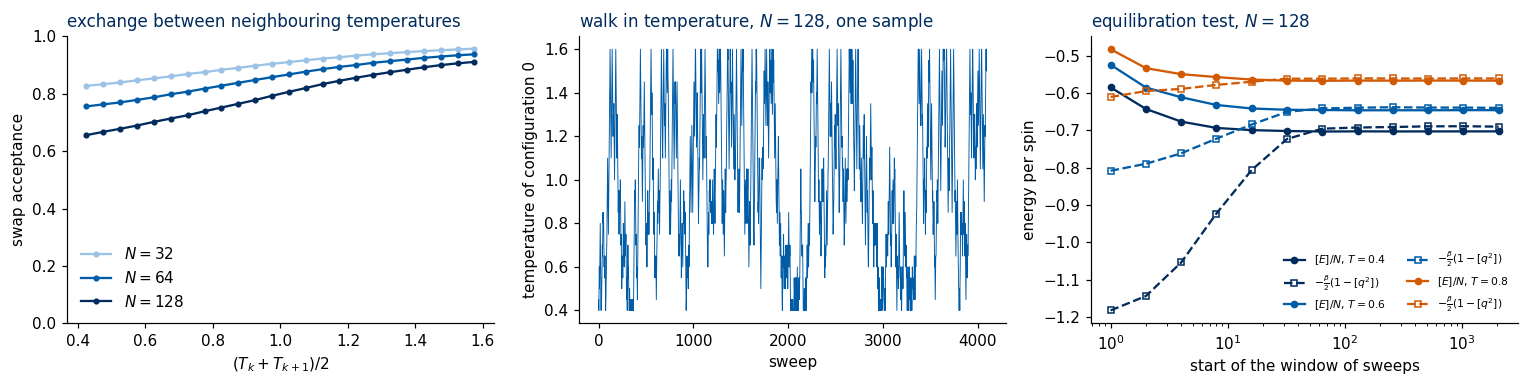

equilibration test over the production run, paired over samples (the difference should be zero within its error):
   N     T     [E]/N      -(beta/2)(1-[<q^2>])     difference


  32   0.40   -0.6544    -0.6323              -0.0221 ± 0.0150
  32   0.60   -0.5970    -0.5899              -0.0071 ± 0.0092
  32   1.00   -0.4508    -0.4484              -0.0024 ± 0.0041
  32   1.60   -0.2992    -0.2973              -0.0019 ± 0.0018
  64   0.40   -0.6850    -0.6711              -0.0139 ± 0.0166
  64   0.60   -0.6279    -0.6212              -0.0067 ± 0.0088
  64   1.00   -0.4705    -0.4676              -0.0028 ± 0.0029
  64   1.60   -0.3063    -0.3047              -0.0015 ± 0.0013
 128   0.40   -0.7026    -0.6899              -0.0127 ± 0.0180
 128   0.60   -0.6460    -0.6407              -0.0053 ± 0.0098
 128   1.00   -0.4809    -0.4787              -0.0022 ± 0.0028
 128   1.60   -0.3085    -0.3086              +0.0001 ± 0.0010

lowest swap acceptance: N = 32: 0.83, N = 64: 0.76, N = 128: 0.66


In [30]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for N in SIZES:
    Tmid = 0.5 * (T_GRID[1:] + T_GRID[:-1])
    ax[0].plot(Tmid, sk[N]["swap_acceptance"], "o-", ms=3, color=SIZE_COLORS[N], label=f"$N={N}$")
ax[0].set_xlabel("$(T_k+T_{k+1})/2$"); ax[0].set_ylabel("swap acceptance"); ax[0].set_ylim(0, 1); ax[0].legend(frameon=False)
ax[0].set_title("exchange between neighbouring temperatures")

lab = sk[128]["label_trace"]                                                  # (n_sweeps, K): label in each slot
slot_of_label0 = np.argmax(lab == 0, axis=1)                                  # temperature slot of configuration 0
ax[1].plot(T_GRID[slot_of_label0], color=UJBlue, lw=0.6)
ax[1].set_xlabel("sweep"); ax[1].set_ylabel("temperature of configuration 0"); ax[1].set_title("walk in temperature, $N=128$, one sample")

d = sk[128]; n_sw = d["e_trace"].shape[0]
edges = 2 ** np.arange(0, int(np.log2(n_sw)) + 1)
for k, col in ((0, UJNavy), (4, UJBlue), (8, DSOrange)):
    T = T_GRID[k]
    lhs = [d["e_trace"][a:b, k].mean() for a, b in zip(edges[:-1], edges[1:])]
    rhs = [-(1 / T) / 2 * (1 - d["q2_trace"][a:b, k].mean()) for a, b in zip(edges[:-1], edges[1:])]
    ax[2].semilogx(edges[:-1], lhs, "o-", ms=4, color=col, label=f"$[E]/N$, $T={T}$")
    ax[2].semilogx(edges[:-1], rhs, "s--", ms=4, color=col, mfc="none", label=r"$-\frac{\beta}{2}(1-[q^2])$")
ax[2].set_xlabel("start of the window of sweeps"); ax[2].set_ylabel("energy per spin"); ax[2].set_title("equilibration test, $N=128$")
ax[2].legend(frameon=False, fontsize=7, ncol=2)
fig.tight_layout(); savefig(fig, "gen_sk_pt_diagnostics.png"); plt.show()

def snapshot_energies(d):
    """Energy per spin of every stored snapshot: array (D, 2, K, n_save)."""
    c = d["configs"].astype(np.float32)
    return -0.5 * np.einsum("drksi,dij,drksj->drks", c, d["J"], c, optimize=True) / int(d["N"])

# the identity holds for the disorder average, so we compare the two sides sample by sample (paired difference):
# left side from the stored snapshots, right side from the measured overlaps of the same sample
print("equilibration test over the production run, paired over samples (the difference should be zero within its error):")
print("   N     T     [E]/N      -(beta/2)(1-[<q^2>])     difference")
E_snap = {N: snapshot_energies(sk[N]) for N in SIZES}
for N in SIZES:
    q2_d = ((sk[N]["q_int"].astype(np.float64) / N) ** 2).mean(-1)                # (D, K) per-sample <q^2>
    for k in (0, 4, 12, 24):
        T = T_GRID[k]
        lhs = E_snap[N][:, :, k].mean((1, 2)); rhs = -(1 / T) / 2 * (1 - q2_d[:, k]); dif = lhs - rhs
        print(f"{N:4d}  {T:5.2f}   {lhs.mean():+.4f}    {rhs.mean():+.4f}              {dif.mean():+.4f} ± {dif.std() / np.sqrt(len(dif)):.4f}")
print(f"\nlowest swap acceptance: " + ", ".join(f"N = {N}: {sk[N]['swap_acceptance'].min():.2f}" for N in SIZES))

All three checks pass. The lowest exchange acceptance is $0.83$, $0.76$ and $0.66$ for $N=32$, $64$ and $128$, and the two sides of the equilibration identity agree within about 1.5 standard errors for all sizes at every printed temperature.

### 5.6 The overlap distribution
We can now measure the central object of the theory. From the measured overlaps we build $P_J(q)$ for every sample (a histogram over the $N+1$ possible values $q=-1,-1+2/N,\dots,1$) and average over samples.
We plot the density $P(q)$, i.e. the probability of each value divided by the spacing $2/N$, so that curves for different $N$ can be compared.
The global flip symmetry makes every $P_J(q)$ exactly symmetric, $P_J(q)=P_J(-q)$; a finite run visits the mirror valleys only a limited number of times, so we
symmetrise the histogram of each sample, which uses this exact symmetry to reduce the noise.

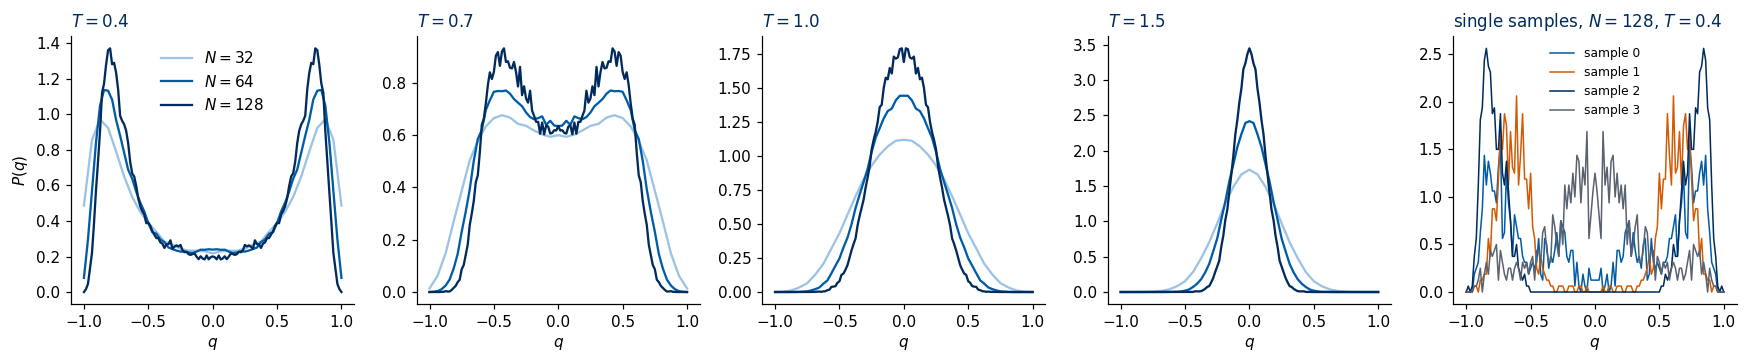

  T       [<|q|>] N=32    [<|q|>] N=64    [<|q|>] N=128   P(|q|<0.1) N=32    P(|q|<0.1) N=64    P(|q|<0.1) N=128 
 0.40             0.650           0.632           0.627             0.042             0.053             0.040
 0.60             0.478           0.449           0.434             0.081             0.101             0.085
 0.80             0.347           0.301           0.274             0.143             0.192             0.189
 1.00             0.263           0.208           0.168             0.209             0.308             0.351
 1.20             0.216           0.161           0.119             0.262             0.405             0.499
 1.50             0.181           0.131           0.094             0.316             0.493             0.608


In [31]:
def overlap_hist(d):
    """P_J(q) for every sample and temperature: array (D, K, N+1) of probabilities of q = -1, -1+2/N, ..., 1,
    symmetrised, P_J(q) -> [P_J(q) + P_J(-q)]/2 (an exact symmetry; it halves the statistical noise of a finite run)."""
    N = int(d["N"])
    idx = (d["q_int"].astype(np.int64) + N) // 2                               # 0 .. N
    D, K, n = idx.shape
    P = np.zeros((D, K, N + 1))
    np.add.at(P, (np.arange(D)[:, None, None], np.arange(K)[None, :, None], idx), 1.0)
    return 0.5 * (P + P[..., ::-1]) / n

P_J = {N: overlap_hist(sk[N]) for N in SIZES}
T_show = [0.4, 0.7, 1.0, 1.5]
fig, ax = plt.subplots(1, len(T_show) + 1, figsize=(16, 3.4))
for a, T in zip(ax, T_show):
    k = np.argmin(abs(T_GRID - T))
    for N in SIZES:
        qv = np.linspace(-1, 1, N + 1)
        a.plot(qv, P_J[N][:, k].mean(0) * N / 2, "-", lw=1.5, color=SIZE_COLORS[N], label=f"$N={N}$")
    a.set_title(f"$T={T}$"); a.set_xlabel("$q$")
ax[0].set_ylabel("$P(q)$"); ax[0].legend(frameon=False)
k = 0
qv = np.linspace(-1, 1, 129)
for d_i, col in zip(range(4), [UJBlue, DSOrange, UJNavy, UJGray]):
    ax[-1].plot(qv, P_J[128][d_i, k] * 64, lw=1, color=col, label=f"sample {d_i}")
ax[-1].set_title(f"single samples, $N=128$, $T={T_GRID[0]}$"); ax[-1].set_xlabel("$q$"); ax[-1].legend(frameon=False, fontsize=8)
fig.tight_layout(); savefig(fig, "gen_sk_Pq.png"); plt.show()

print("  T     " + "".join(f"  [<|q|>] N={N:<4d}" for N in SIZES) + "".join(f"  P(|q|<0.1) N={N:<4d}" for N in SIZES))
for T in (0.4, 0.6, 0.8, 1.0, 1.2, 1.5):
    k = np.argmin(abs(T_GRID - T))
    absq = [(P_J[N][:, k] * np.abs(np.linspace(-1, 1, N + 1))).sum(1).mean() for N in SIZES]
    small = [P_J[N][:, k][:, np.abs(np.linspace(-1, 1, N + 1)) < 0.1].sum(1).mean() for N in SIZES]
    print(f"{T:5.2f}  " + "".join(f"  {v:14.3f}" for v in absq) + "".join(f"  {v:16.3f}" for v in small))

At $T=1.5$ the distribution is a single Gaussian peak at $q=0$ that **narrows** as $N$ grows: $[\langle|q|\rangle]$ falls from $0.181$ to $0.131$ to $0.094$ for $N=32,64,128$, roughly as $1/\sqrt N$. This is the paramagnet.
At $T=1.0$ the distribution is a broad single bump that still narrows with $N$, but more slowly than at $T=1.5$: the critical point.
At $T=0.7$ and $0.4$ the picture changes. The distribution has two peaks at $\pm q_{\max}$ that sharpen with $N$, and **non-zero weight between them, including at $q=0$**.
The weight near $q=0$ at $T=0.4$ does not decrease from $N=32$ to $N=128$ ($P(|q|<0.1)=0.042$, $0.053$, $0.040$). A ferromagnet would show two sharp peaks only
(compare the Mattis model in Section 7).
The right panel shows single samples at $T=0.4$. They look very different from each other and from the average: their peaks sit at different values of $|q|$, and some have most of their
weight at intermediate overlaps. This is the sample-to-sample fluctuation of $P_J(q)$ described by Parisi's solution.

### 5.7 Susceptibility and Binder cumulant
The overlap distribution also gives the two standard quantities for locating the transition. The spin-glass susceptibility $\chi_{\rm SG}=N[\langle q^2\rangle]$ should approach $1/(1-\beta^2J^2)$ above $T_c$ (Section 4.4); below $T_c$, where
$[\langle q^2\rangle]$ stays finite, it grows proportionally to $N$.

A sharper tool is the Binder cumulant, the dimensionless ratio
$$
g(T,N)=\frac12\left(3-\frac{[\langle q^4\rangle]}{[\langle q^2\rangle]^2}\right),
$$
which is $0$ for a Gaussian $P(q)$ (because $\langle q^4\rangle=3\langle q^2\rangle^2$) and $1$ for two delta peaks at $\pm q_0$. Near a continuous transition, finite-size scaling
says that $g$ depends on $T$ and $N$ only through one combination. For the SK model this combination is $(T-T_c)N^{1/3}$ (mean-field exponents with the upper
critical dimension $d=6$ and $\nu=1/2$, so $N^{1/(\nu d)}=N^{1/3}$) [Billoire 2007]. Consequently $g(T_c,N)$ does not depend on $N$: **the curves for different $N$ cross at $T_c$**.

We compute both quantities from the per-sample moments $\langle q^2\rangle$, $\langle q^4\rangle$, and estimate errors with a bootstrap over the disorder samples
(200 resamplings of the $D$ samples with replacement).

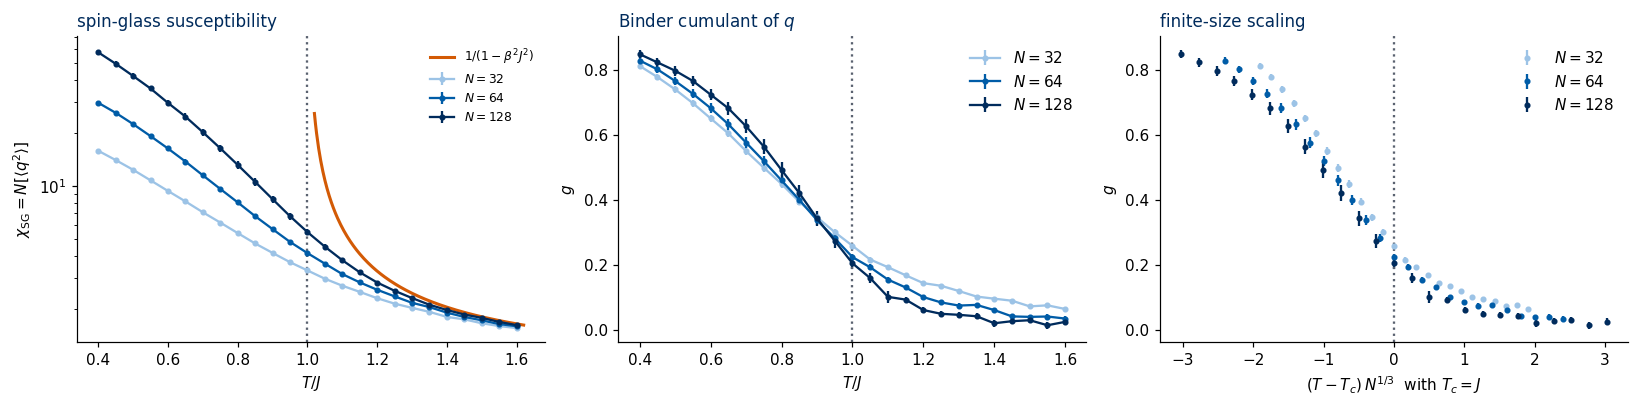

Binder crossings (bootstrap median and 68% interval over disorder resamplings):
  N =  32 and  64:  T_cross = 0.870;  bootstrap median 0.867, 68% interval [0.765, 0.933], no crossing in 6 of 200 resamplings;   exact T_c = 1.0 J
  N =  64 and 128:  T_cross = 0.920;  bootstrap median 0.914, 68% interval [0.816, 0.999], no crossing in 4 of 200 resamplings;   exact T_c = 1.0 J
  N =  32 and 128:  T_cross = 0.894;  bootstrap median 0.885, 68% interval [0.848, 0.938], no crossing in 0 of 200 resamplings;   exact T_c = 1.0 J
  T = 1.2: chi_SG = 2.296 (N=32), 2.564 (N=64), 2.819 (N=128);  1/(1-beta^2) = 3.273
  T = 1.4: chi_SG = 1.797 (N=32), 1.900 (N=64), 1.967 (N=128);  1/(1-beta^2) = 2.042
  T = 1.6: chi_SG = 1.553 (N=32), 1.591 (N=64), 1.614 (N=128);  1/(1-beta^2) = 1.641


In [32]:
def overlap_moments(d):
    """Per-sample thermal moments <q^2>, <q^4>: arrays (D, K)."""
    q = d["q_int"].astype(np.float64) / int(d["N"])
    return (q**2).mean(-1), (q**4).mean(-1)

def binder(q2, q4):
    return 0.5 * (3 - q4.mean(0) / q2.mean(0) ** 2)

def crossing(T, g1, g2, window=(0.6, 1.4)):
    """Temperature in the window where g1 - g2 changes sign (linear interpolation); NaN if it does not."""
    sel = (T >= window[0]) & (T <= window[1])
    T, dlt = T[sel], (g1 - g2)[sel]
    i = np.where(np.sign(dlt[:-1]) != np.sign(dlt[1:]))[0]
    if len(i) == 0:
        return np.nan
    i = i[0]
    return T[i] - dlt[i] * (T[i + 1] - T[i]) / (dlt[i + 1] - dlt[i])

mom = {N: overlap_moments(sk[N]) for N in SIZES}
n_boot = 200
boot_rng = np.random.default_rng(7)
def bootstrap_binder(q2, q4, n_boot, rng):
    """Binder cumulant of n_boot resamplings of the D samples; q2 and q4 of a sample stay together."""
    out = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(q2), len(q2))           # one index array per bootstrap resampling, used for both moments
        out.append(binder(q2[idx], q4[idx]))
    return np.array(out)

g_boot = {N: bootstrap_binder(*mom[N], n_boot, boot_rng) for N in SIZES}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
TT = np.linspace(1.02, 1.62, 200)
ax[0].plot(TT, 1 / (1 - 1 / TT**2), color=DSOrange, lw=2, label=r"$1/(1-\beta^2J^2)$")
for N in SIZES:
    chi = N * mom[N][0].mean(0); err = N * mom[N][0].std(0) / np.sqrt(len(mom[N][0]))
    ax[0].errorbar(T_GRID, chi, yerr=err, fmt="o-", ms=3, color=SIZE_COLORS[N], label=f"$N={N}$")
    g = binder(*mom[N]); g_err = g_boot[N].std(0)
    ax[1].errorbar(T_GRID, g, yerr=g_err, fmt="o-", ms=3, color=SIZE_COLORS[N], label=f"$N={N}$")
    ax[2].errorbar((T_GRID - T_C) * N ** (1 / 3), g, yerr=g_err, fmt="o", ms=3, color=SIZE_COLORS[N], label=f"$N={N}$")
ax[0].set_yscale("log"); ax[0].axvline(T_C, color=UJGray, ls=":"); ax[0].set_xlabel("$T/J$"); ax[0].set_ylabel(r"$\chi_{\rm SG}=N[\langle q^2\rangle]$")
ax[0].set_title("spin-glass susceptibility"); ax[0].legend(frameon=False, fontsize=8)
ax[1].axvline(T_C, color=UJGray, ls=":"); ax[1].set_xlabel("$T/J$"); ax[1].set_ylabel("$g$"); ax[1].set_title("Binder cumulant of $q$"); ax[1].legend(frameon=False)
ax[2].axvline(0, color=UJGray, ls=":"); ax[2].set_xlabel(r"$(T-T_c)\,N^{1/3}$  with $T_c=J$"); ax[2].set_ylabel("$g$")
ax[2].set_title("finite-size scaling"); ax[2].legend(frameon=False)
fig.tight_layout(); savefig(fig, "gen_sk_binder.png"); plt.show()

print("Binder crossings (bootstrap median and 68% interval over disorder resamplings):")
for N1, N2 in ((32, 64), (64, 128), (32, 128)):
    c0 = crossing(T_GRID, binder(*mom[N1]), binder(*mom[N2]))
    cb = np.array([crossing(T_GRID, g_boot[N1][i], g_boot[N2][i]) for i in range(n_boot)])
    lo, med, hi = np.nanpercentile(cb, [16, 50, 84])
    print(f"  N = {N1:3d} and {N2:3d}:  T_cross = {c0:.3f};  bootstrap median {med:.3f}, 68% interval [{lo:.3f}, {hi:.3f}],"
          f" no crossing in {np.isnan(cb).sum()} of {n_boot} resamplings;   exact T_c = {T_C} J")
for T in (1.2, 1.4, 1.6):
    k = np.argmin(abs(T_GRID - T))
    print(f"  T = {T}: chi_SG = " + ", ".join(f"{N * mom[N][0][:, k].mean():.3f} (N={N})" for N in SIZES) + f";  1/(1-beta^2) = {1 / (1 - 1 / T**2):.3f}")

Above $T_c$ the spin-glass susceptibility approaches $1/(1-\beta^2J^2)$ from below as $N$ grows, most closely at $T=1.6$ ($1.553$, $1.591$, $1.614$ against $1.641$); near $T_c$ the finite systems cannot follow
the divergence. Below $T_c$, $\chi_{\rm SG}$ grows roughly proportionally to $N$: $[\langle q^2\rangle]$ stays finite, the frozen phase.

The Binder cumulants are ordered $g_{32}>g_{64}>g_{128}$ above $T_c$ and come together below it. The pairwise crossings printed above lie at $0.870$ for
$N=32$ and $64$, $0.920$ for $64$ and $128$, and $0.894$ for $32$ and $128$, with 68% bootstrap intervals $[0.765,0.933]$, $[0.816,0.999]$ and $[0.848,0.938]$.
Two of the three intervals lie entirely below $T=J$ and the third reaches it only at its upper end, so at these sizes the crossings lie significantly
below $T_c$. They move up as the sizes grow, from $0.870$ for the smaller pair to $0.920$ for the larger one, which is how finite-size corrections to the
crossing point behave; with $N\le128$ this drift cannot be extrapolated reliably. The curves meet at a small angle, so a few resamplings (6 and 4 of 200
for the pairs $32/64$ and $64/128$) have no crossing in the window at all.
Plotted against $(T-T_c)N^{1/3}$ with the exact $T_c=J$, the three sizes fall on one curve within the error bars: the size dependence of the data is consistent with
the mean-field finite-size scaling of the SK model and with $T_c=J$, up to finite-size corrections that shift the crossings of the smallest sizes downwards.

<hr/>
## 6. The energy landscape

### 6.1 Ground-state energy
Finding the ground state of one SK sample is a hard optimisation problem (Section 1.2). For $N\le24$ exact enumeration gives it (Section 2.4). For $N=32,64,128$
we use the parallel-tempering runs: the lowest energy visited by each replica during the run (`E_min`), improved by a **zero-temperature descent**, which flips, one at a
time, every spin anti-aligned with its local field ($s_ih_i<0$, so $\Delta E_i<0$) until no such spin is left. The descent is also applied to all snapshots stored at the
lowest temperature. The result is an **upper bound** on the true ground-state energy of each sample. A useful indicator of its quality is that the two replicas
search independently, so if both find the same lowest energy, it is very likely the ground state.

For the extrapolation to $N\to\infty$ we use the form $[E_0]/N=e_\infty+a\,N^{-2/3}$; the exponent $2/3$ of the finite-size correction is supported by extensive
ground-state computations for the SK model [Boettcher 2005].

In [33]:
@partial(jax.jit, static_argnames=("block",))
def descent_columns(s, J, block):
    """Zero-temperature descent of C chains of one sample, s: (N, C), J: (N, N). The sweep of Section 5.2 at beta -> infinity
    (beta = infinity, u = 1/2, so the threshold is 0): a spin flips if and only if s_i h_i < 0. Sweeps are repeated until no spin flips."""
    big = jnp.full(s.shape[1], jnp.inf)
    half = jnp.full(s.shape, 0.5)
    def body(c):
        s, h, _ = c
        s2, h2 = sweep_sample(s, h, J, big, half, block)
        return s2, h2, jnp.any(s2 != s)
    s, _, _ = lax.while_loop(lambda c: c[2], body, (s, J @ s, True))
    return s

descent_many = lambda s, J: descent_columns(s.T, J, gcd(s.shape[-1], 16)).T                  # s: (B, N), one sample
descent_samples = jax.jit(jax.vmap(lambda s, J: descent_columns(s.T, J, 16).T))              # s: (D, B, N), J: (D, N, N)

def energies(s, J):
    """Energies of configurations s (D, B, N) for couplings J (D, N, N): array (D, B)."""
    return -0.5 * jnp.einsum("dbi,dij,dbj->db", s, J, s)

gs = {}
for N in SIZES:
    d = sk[N]; D = int(d["D"])
    J = jnp.asarray(d["J"])
    # candidates: the lowest configuration of each replica and all snapshots at the lowest temperature, both replicas
    cand = np.concatenate([d["s_min"][:, :, None, :], d["configs"][:, :, 0]], axis=2).astype(np.float32)   # (D, 2, 1 + n_save, N)
    cand = jnp.asarray(cand.reshape(D, -1, N))
    s_loc = descent_samples(cand, J)
    E_loc = np.asarray(energies(s_loc, J)).reshape(D, 2, -1)                          # (D, 2, 1 + n_save)
    best_rep = np.minimum(E_loc.min(-1), d["E_min"])                                 # (D, 2) best of each replica
    gs[N] = dict(best=best_rep.min(1) / N, agree=np.mean(np.abs(best_rep[:, 0] - best_rep[:, 1]) < 1e-4))
    print(f"N = {N:3d}: [E0]/N <= {gs[N]['best'].mean():.4f} ± {gs[N]['best'].std() / np.sqrt(D):.4f};"
          f"  both replicas found the same lowest energy in {100 * gs[N]['agree']:.0f}% of the {D} samples")

N =  32: [E0]/N <= -0.6911 ± 0.0027;  both replicas found the same lowest energy in 100% of the 256 samples


N =  64: [E0]/N <= -0.7183 ± 0.0019;  both replicas found the same lowest energy in 100% of the 160 samples


N = 128: [E0]/N <= -0.7345 ± 0.0016;  both replicas found the same lowest energy in 97% of the 96 samples


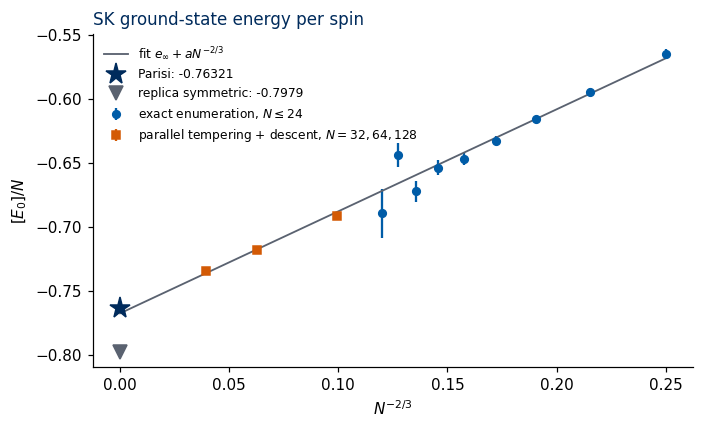

fit over N = 8..128: e_inf = -0.7674 ± 0.0016,  a = 0.796,  chi^2 = 14.3 for 10 degrees of freedom
fit over N = 16..128: e_inf = -0.7643 ± 0.0023,  a = 0.746,  chi^2 = 9.5 for 6 degrees of freedom
relative difference of the full fit from Parisi's value: -0.55%
Parisi (Crisanti & Rizzo 2002): -0.76321,   replica-symmetric value -sqrt(2/pi) = -0.7979


In [34]:
N_all = np.array(sorted(list(N_ENUM) + list(N_GS_ONLY) + SIZES))
e_mean = np.array([(enum[N]["E0"] / N).mean() if N in enum else gs[N]["best"].mean() for N in N_all])
e_err = np.array([(enum[N]["E0"] / N).std() / np.sqrt(len(enum[N]["E0"])) if N in enum
                  else gs[N]["best"].std() / np.sqrt(len(gs[N]["best"])) for N in N_all])

x_fit = N_all ** (-2 / 3)

def fit_e0(mask):
    """Weighted least squares of e(N) = e_inf + a N^(-2/3) over the sizes selected by mask: (e_inf, a), error of e_inf, chi^2."""
    A = np.stack([np.ones(mask.sum()), x_fit[mask]], 1) / e_err[mask, None]
    coef, *_ = np.linalg.lstsq(A, e_mean[mask] / e_err[mask], rcond=None)
    cov = np.linalg.inv(A.T @ A)
    chi2 = np.sum(((e_mean[mask] - (coef[0] + coef[1] * x_fit[mask])) / e_err[mask]) ** 2)
    return coef, np.sqrt(cov[0, 0]), chi2

coef, e_inf_err, chi2 = fit_e0(np.ones(len(N_all), bool))
e_inf = coef[0]
coef16, e_inf16_err, chi2_16 = fit_e0(N_all >= 16)
E0_RS = -np.sqrt(2 / np.pi)

fig, ax = plt.subplots(figsize=(6.5, 4))
is_enum = np.isin(N_all, list(N_ENUM) + list(N_GS_ONLY))
ax.errorbar(x_fit[is_enum], e_mean[is_enum], yerr=e_err[is_enum], fmt="o", color=UJBlue, ms=5, label="exact enumeration, $N\\leq24$")
ax.errorbar(x_fit[~is_enum], e_mean[~is_enum], yerr=e_err[~is_enum], fmt="s", color=DSOrange, ms=5, label="parallel tempering + descent, $N=32,64,128$")
xx = np.linspace(0, x_fit.max(), 100)
ax.plot(xx, coef[0] + coef[1] * xx, color=UJGray, lw=1.2, label=r"fit $e_\infty+aN^{-2/3}$")
ax.plot(0, E0_PARISI, "*", ms=14, color=UJNavy, label=f"Parisi: {E0_PARISI}")
ax.plot(0, E0_RS, "v", ms=9, color=UJGray, label=f"replica symmetric: {E0_RS:.4f}")
ax.set_xlabel("$N^{-2/3}$"); ax.set_ylabel("$[E_0]/N$"); ax.set_title("SK ground-state energy per spin"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); savefig(fig, "gen_sk_ground_state.png"); plt.show()
print(f"fit over N = {N_all.min()}..{N_all.max()}: e_inf = {e_inf:.4f} ± {e_inf_err:.4f},  a = {coef[1]:.3f},  chi^2 = {chi2:.1f} for {len(N_all) - 2} degrees of freedom")
print(f"fit over N = 16..{N_all.max()}: e_inf = {coef16[0]:.4f} ± {e_inf16_err:.4f},  a = {coef16[1]:.3f},  chi^2 = {chi2_16:.1f} for {(N_all >= 16).sum() - 2} degrees of freedom")
print(f"relative difference of the full fit from Parisi's value: {100 * (e_inf - E0_PARISI) / abs(E0_PARISI):+.2f}%")
print(f"Parisi (Crisanti & Rizzo 2002): {E0_PARISI},   replica-symmetric value -sqrt(2/pi) = {E0_RS:.4f}")

The data for $N\le24$ are exact (up to the statistical error of the disorder average); for $N\ge32$ they are upper bounds, but the two independent replicas
found the same lowest energy in almost all samples (all samples for $N=32$ and $64$, 97% for $N=128$), so the bound is very likely reached. All sizes lie close to one straight line in $N^{-2/3}$, and the extrapolation
lands within about one percent of Parisi's value ($e_\infty=-0.7674$ from the fit over all sizes, $-0.7643$ without the smallest ones, against $-0.76321$; the two fits show how much the result depends on the range of sizes).
With sizes up to $N=128$ this is a modest test, but it clearly separates Parisi's value from the replica-symmetric value $-\sqrt{2/\pi}$, which lies well below
the data: the RS solution overestimates how deep the landscape goes.

### 6.2 Metastable states
A configuration is **metastable** (a local minimum for single flips) if every spin is aligned with its local field, $s_ih_i>0$ for all $i$. The ferromagnet has exactly two
such configurations (all up, all down) for any $N$. The exact enumeration of Section 2.4 counted them for the SK model.

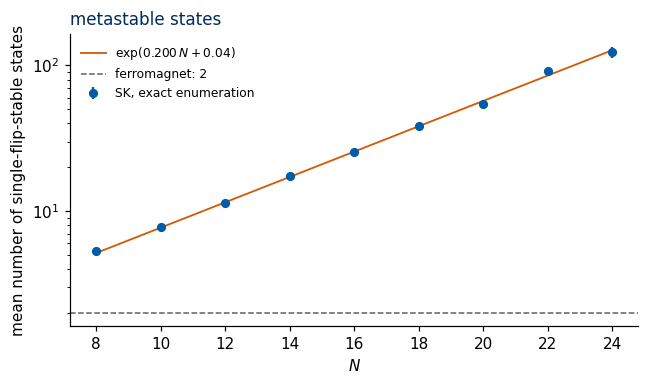

N =  8: [number of metastable states] =       5.3
N = 10: [number of metastable states] =       7.8
N = 12: [number of metastable states] =      11.4
N = 14: [number of metastable states] =      17.4
N = 16: [number of metastable states] =      25.3
N = 18: [number of metastable states] =      38.5
N = 20: [number of metastable states] =      54.3
N = 22: [number of metastable states] =      92.1
N = 24: [number of metastable states] =     122.8
growth rate from a fit over N >= 12: ln[n] = 0.2004 N +0.036  ->  at N = 128 this extrapolates to about 1.4e+11


In [35]:
Ns_ms = np.array(sorted(list(N_ENUM) + list(N_GS_ONLY)))
n_ms = np.array([enum[N]["n_stable"].mean() for N in Ns_ms])
n_ms_err = np.array([enum[N]["n_stable"].std() / np.sqrt(len(enum[N]["n_stable"])) for N in Ns_ms])
sel = Ns_ms >= 12
alpha_fit, c_fit = np.polyfit(Ns_ms[sel], np.log(n_ms[sel]), 1)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.errorbar(Ns_ms, n_ms, yerr=n_ms_err, fmt="o", color=UJBlue, ms=5, label="SK, exact enumeration")
ax.plot(Ns_ms, np.exp(c_fit + alpha_fit * Ns_ms), color=DSOrange, lw=1.2, label=fr"$\exp({alpha_fit:.3f}\,N{c_fit:+.2f})$")
ax.axhline(2, color=UJGray, ls="--", lw=1, label="ferromagnet: 2")
ax.set_yscale("log"); ax.set_xlabel("$N$"); ax.set_ylabel("mean number of single-flip-stable states")
ax.set_title("metastable states"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()
for N, m in zip(Ns_ms, n_ms):
    print(f"N = {N:2d}: [number of metastable states] = {m:9.1f}")
print(f"growth rate from a fit over N >= 12: ln[n] = {alpha_fit:.4f} N {c_fit:+.3f}  ->  at N = 128 this extrapolates to about {np.exp(c_fit + alpha_fit * 128):.1e}")

The number of metastable states grows **exponentially** with $N$, roughly as $e^{0.20N}$ according to the fit. A local search started from a random configuration therefore ends in one of exponentially many
traps, most of them well above the ground state. We see this directly at $N=128$: zero-temperature descents from $2000$ random starts, for one sample of the data set.

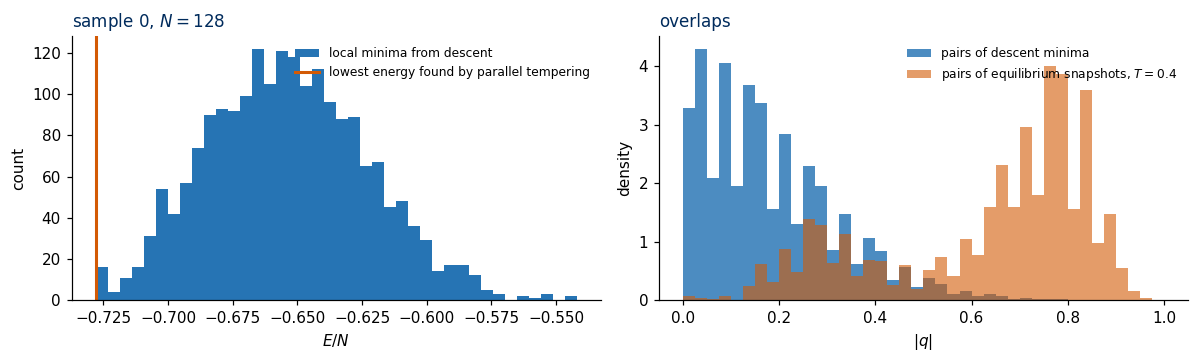

2000 descents: 1974 distinct local minima;  E/N: mean -0.6537, lowest -0.7280;  lowest energy found by parallel tempering for this sample -0.7280
mean |q| between descent minima 0.182;  between equilibrium snapshots at T = 0.4: 0.631


In [36]:
d128 = sk[128]; J0 = jnp.asarray(d128["J"][0])
n_starts = 2000
s_start = random_spins(jax.random.PRNGKey(31), (n_starts, 128))
s_desc = descent_many(s_start, J0)
e_desc = np.asarray(-0.5 * jnp.einsum("bi,ij,bj->b", s_desc, J0, s_desc)) / 128
canon = np.asarray(s_desc * s_desc[:, :1]).astype(np.int8)                      # identify s and -s (fix the first spin to +1)
n_distinct = len({c.tobytes() for c in canon})
q_desc = np.asarray(s_desc @ s_desc.T / 128)[np.triu_indices(n_starts, 1)]

k04 = 0
conf04 = d128["configs"][0, :, k04].reshape(-1, 128).astype(np.float32)        # equilibrium snapshots at T = 0.4, both replicas
q_eq = (conf04 @ conf04.T / 128)[np.triu_indices(len(conf04), 1)]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(e_desc, bins=40, color=UJBlue, alpha=0.85, label="local minima from descent")
ax[0].axvline(gs[128]["best"][0], color=DSOrange, lw=2, label="lowest energy found by parallel tempering")
ax[0].set_xlabel("$E/N$"); ax[0].set_ylabel("count"); ax[0].set_title("sample 0, $N=128$"); ax[0].legend(frameon=False, fontsize=8)
bins = np.linspace(0, 1, 41)
ax[1].hist(np.abs(q_desc), bins=bins, density=True, color=UJBlue, alpha=0.7, label="pairs of descent minima")
ax[1].hist(np.abs(q_eq), bins=bins, density=True, color=DSOrange, alpha=0.6, label="pairs of equilibrium snapshots, $T=0.4$")
ax[1].set_xlabel("$|q|$"); ax[1].set_ylabel("density"); ax[1].legend(frameon=False, fontsize=8); ax[1].set_title("overlaps")
fig.tight_layout(); plt.show()
print(f"{n_starts} descents: {n_distinct} distinct local minima;  E/N: mean {e_desc.mean():.4f}, lowest {e_desc.min():.4f};"
      f"  lowest energy found by parallel tempering for this sample {gs[128]['best'][0]:.4f}")
print(f"mean |q| between descent minima {np.abs(q_desc).mean():.3f};  between equilibrium snapshots at T = 0.4: {np.abs(q_eq).mean():.3f}")

Almost every descent ends in a different local minimum ($1974$ distinct minima from $2000$ starts). The typical minimum, with mean energy $-0.654$ per spin, lies well above the lowest energy found by parallel tempering, $-0.728$; only the best of
the $2000$ descents reaches it. The minima reached by descent are
also less similar to each other than equilibrium configurations at $T=0.4$ (mean $|q|$ of $0.18$ against $0.63$): the descent stops in shallow traps scattered over the landscape, while thermal
equilibrium at low temperature concentrates on a few deep valleys.

### 6.3 Slow dynamics
A plain Metropolis simulation without exchange moves, started from random configurations, shows how the system relaxes in this landscape. We run it at
$T=0.4$ and at $T=1.5$ for $64$ samples of the data set (two replicas each), for $N=32$ and $N=128$, and follow the disorder averages $[E]/N$ and $[q^2]$
after every sweep. The equilibrium values for the same $64$ samples come from the parallel-tempering snapshots and overlaps of Section 5.

N =  32: Metropolis without exchange, 4096 sweeps at T = [0.4 1.5]: 3.4 s


N = 128: Metropolis without exchange, 4096 sweeps at T = [0.4 1.5]: 4.0 s


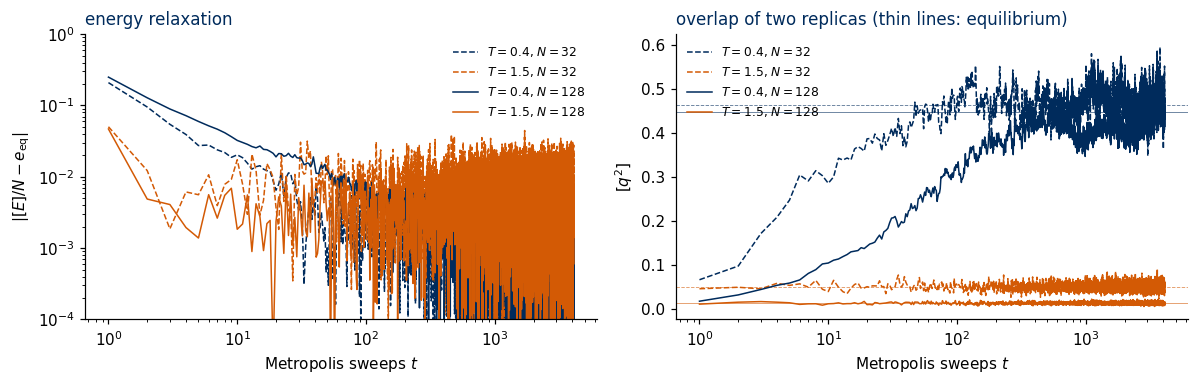

   N     T      t   [E]/N - e_eq    [q^2]   (equilibrium [q^2])
  32   0.4      8    +0.0219      0.315    (0.465)
  32   0.4     64    +0.0012      0.442    (0.465)
  32   0.4    512    -0.0029      0.456    (0.465)
  32   0.4   4096    +0.0025      0.446    (0.465)
  32   1.5      8    +0.0078      0.066    (0.051)
  32   1.5     64    +0.0182      0.047    (0.051)
  32   1.5    512    -0.0094      0.051    (0.051)
  32   1.5   4096    +0.0165      0.041    (0.051)
 128   0.4      8    +0.0415      0.090    (0.449)
 128   0.4     64    +0.0102      0.267    (0.449)
 128   0.4    512    +0.0000      0.429    (0.449)
 128   0.4   4096    -0.0007      0.462    (0.449)
 128   1.5      8    -0.0055      0.013    (0.014)
 128   1.5     64    +0.0082      0.012    (0.014)
 128   1.5    512    +0.0029      0.015    (0.014)
 128   1.5   4096    +0.0033      0.017    (0.014)


In [37]:
D_slow, n_slow = 64, 4096
T_slow = np.array([0.4, 1.5])
k_slow = [int(np.argmin(abs(T_GRID - T))) for T in T_slow]
slow, eq_ref = {}, {}
for N in (32, 128):
    k_init, k_run = jax.random.split(jax.random.PRNGKey(41 + N))
    t0 = time.time()
    slow[N] = parallel_tempering(jnp.asarray(sk[N]["J"][:D_slow]), random_spins(k_init, (D_slow, 2, len(T_slow), N)),
                                 jnp.asarray(1 / T_slow, jnp.float32), k_run, n_equil=n_slow, n_save=1, n_meas=1, meas_every=1, use_swaps=False)
    q2_d = ((sk[N]["q_int"][:D_slow].astype(np.float64) / N) ** 2).mean(-1)                       # (D_slow, K)
    eq_ref[N] = [(E_snap[N][:D_slow, :, k].mean(), q2_d[:, k].mean()) for k in k_slow]          # (e_eq, q2_eq) per temperature
    print(f"N = {N:3d}: Metropolis without exchange, {n_slow} sweeps at T = {T_slow}: {time.time() - t0:.1f} s")

t_axis = np.arange(1, n_slow + 2)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for N, ls in ((32, "--"), (128, "-")):
    for j, (T, col) in enumerate(zip(T_slow, (UJNavy, DSOrange))):
        e_t = np.asarray(slow[N]["e_trace"])[:, j]; q2_t = np.asarray(slow[N]["q2_trace"])[:, j]
        ax[0].loglog(t_axis, np.abs(e_t - eq_ref[N][j][0]), ls, color=col, lw=1, label=f"$T={T}$, $N={N}$")
        ax[1].semilogx(t_axis, q2_t, ls, color=col, lw=1, label=f"$T={T}$, $N={N}$")
        ax[1].axhline(eq_ref[N][j][1], color=col, ls=ls, lw=0.6, alpha=0.6)
ax[0].set_ylim(1e-4, 1); ax[0].set_xlabel("Metropolis sweeps $t$"); ax[0].set_ylabel(r"$|[E]/N-e_{\rm eq}|$")
ax[0].set_title("energy relaxation"); ax[0].legend(frameon=False, fontsize=8)
ax[1].set_xlabel("Metropolis sweeps $t$"); ax[1].set_ylabel("$[q^2]$"); ax[1].set_title("overlap of two replicas (thin lines: equilibrium)")
ax[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); savefig(fig, "gen_sk_slow_dynamics.png"); plt.show()

print("   N     T      t   [E]/N - e_eq    [q^2]   (equilibrium [q^2])")
for N in (32, 128):
    for j, T in enumerate(T_slow):
        for t in (8, 64, 512, 4096):
            e_t = np.asarray(slow[N]["e_trace"])[t - 1, j]; q2_t = np.asarray(slow[N]["q2_trace"])[t - 1, j]
            print(f"{N:4d}  {T:4.1f}  {t:5d}    {e_t - eq_ref[N][j][0]:+.4f}      {q2_t:.3f}    ({eq_ref[N][j][1]:.3f})")

At $T=1.5$ both quantities reach their equilibrium values within a few sweeps, for both sizes; afterwards the curves only show thermal noise. At $T=0.4$ the energy
approaches its equilibrium value slowly, roughly as a power of time on the log–log plot (until the gap reaches the noise level after about a hundred sweeps), and the
overlap of the two replicas builds up over tens of sweeps for $N=32$ but several hundred sweeps for $N=128$ (table above). Each replica first falls into some valley,
and the two replicas agree only after they have found the same deep valleys. At these small sizes plain Metropolis still reaches equilibrium within a few thousand
sweeps; the relaxation time grows with $N$ and as $T$ decreases. Slow relaxation of this kind is what
the experiments on spin-glass alloys observe (Section 1.1); parallel tempering shortens it by letting configurations escape through high temperatures.

<hr/>
## 7. The Mattis model

### 7.1 Mapping to the Curie–Weiss model
Section 3.3 showed that random signs alone do not produce frustration. Mattis proposed couplings that look as random as the SK couplings but are not frustrated [Mattis 1976]:
$$
J_{ij}=\frac{J}{N}\,\xi_i\xi_j,\qquad \xi_i=\pm1\ \text{random and fixed}.
$$
Half of the couplings are negative. But the gauge transformation of Section 2.3 with $\tau_i=\xi_i$, i.e. $\sigma_i=\xi_is_i$, gives
$$
\begin{aligned}
H&=-\frac JN\sum_{i<j}\xi_i\xi_js_is_j=-\frac JN\sum_{i<j}\sigma_i\sigma_j\\
&=-\frac{J}{2N}\Big[\Big(\sum_i\sigma_i\Big)^2-N\Big],
\end{aligned}
$$
the Curie–Weiss ferromagnet in the variables $\sigma_i$. All of its thermodynamics follows: a transition at $T_c=J$, below which the **Mattis magnetisation**
$m_\xi=\frac1N\sum_i\xi_is_i$ solves $m_\xi=\tanh(\beta Jm_\xi)$. The ordinary magnetisation $m=\frac1N\sum_is_i$ stays of order $1/\sqrt N$: a snapshot looks just as
random as an SK snapshot. The order is in the hidden pattern $\boldsymbol\xi$. (This is the Hopfield network with one stored pattern.)

We check four consequences: no frustrated loops (Section 3.3), only two metastable states, a $P(q)$ with two sharp peaks at $\pm m_\xi^2$ (two replicas both aligned
with $\pm\boldsymbol\xi$) and **no weight in between**, and a Binder cumulant that goes to $1$ below $T_c$.

In [38]:
# SymPy: the gauge transformation sigma_i = xi_i s_i turns the Mattis Hamiltonian into the Curie-Weiss one (N = 4)
Nm = 4
xi_s = sp.symbols(f"xi1:{Nm + 1}"); sg_s = sp.symbols(f"sigma1:{Nm + 1}")
H_mattis = -sum(xi_s[i] * xi_s[j] * (xi_s[i] * sg_s[i]) * (xi_s[j] * sg_s[j]) for i in range(Nm) for j in range(i + 1, Nm)) / Nm   # s_i = xi_i sigma_i
H_mattis = sp.expand(H_mattis).subs({x_**2: 1 for x_ in xi_s})
H_cw = -((sum(sg_s))**2 - Nm) / (2 * Nm)
print("Mattis Hamiltonian with s_i = xi_i sigma_i:", H_mattis)
print("difference to -(1/2N)[(sum sigma)^2 - N] with sigma_i^2 = 1:",
      sp.expand(sp.expand(H_cw).subs({g_**2: 1 for g_ in sg_s}) - H_mattis))

# exact enumeration for N = 16: number of single-flip-stable configurations (Mattis vs SK)
xi16 = rng.choice([-1.0, 1.0], size=16)
out_m = enumerate_sample(jnp.asarray(mattis_couplings(xi16), jnp.float32), jnp.asarray([1.0]), jnp.asarray([1.0]))
print(f"\nN = 16: metastable states, Mattis: {int(out_m[3])}  (SK average at N = 16: {enum[16]['n_stable'].mean():.1f});"
      f"  Mattis E0/N = {float(out_m[2]) / 16:.4f}, formula -(N-1)/(2N) = {-(15) / 32:.4f}")

Mattis Hamiltonian with s_i = xi_i sigma_i: -sigma1*sigma2/4 - sigma1*sigma3/4 - sigma1*sigma4/4 - sigma2*sigma3/4 - sigma2*sigma4/4 - sigma3*sigma4/4
difference to -(1/2N)[(sum sigma)^2 - N] with sigma_i^2 = 1: 0



N = 16: metastable states, Mattis: 2  (SK average at N = 16: 25.3);  Mattis E0/N = -0.4688, formula -(N-1)/(2N) = -0.4688


SymPy confirms the mapping, and enumeration of one $N=16$ sample finds exactly two metastable states (against $25.3$ on average for the SK model at the same size) and the Curie–Weiss ground-state energy.

### 7.2 Monte Carlo simulation
For the overlap distribution and the Binder cumulant we run the same parallel-tempering code for $D=32$ Mattis samples of $N=64$ spins on the same temperature grid and compare with the SK data at the same size.

Mattis model, N = 64, 32 samples: 43.3 s


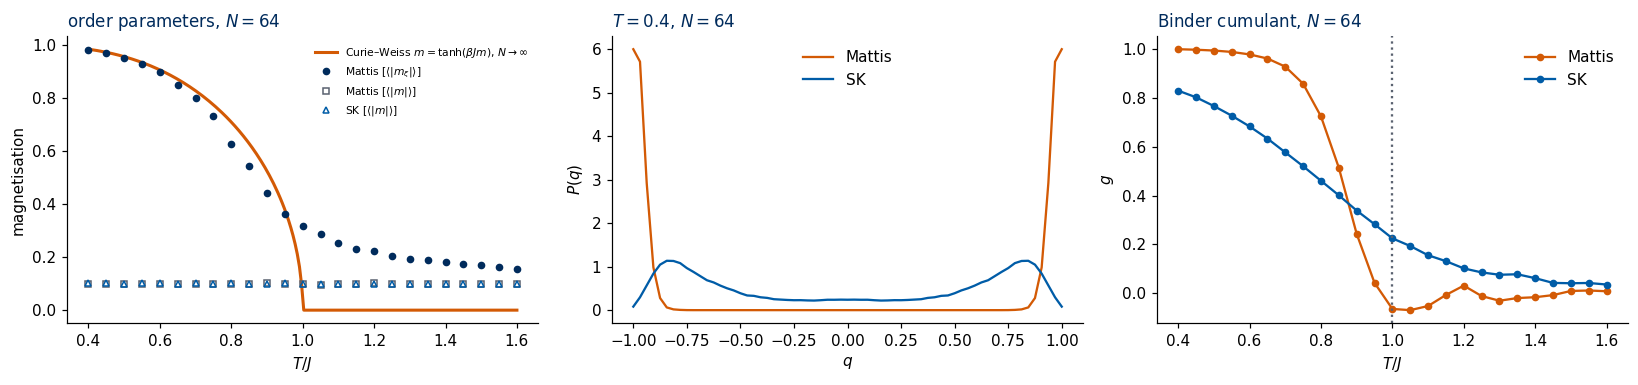

T = 0.4: weight of P(q) at |q| < 0.5:  Mattis 0.0000,  SK 0.2467
T = 0.4: Binder g:  Mattis 0.998,  SK 0.829
T = 0.4: [<|m_xi|>] Mattis 0.984 (Curie-Weiss 0.986);  [<|m|>]: Mattis 0.098, SK 0.102


In [39]:
N_m, D_m = 64, 32
xi_m = rng.choice([-1.0, 1.0], size=(D_m, N_m))
J_m = np.stack([mattis_couplings(x_) for x_ in xi_m]).astype(np.float32)
t0 = time.time()
mat = generate_sk_dataset(N_m, D_m, n_equil=2048, n_save=16, n_meas=32, meas_every=2, seed_couplings=-1, seed_run=3064, couplings=J_m)
print(f"Mattis model, N = {N_m}, {D_m} samples: {time.time() - t0:.1f} s")

conf = mat["configs"].astype(np.float32)                                        # (D, 2, K, n_save, N)
m_xi = np.abs(np.einsum("drksi,di->drks", conf, xi_m) / N_m).mean((0, 1, 3))    # [<|m_xi|>] per temperature
m_plain = np.abs(conf.mean(-1)).mean((0, 1, 3))                                  # [<|m|>] per temperature
m_sk = np.abs(sk[64]["configs"].astype(np.float32).mean(-1)).mean((0, 1, 3))

def curie_weiss(T):
    return brentq(lambda m: m - np.tanh(m / T), 1e-9, 1.0) if T < 1 else 0.0

P_m = overlap_hist(mat); mom_m = overlap_moments(mat)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
TT = np.linspace(0.4, 1.6, 200)
ax[0].plot(TT, [curie_weiss(T) for T in TT], color=DSOrange, lw=2, label=r"Curie–Weiss $m=\tanh(\beta Jm)$, $N\to\infty$")
ax[0].plot(T_GRID, m_xi, "o", color=UJNavy, ms=4, label=r"Mattis $[\langle|m_\xi|\rangle]$")
ax[0].plot(T_GRID, m_plain, "s", color=UJGray, ms=4, mfc="none", label=r"Mattis $[\langle|m|\rangle]$")
ax[0].plot(T_GRID, m_sk, "^", color=UJBlue, ms=4, mfc="none", label=r"SK $[\langle|m|\rangle]$")
ax[0].set_xlabel("$T/J$"); ax[0].set_ylabel("magnetisation"); ax[0].set_title(f"order parameters, $N={N_m}$"); ax[0].legend(frameon=False, fontsize=7)
k = 0
qv = np.linspace(-1, 1, N_m + 1)
ax[1].plot(qv, P_m[:, k].mean(0) * N_m / 2, color=DSOrange, lw=1.5, label="Mattis")
ax[1].plot(qv, P_J[64][:, k].mean(0) * N_m / 2, color=UJBlue, lw=1.5, label="SK")
ax[1].set_xlabel("$q$"); ax[1].set_ylabel("$P(q)$"); ax[1].set_title(f"$T={T_GRID[k]}$, $N={N_m}$"); ax[1].legend(frameon=False)
ax[2].plot(T_GRID, binder(*mom_m), "o-", ms=4, color=DSOrange, label="Mattis")
ax[2].plot(T_GRID, binder(*mom[64]), "o-", ms=4, color=UJBlue, label="SK")
ax[2].axvline(T_C, color=UJGray, ls=":"); ax[2].set_xlabel("$T/J$"); ax[2].set_ylabel("$g$"); ax[2].set_title(f"Binder cumulant, $N={N_m}$"); ax[2].legend(frameon=False)
fig.tight_layout(); savefig(fig, "gen_sk_mattis.png"); plt.show()

i_mid = np.abs(qv) < 0.5
print(f"T = {T_GRID[k]}: weight of P(q) at |q| < 0.5:  Mattis {P_m[:, k][:, i_mid].sum(1).mean():.4f},  SK {P_J[64][:, k][:, i_mid].sum(1).mean():.4f}")
print(f"T = {T_GRID[k]}: Binder g:  Mattis {binder(*mom_m)[k]:.3f},  SK {binder(*mom[64])[k]:.3f}")
print(f"T = {T_GRID[k]}: [<|m_xi|>] Mattis {m_xi[k]:.3f} (Curie-Weiss {curie_weiss(T_GRID[k]):.3f});  [<|m|>]: Mattis {m_plain[k]:.3f}, SK {m_sk[k]:.3f}")

In both models the ordinary magnetisation of a snapshot is small at every temperature ($[\langle|m|\rangle]\approx0.10$ at $T=0.4$ in both): neither phase is visible in $m$.
The Mattis model nevertheless orders exactly like a ferromagnet, in the hidden variable $m_\xi$, following the Curie–Weiss curve up to finite-size rounding near $T_c$ ($0.984$ against $0.986$ at $T=0.4$).
Its overlap distribution consists of two sharp peaks with essentially no weight in between, and its Binder cumulant approaches $1$ at low temperature ($0.998$ at $T=0.4$).
The SK model at the same size has a broad $P(q)$ (weight $0.25$ at $|q|<0.5$) and a Binder cumulant well below $1$ ($0.83$). Disorder without frustration is a hidden ferromagnet; disorder with
frustration is a spin glass.

The Mattis model shows how a ferromagnetic bias competes with frustration. The classical phase diagram of Sherrington and Kirkpatrick [1975] and Kirkpatrick and Sherrington [1978] makes this competition quantitative: the couplings are drawn with a non-zero mean, $J_{ij}\sim\mathcal N(J_0/N,\,J^2/N)$, and the phases are mapped in the plane of the mean coupling $J_0/J$ and the temperature $T/J$, drawn below. The model studied in this notebook is the vertical axis $J_0=0$.

At high temperature the system is a paramagnet, with $m=0$ and $q_{\rm EA}=0$. Lowering the temperature, the paramagnet becomes unstable in one of two ways. For $J_0<J$ the spin-glass susceptibility $\chi_{\rm SG}=1/(1-\beta^2J^2)$ of Section 4.4 diverges first, at $T=J$, and below this line the spins freeze with $m=0$ and $q_{\rm EA}>0$: the spin glass. For $J_0>J$ the ferromagnetic response diverges first, at $T=J_0$, the Curie–Weiss transition of Section 7.1 with $J$ replaced by $J_0$, and below it $m>0$: the ferromagnet. Both lines follow from the stability of the paramagnet, which the replica-symmetric solution describes exactly, and they are drawn exactly. The boundary between the spin glass and the ferromagnet below $T=J$ requires the replica-symmetry-breaking solution of Parisi and is beyond this course; it is drawn only as a schematic dotted line.

Both transitions out of the paramagnet are continuous. At a first-order transition a first derivative of the free energy would jump; here the order parameters grow continuously from zero, $q_{\rm EA}\approx1-T/J$ just below $T_c=J$ (Section 4.6) and $m\propto(1-T/J_0)^{1/2}$ below $T=J_0$ (the same mean-field self-consistency equation as in Lab 012, Section 9), while the susceptibilities diverge as $1/(T-T_c)$. These are mean-field exponents, exact for a model in which every spin interacts with all others.

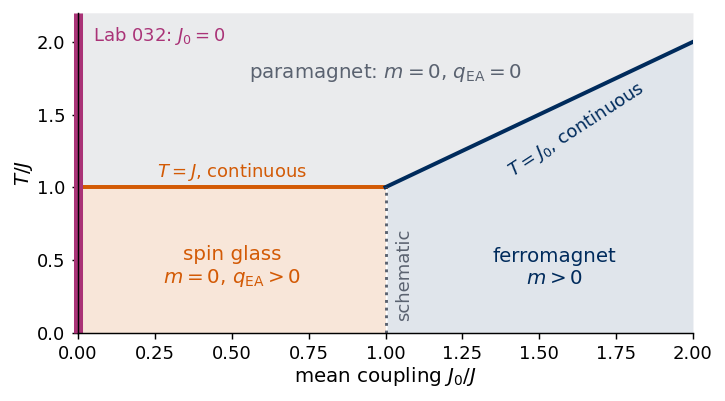

In [40]:
# Schematic figure; this cell does not depend on any other cell of the notebook.
# Colour convention shared by all sketches of the course:
#   spin s = +1: filled navy disc,   spin s = -1: white disc with an orange rim;
#   satisfied bond: solid blue line, broken (frustrated) bond: dashed purple line marked with a cross.
# The figure is drawn at its physical size on a 16:9 slide (5.5 in = full text width) with 10-12 pt text,
# and shown here at a higher screen resolution.
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

NAVY, ORANGE, BLUE, GRAY, PURPLE, GREEN = "#002B5C", "#D35A05", "#005CA7", "#5A6270", "#AA3377", "#228833"
SKETCH_STYLE = {"font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10,
                "ytick.labelsize": 10, "legend.fontsize": 10, "figure.dpi": 130, "lines.linewidth": 1.5,
                "axes.spines.top": False, "axes.spines.right": False}

def save_sketch(fig, name, extra_dirs=()):
    # PNG copy for the lecture slides: white background, 300 dpi, included at its physical width
    os.makedirs("../beamer/figures", exist_ok=True)
    for d in ("../beamer/figures",) + tuple(d for d in extra_dirs if os.path.isdir(d)):
        fig.savefig(os.path.join(d, name), dpi=300, facecolor="white")

def sketch_sk_phase_diagram():
    # couplings J_ij ~ N(J0/N, J^2/N); the exact lines are those where the paramagnet becomes unstable
    fig, ax = plt.subplots(figsize=(5.5, 3.0))
    fig.subplots_adjust(left=0.1, right=0.96, bottom=0.15, top=0.97)
    j0 = np.linspace(0, 2, 200)
    T_line = np.maximum(1.0, j0)                                    # T = J for J0 < J, T = J0 for J0 > J
    ax.fill_between(j0, T_line, 2.2, color=GRAY, alpha=0.12, lw=0)
    ax.fill_between([0, 1], 0, 1, color=ORANGE, alpha=0.15, lw=0)
    ax.fill_between(j0[j0 >= 1], 0, j0[j0 >= 1], color=NAVY, alpha=0.12, lw=0)
    ax.plot([0, 1], [1, 1], color=ORANGE, lw=2.2)
    ax.plot([1, 2], [1, 2], color=NAVY, lw=2.2)
    ax.plot([1, 1], [0, 1], color=GRAY, lw=1.6, ls=":")             # spin glass - ferromagnet boundary: schematic only
    ax.plot([0, 0], [0, 2.2], color=PURPLE, lw=5, solid_capstyle="butt", clip_on=False)
    ax.text(0.5, 1.03, "$T=J$, continuous", ha="center", va="bottom", fontsize=10, color=ORANGE)
    ax.text(1.62, 1.4, "$T=J_0$, continuous", ha="center", va="center", fontsize=10, color=NAVY, rotation=33)
    ax.text(1.0, 1.75, "paramagnet: $m=0$, $q_{\\rm EA}=0$", ha="center", fontsize=11, color=GRAY)
    ax.text(0.5, 0.45, "spin glass\n$m=0$, $q_{\\rm EA}>0$", ha="center", va="center", fontsize=11, color=ORANGE)
    ax.text(1.55, 0.45, "ferromagnet\n$m>0$", ha="center", va="center", fontsize=11, color=NAVY)
    ax.text(1.03, 0.08, "schematic", ha="left", va="bottom", fontsize=10, color=GRAY, rotation=90)
    ax.text(0.05, 2.12, "Lab 032: $J_0=0$", ha="left", va="top", fontsize=10, color=PURPLE)
    ax.set_xlim(0, 2); ax.set_ylim(0, 2.2)
    ax.set_xlabel("mean coupling $J_0/J$", labelpad=1); ax.set_ylabel("$T/J$", labelpad=1)
    return fig

with plt.rc_context(SKETCH_STYLE):
    fig = sketch_sk_phase_diagram()
save_sketch(fig, "sketch_sk_phases.png")
plt.show()


<hr/>
## 8. Replica pairs

### 8.1 Pooled single snapshots
The gauge symmetry makes a sharp statement about what a single snapshot can reveal. Let $p_J(\boldsymbol s)$ be the Boltzmann distribution of sample $J$, and pool
snapshots from many samples, as a data set of the kind produced in Section 5 does. The pooled distribution is $[p_J(\boldsymbol s)]$. For any signs $\tau$,
$$
\big[p_J(\tau\boldsymbol s)\big]=\big[p_{\tau J\tau}(\boldsymbol s)\big]=\big[p_J(\boldsymbol s)\big],
$$
because $p_J(\tau\boldsymbol s)=p_{\tau J\tau}(\boldsymbol s)$ (Section 2.3) and $\tau J\tau$ has the same distribution as $J$. Every configuration can be reached from any other by some $\tau$, so
$$
\big[p_J(\boldsymbol s)\big]=2^{-N}\qquad\text{at every temperature.}
$$
Pooled over disorder, a single snapshot is a uniformly random string of signs, in the paramagnet and in the spin glass alike. No statistic of single snapshots
(magnetisation, correlations between spins, anything) can tell the two phases apart without knowing $J$.

For **pairs** of replicas the same argument with $\tau=\boldsymbol s^a$ maps $(\boldsymbol s^a,\boldsymbol s^b)\to(\boldsymbol 1,\boldsymbol q)$, where
$\boldsymbol q=(s_1^as_1^b,\dots,s_N^as_N^b)$ is the **overlap field**. The pooled pair distribution depends only on $\boldsymbol q$, and because the SK ensemble is
also symmetric under permutations of the spin labels, only on the number of $+1$'s in $\boldsymbol q$, i.e. on the overlap $q$. The overlap field
$q_i=s_i^as_i^b$ is gauge invariant, and it is where the information about the phase lives. We check both statements by exact enumeration.

In [41]:
@jax.jit
def boltzmann_all(J, beta, S):
    """Boltzmann probabilities of all configurations S (2^N, N) for one sample."""
    E = -0.5 * jnp.sum(S * (S @ J), axis=1)
    return jax.nn.softmax(-beta * E)

pooled = jax.jit(jax.vmap(boltzmann_all, in_axes=(0, None, None)))

# single snapshots, N = 8, T = 0.3: pooled distribution against 2^-N
N8, n_samp8 = 8, 20000
S8 = jnp.asarray(np.array(list(itertools.product([-1.0, 1.0], repeat=N8))), jnp.float32)
p8 = np.asarray(pooled(sk_couplings(jax.random.PRNGKey(80), n_samp8, N8), 1 / 0.3, S8))           # (n_samp8, 256)
dev = p8.mean(0) * 2**N8 - 1
stat = p8.std(0) * 2**N8 / np.sqrt(n_samp8)
print(f"N = {N8}, T = 0.3, {n_samp8} samples: largest |2^N [p_J(s)] - 1| = {np.abs(dev).max():.4f};"
      f"  typical statistical error {stat.mean():.4f};  largest deviation / its error = {np.abs(dev / stat).max():.2f}")
print(f"  a single sample is far from uniform: largest 2^N p_J(s) in sample 0 = {p8[0].max() * 2**N8:.1f}")

# pairs, N = 6, T = 0.3: pooled [p_J(s^a) p_J(s^b)] grouped by the overlap q
N6, n_samp6 = 6, 20000
S6 = jnp.asarray(np.array(list(itertools.product([-1.0, 1.0], repeat=N6))), jnp.float32)
p6 = np.asarray(pooled(sk_couplings(jax.random.PRNGKey(60), n_samp6, N6), 1 / 0.3, S6))           # (n_samp6, 64)
pair = np.einsum("da,db->ab", p6, p6) / n_samp6                                                    # (64, 64) pooled pair distribution
Q6 = np.asarray(S6 @ S6.T).astype(int)                                                             # N q of every pair
print(f"\nN = {N6}, T = 0.3: pooled pair probability grouped by the overlap (x 4^N):")
pair_err = np.sqrt((np.einsum("da,db->ab", p6**2, p6**2) / n_samp6 - pair**2) / n_samp6)        # statistical error of each entry
for v in range(-N6, N6 + 1, 2):
    vals, errs = pair[Q6 == v] * 4**N6, pair_err[Q6 == v] * 4**N6
    print(f"  q = {v / N6:+.3f}: {vals.size:5d} pairs,  mean {vals.mean():7.3f},  relative spread within the group {vals.std() / vals.mean():.4f},"
          f"  typical relative statistical error {errs.mean() / vals.mean():.4f}")

N = 8, T = 0.3, 20000 samples: largest |2^N [p_J(s)] - 1| = 0.1766;  typical statistical error 0.0564;  largest deviation / its error = 3.09
  a single sample is far from uniform: largest 2^N p_J(s) in sample 0 = 42.2



N = 6, T = 0.3: pooled pair probability grouped by the overlap (x 4^N):
  q = -1.000:    64 pairs,  mean  18.473,  relative spread within the group 0.0431,  typical relative statistical error 0.0410
  q = -0.667:   384 pairs,  mean   1.218,  relative spread within the group 0.0695,  typical relative statistical error 0.0626
  q = -0.333:   960 pairs,  mean   0.291,  relative spread within the group 0.1030,  typical relative statistical error 0.1001
  q = +0.000:  1280 pairs,  mean   0.186,  relative spread within the group 0.1194,  typical relative statistical error 0.1173
  q = +0.333:   960 pairs,  mean   0.291,  relative spread within the group 0.1030,  typical relative statistical error 0.1001
  q = +0.667:   384 pairs,  mean   1.218,  relative spread within the group 0.0695,  typical relative statistical error 0.0626
  q = +1.000:    64 pairs,  mean  18.473,  relative spread within the group 0.0431,  typical relative statistical error 0.0410


The pooled single-snapshot distribution is uniform to within the statistical error (the largest deviation among the $2^8$ configurations is $3.1$ standard errors, as expected for that many values), although each individual sample is strongly non-uniform. The pooled pair
distribution is constant within each overlap class (the relative spread inside a class is at the level of the sampling noise) and varies strongly between
classes: at $T=0.3$ pairs with $|q|=1$ are much more likely than for random pairs.

### 8.2 Snapshots and overlap fields
To see what this means for real data, we look at snapshots of two replicas of one $N=128$ sample, and their overlap field, above and below $T_c$. The $128$ spins are displayed as an $8\times16$ image only for
convenience: the arrangement is arbitrary, there is no lattice.

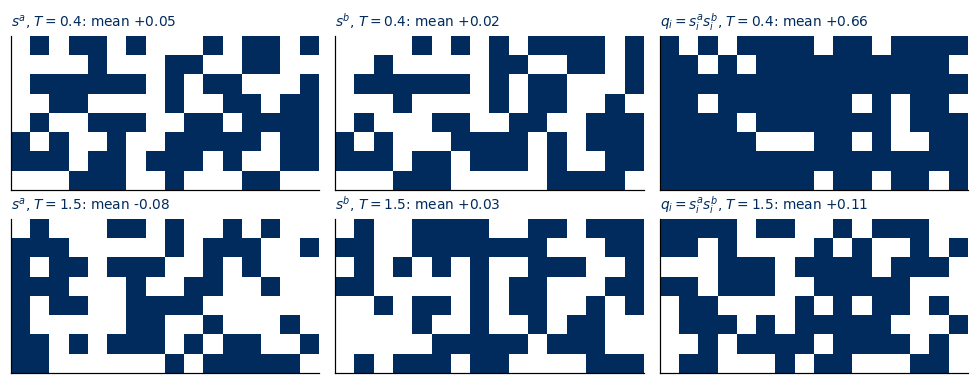

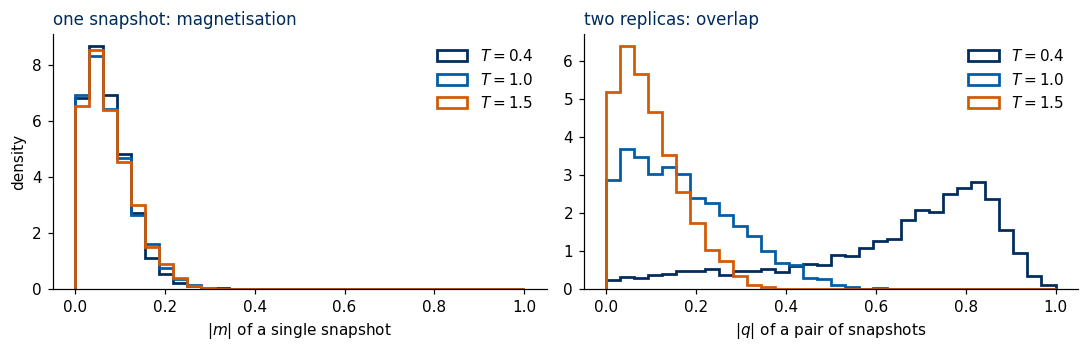

T = 0.4: mean |m| of single snapshots 0.066 (uniformly random strings: 0.070);  mean |q| of replica pairs 0.634
T = 1.5: mean |m| of single snapshots 0.070 (uniformly random strings: 0.070);  mean |q| of replica pairs 0.093


In [42]:
d = sk[128]
fig, ax = plt.subplots(2, 3, figsize=(9, 3.6))
for r, T in enumerate((0.4, 1.5)):
    k = np.argmin(abs(T_GRID - T))
    sa, sb = d["configs"][0, 0, k, -1], d["configs"][0, 1, k, -1]
    for c, (img, name) in enumerate(((sa, "$s^a$"), (sb, "$s^b$"), (sa * sb, "$q_i=s_i^as_i^b$"))):
        ax[r, c].imshow(img.reshape(8, 16), cmap=SPIN_CMAP, vmin=-1, vmax=1)
        ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
        ax[r, c].set_title(f"{name}, $T={T}$: mean {img.mean():+.2f}", fontsize=9)
fig.tight_layout(); savefig(fig, "gen_sk_snapshots.png"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
bins = np.linspace(0, 1, 33)
for T, col in ((0.4, UJNavy), (1.0, UJBlue), (1.5, DSOrange)):
    k = np.argmin(abs(T_GRID - T))
    snaps = d["configs"][:, :, k].astype(np.float32)                          # (D, 2, n_save, N)
    ax[0].hist(np.abs(snaps.mean(-1)).ravel(), bins=bins, density=True, histtype="step", lw=1.8, color=col, label=f"$T={T}$")
    ax[1].hist(np.abs((snaps[:, 0] * snaps[:, 1]).mean(-1)).ravel(), bins=bins, density=True, histtype="step", lw=1.8, color=col, label=f"$T={T}$")
ax[0].set_xlabel("$|m|$ of a single snapshot"); ax[0].set_ylabel("density"); ax[0].set_title("one snapshot: magnetisation"); ax[0].legend(frameon=False)
ax[1].set_xlabel("$|q|$ of a pair of snapshots"); ax[1].set_title("two replicas: overlap"); ax[1].legend(frameon=False)
fig.tight_layout(); plt.show()
for T in (0.4, 1.5):
    k = np.argmin(abs(T_GRID - T))
    snaps = d["configs"][:, :, k].astype(np.float32)
    print(f"T = {T}: mean |m| of single snapshots {np.abs(snaps.mean(-1)).mean():.3f} (uniformly random strings: "
          f"{np.abs(random_spins(jax.random.PRNGKey(5), (20000, 128)).mean(-1)).mean():.3f});  mean |q| of replica pairs {np.abs((snaps[:, 0] * snaps[:, 1]).mean(-1)).mean():.3f}")

The single-snapshot magnetisation has the same distribution at all temperatures, the distribution of a random string of $128$ signs (mean $|m|$ of $0.066$ at $T=0.4$ and $0.070$ at $T=1.5$, against $0.070$ for random strings), exactly as Section 8.1 predicts.
The overlap of two replicas, in contrast, separates the phases clearly (mean $|q|$ of $0.634$ against $0.093$). This is the starting point of the anomaly-detection study in Lecture 5: a method that looks at single
snapshots pooled over samples has nothing to find, while a method that receives pairs of replicas, or their overlap field $q_i$, does. The data set
stores both replicas of every snapshot, together with the couplings, for exactly this purpose.

<hr/>
## 9. Summary

The SK model, $H=-\sum_{i<j}J_{ij}s_is_j$ with Gaussian couplings of variance $J^2/N$, is the simplest spin glass; the factor $1/N$ keeps the local field of order one (Section 2.2).
Its physics involves two averages, thermal averages at fixed couplings followed by the average of $\ln Z$ over the quenched disorder. The annealed free energy $\ln2+\beta^2J^2/4$ is exact above
$T=J$ and fails below, where it predicts a negative entropy, as exact enumeration confirms (Section 2.4).

What makes the model glassy is frustration: a loop with a negative product of couplings cannot satisfy all its bonds, half of the SK triangles are frustrated, and frustration is gauge invariant (Section 3).
The resulting order has no pattern. The magnetisation vanishes, and the order parameter is the overlap of two replicas with the same couplings, whose distribution $P(q)$ is a narrow
peak at $0$ above $T_c$ and broad below, with sample-to-sample fluctuations (Sections 4 and 5).

The transition lies at $T_c=J$: the spin-glass susceptibility $1/(1-\beta^2J^2)$ diverges there (Section 4.4), and the Binder cumulants cross at $0.87$–$0.92$, below $T_c$ at $N\le128$ but moving towards it with $N$, while the
finite-size-scaling collapse with $T_c=J$ holds within the error bars (Section 5.7).
Parallel tempering, implemented in JAX with `vmap` over temperatures, replicas and samples, passes the exact energy–overlap identity of Section 5.4, a necessary condition for equilibrium, for $N\le128$ down to $T=0.4J$.
Below $T_c$ the energy landscape has exponentially many metastable states, relaxation without exchange moves is slow, and the ground-state energy extrapolates towards Parisi's
$e_0=-0.7632$, well above the replica-symmetric $-0.798$ (Section 6).

The Mattis model shows that random signs without frustration give only a hidden ferromagnet, with a sharp $P(q)$, a Binder cumulant approaching $1$ and two metastable states (Section 7).
Finally, pooled over samples, single snapshots are uniformly random at every temperature, while pairs of replicas depend only on their
overlap: the information about the phase is in pairs of replicas (Section 8).

<hr/>
## Exercises

### Exercise 1 — Binder cumulant of four overlap distributions
Compute $g=\frac12\big(3-\langle q^4\rangle/\langle q^2\rangle^2\big)$ for (a) a Gaussian of any width, (b) two delta peaks at $\pm q_0$, (c) the uniform distribution on
$[-1,1]$, and (d) two delta peaks at $\pm q_0$ with weight $1-w$ plus a uniform part on $[-q_0,q_0]$ with weight $w$, a caricature of Parisi's $P(q)$. Compare (d) with
the measured $g$ for $N=128$ at the lowest temperature.

#### Solution

In [43]:
q, s_, q0, w = sp.symbols("q s q0 w", positive=True)
gauss_q = sp.exp(-q**2 / (2 * s_**2)) / sp.sqrt(2 * sp.pi * s_**2)
mom_gauss = [sp.integrate(q**n * gauss_q, (q, -sp.oo, sp.oo)) for n in (2, 4)]
g_of = lambda m2, m4: sp.simplify(sp.Rational(1, 2) * (3 - m4 / m2**2))
print("(a) Gaussian         : g =", g_of(*mom_gauss))
print("(b) delta at +-q0    : g =", g_of(q0**2, q0**4))
print("(c) uniform on [-1,1]: g =", g_of(sp.integrate(q**2 / 2, (q, -1, 1)), sp.integrate(q**4 / 2, (q, -1, 1))))
m2 = (1 - w) * q0**2 + w * sp.integrate(q**2 / (2 * q0), (q, -q0, q0))
m4 = (1 - w) * q0**4 + w * sp.integrate(q**4 / (2 * q0), (q, -q0, q0))
g_d = g_of(m2, m4)
print("(d) peaks + plateau  : g =", sp.factor(g_d), ";  w = 0.3:", sp.N(g_d.subs(w, sp.Rational(3, 10)), 4))
print(f"measured: g(N=128, T={T_GRID[0]}) = {binder(*mom[128])[0]:.3f};  weight w that reproduces it in model (d):",
      [round(float(r), 3) for r in sp.solve(sp.Eq(g_d, binder(*mom[128])[0]), w) if 0 <= float(r) <= 1])

(a) Gaussian         : g = 0
(b) delta at +-q0    : g = 1
(c) uniform on [-1,1]: g = 3/5


(d) peaks + plateau  : g = 3*(10*w**2 - 24*w + 15)/(5*(2*w - 3)**2) ;  w = 0.3: 0.9063


measured: g(N=128, T=0.4) = 0.848;  weight w that reproduces it in model (d): [0.447]


The plateau lowers $g$ below $1$, and $g$ does not depend on $q_0$ in this model. The measured value, $g=0.848$, corresponds to a substantial weight $w\approx0.45$ between the peaks.
In a ferromagnet (or the Mattis model) $w\to0$ and $g\to1$.

### Exercise 2 — Annealed entropy crisis
(a) With SymPy, find the temperature $T^*$ where the annealed entropy $\ln2-\beta^2J^2/4$ vanishes. (b) Using the enumeration data of Section 2.4, print the quenched
entropy per spin at the grid temperature closest to $T^*$ for $N=8,\dots,20$ and show that it is positive. (c) Explain in two sentences why $[\ln Z]\le\ln[Z]$
implies that the true free energy lies above the annealed one.

#### Solution

In [44]:
bb = sp.symbols("beta", positive=True)
T_star_val = 1 / sp.solve(sp.Eq(sp.log(2) - bb**2 / 4, 0), bb)[0]
print("(a) T* =", T_star_val, "=", sp.N(T_star_val, 5), "J")
i = np.argmin(abs(T_enum - float(T_star_val)))
for N in N_ENUM:
    s_q = (enum[N]["logZ"][:, i] / N + enum[N]["U"][:, i] / (N * T_enum[i])).mean()
    print(f"(b) N = {N:2d}, T = {T_enum[i]}: quenched entropy per spin {s_q:.4f}  (annealed {np.log(2) - 1 / (4 * T_enum[i]**2):+.4f})")

(a) T* = 1/(2*sqrt(log(2))) = 0.60056 J
(b) N =  8, T = 0.6: quenched entropy per spin 0.3897  (annealed -0.0013)
(b) N = 10, T = 0.6: quenched entropy per spin 0.3687  (annealed -0.0013)
(b) N = 12, T = 0.6: quenched entropy per spin 0.3521  (annealed -0.0013)
(b) N = 14, T = 0.6: quenched entropy per spin 0.3398  (annealed -0.0013)
(b) N = 16, T = 0.6: quenched entropy per spin 0.3285  (annealed -0.0013)
(b) N = 18, T = 0.6: quenched entropy per spin 0.3244  (annealed -0.0013)
(b) N = 20, T = 0.6: quenched entropy per spin 0.3074  (annealed -0.0013)


(c) $f=-\frac TN[\ln Z]\ge-\frac TN\ln[Z]=f_{\rm ann}$ because the logarithm is concave (Jensen). The annealed calculation lets the couplings adjust to the spins,
which always lowers the free energy; quenched couplings cannot adjust, so the true free energy is higher.

### Exercise 3 — Unscaled couplings
Take couplings $J_{ij}\sim\mathcal N(0,J^2)$ without the factor $1/N$. (a) Show that $H$ with these couplings equals $\sqrt N$ times an SK Hamiltonian, so that the model at
temperature $T$ is the SK model at temperature $T/\sqrt N$. (b) With SymPy, compute the annealed free energy per spin and the temperature where the annealed entropy
vanishes, as a function of $N$. (c) At which $N$ does a system at fixed $T=3J$ enter the spin-glass phase?

#### Solution

In [45]:
NN_, TT_ = sp.symbols("N T", positive=True)
# (a) if J_ij ~ N(0, J^2) then J_ij / sqrt(N) ~ N(0, J^2/N): H_unscaled = sqrt(N) * H_SK, and beta * H_unscaled = (beta sqrt(N)) * H_SK
print("(a) beta_eff = beta * sqrt(N), i.e. T_eff = T / sqrt(N)")
mbf_unscaled = sp.log(2) + (NN_ - 1) * bb**2 / 4                      # ln[Z]/N with sigma^2 = J^2 (J = 1)
s_unscaled = sp.simplify(mbf_unscaled - bb * sp.diff(mbf_unscaled, bb))
T_star_N = sp.sqrt((NN_ - 1) / (4 * sp.log(2)))                     # candidate root of s_ann = 0
print("check: s_ann at beta = 1/T*(N) simplifies to", sp.simplify(s_unscaled.subs(bb, 1 / T_star_N)))
print("(b) -beta f_ann =", mbf_unscaled, ";  s_ann =", s_unscaled, ";  T*(N) =", T_star_N)
for n in (10, 100, 1000):
    print(f"    N = {n:5d}: T* = {float(T_star_N.subs(NN_, n)):.3f} J")
N_glass = sp.solve(sp.Eq(3 / sp.sqrt(NN_), 1), NN_)[0]
print("(c) T_eff = 3/sqrt(N) < T_c = 1  for N >", N_glass)

(a) beta_eff = beta * sqrt(N), i.e. T_eff = T / sqrt(N)
check: s_ann at beta = 1/T*(N) simplifies to 0
(b) -beta f_ann = beta**2*(N - 1)/4 + log(2) ;  s_ann = 

beta**2*(1 - N)/4 + log(2) ;  T*(N) = sqrt(N - 1)/(2*sqrt(log(2)))
    N =    10: T* = 1.802 J
    N =   100: T* = 5.976 J
    N =  1000: T* = 18.982 J
(c) T_eff = 3/sqrt(N) < T_c = 1  for N > 9


Without the $1/N$ every characteristic temperature grows like $\sqrt N$: a large system would be frozen at any fixed temperature, and there is no thermodynamic limit.

### Exercise 4 — Frustration in the 2D Edwards–Anderson model
The Edwards–Anderson model has couplings only between nearest neighbours of a lattice [Edwards & Anderson 1975]. On a square lattice with $J_{ij}=\pm1$, each bond
negative with probability $p$ independently, every elementary square (plaquette) is a loop of four bonds. (a) With SymPy, show that a plaquette is frustrated with
probability $\frac12\big[1-(1-2p)^4\big]$. (b) Check it on a $200\times200$ periodic lattice for several $p$.

#### Solution

In [46]:
p_ = sp.symbols("p", positive=True)
mean_bond = (1 - p_) * 1 + p_ * (-1)                                   # E[J] for one bond
mean_prod = mean_bond**4                                               # four independent bonds
P_frus = sp.simplify((1 - mean_prod) / 2)                              # a product of +-1 is -1 with probability (1 - E[product]) / 2
print("(a) P(frustrated plaquette) =", sp.factor(P_frus), ";  at p = 1/2:", P_frus.subs(p_, sp.Rational(1, 2)))

def plaquette_fraction(L, p, rng):
    Jx = np.where(rng.random((L, L)) < p, -1, 1)                       # bond (x, y) - (x, y+1)
    Jy = np.where(rng.random((L, L)) < p, -1, 1)                       # bond (x, y) - (x+1, y)
    prod = Jx * np.roll(Jy, -1, axis=1) * np.roll(Jx, -1, axis=0) * Jy  # the four bonds around the plaquette with corner (x, y)
    return np.mean(prod < 0)

for pv in (0.0, 0.1, 0.25, 0.5, 0.75):
    print(f"(b) p = {pv:4.2f}: simulated {plaquette_fraction(200, pv, rng):.4f},  formula {float(P_frus.subs(p_, pv)):.4f}")

(a) P(frustrated plaquette) = -4*p*(p - 1)*(2*p**2 - 2*p + 1) ;  at p = 1/2: 1/2
(b) p = 0.00: simulated 0.0000,  formula 0.0000
(b) p = 0.10: simulated 0.2943,  formula 0.2952
(b) p = 0.25: simulated 0.4691,  formula 0.4688
(b) p = 0.50: simulated 0.5008,  formula 0.5000
(b) p = 0.75: simulated 0.4718,  formula 0.4688


<hr/>
## References

**Original papers**
* D. Sherrington, S. Kirkpatrick, *Solvable model of a spin-glass*, Phys. Rev. Lett. **35**, 1792 (1975), [doi:10.1103/PhysRevLett.35.1792](https://doi.org/10.1103/PhysRevLett.35.1792)
* S. F. Edwards, P. W. Anderson, *Theory of spin glasses*, J. Phys. F **5**, 965 (1975), [doi:10.1088/0305-4608/5/5/017](https://doi.org/10.1088/0305-4608/5/5/017)
* D. C. Mattis, *Solvable spin systems with random interactions*, Phys. Lett. A **56**, 421 (1976), [doi:10.1016/0375-9601(76)90396-0](https://doi.org/10.1016/0375-9601(76)90396-0)
* D. J. Thouless, P. W. Anderson, R. G. Palmer, *Solution of 'Solvable model of a spin glass'*, Phil. Mag. **35**, 593 (1977), [doi:10.1080/14786437708235992](https://doi.org/10.1080/14786437708235992)
* J. R. L. de Almeida, D. J. Thouless, *Stability of the Sherrington–Kirkpatrick solution of a spin glass model*, J. Phys. A **11**, 983 (1978), [doi:10.1088/0305-4470/11/5/028](https://doi.org/10.1088/0305-4470/11/5/028)
* S. Kirkpatrick, D. Sherrington, *Infinite-ranged models of spin-glasses*, Phys. Rev. B **17**, 4384 (1978), [doi:10.1103/PhysRevB.17.4384](https://doi.org/10.1103/PhysRevB.17.4384)
* G. Parisi, *Infinite number of order parameters for spin-glasses*, Phys. Rev. Lett. **43**, 1754 (1979), [doi:10.1103/PhysRevLett.43.1754](https://doi.org/10.1103/PhysRevLett.43.1754)
* G. Parisi, *A sequence of approximated solutions to the S-K model for spin glasses*, J. Phys. A **13**, L115 (1980), [doi:10.1088/0305-4470/13/4/009](https://doi.org/10.1088/0305-4470/13/4/009)
* G. Parisi, *Order parameter for spin-glasses*, Phys. Rev. Lett. **50**, 1946 (1983), [doi:10.1103/PhysRevLett.50.1946](https://doi.org/10.1103/PhysRevLett.50.1946)
* M. Aizenman, J. L. Lebowitz, D. Ruelle, *Some rigorous results on the Sherrington–Kirkpatrick spin glass model*, Commun. Math. Phys. **112**, 3 (1987), [doi:10.1007/BF01217677](https://doi.org/10.1007/BF01217677)
* A. Crisanti, T. Rizzo, *Analysis of the ∞-replica symmetry breaking solution of the Sherrington–Kirkpatrick model*, Phys. Rev. E **65**, 046137 (2002), [doi:10.1103/PhysRevE.65.046137](https://doi.org/10.1103/PhysRevE.65.046137), [arXiv:cond-mat/0111037](https://arxiv.org/abs/cond-mat/0111037)
* M. Talagrand, *The Parisi formula*, Ann. Math. **163**, 221 (2006), [doi:10.4007/annals.2006.163.221](https://doi.org/10.4007/annals.2006.163.221)

**Monte Carlo methods and numerics**
* R. H. Swendsen, J.-S. Wang, *Replica Monte Carlo simulation of spin-glasses*, Phys. Rev. Lett. **57**, 2607 (1986), [doi:10.1103/PhysRevLett.57.2607](https://doi.org/10.1103/PhysRevLett.57.2607)
* K. Hukushima, K. Nemoto, *Exchange Monte Carlo method and application to spin glass simulations*, J. Phys. Soc. Jpn. **65**, 1604 (1996), [doi:10.1143/JPSJ.65.1604](https://doi.org/10.1143/JPSJ.65.1604)
* D. J. Earl, M. W. Deem, *Parallel tempering: theory, applications, and new perspectives*, Phys. Chem. Chem. Phys. **7**, 3910 (2005), [doi:10.1039/b509983h](https://doi.org/10.1039/b509983h)
* A. P. Young, *Direct determination of the probability distribution for the spin-glass order parameter*, Phys. Rev. Lett. **51**, 1206 (1983), [doi:10.1103/PhysRevLett.51.1206](https://doi.org/10.1103/PhysRevLett.51.1206)
* H. G. Katzgraber, M. Palassini, A. P. Young, *Monte Carlo simulations of spin glasses at low temperatures*, Phys. Rev. B **63**, 184422 (2001), [doi:10.1103/PhysRevB.63.184422](https://doi.org/10.1103/PhysRevB.63.184422)
* S. Boettcher, *Extremal optimization for Sherrington–Kirkpatrick spin glasses*, Eur. Phys. J. B **46**, 501 (2005), [doi:10.1140/epjb/e2005-00280-6](https://doi.org/10.1140/epjb/e2005-00280-6), [arXiv:cond-mat/0407130](https://arxiv.org/abs/cond-mat/0407130)
* A. Billoire, *Some aspects of infinite range models of spin glasses: theory and numerical simulations*, lecture notes, [arXiv:0709.1552](https://arxiv.org/abs/0709.1552)

**Experiments, optimisation and machine learning**
* V. Cannella, J. A. Mydosh, *Magnetic ordering in gold-iron alloys*, Phys. Rev. B **6**, 4220 (1972), [doi:10.1103/PhysRevB.6.4220](https://doi.org/10.1103/PhysRevB.6.4220)
* K. Binder, A. P. Young, *Spin glasses: experimental facts, theoretical concepts, and open questions*, Rev. Mod. Phys. **58**, 801 (1986), [doi:10.1103/RevModPhys.58.801](https://doi.org/10.1103/RevModPhys.58.801)
* F. Barahona, *On the computational complexity of Ising spin glass models*, J. Phys. A **15**, 3241 (1982), [doi:10.1088/0305-4470/15/10/028](https://doi.org/10.1088/0305-4470/15/10/028)
* S. Kirkpatrick, C. D. Gelatt, M. P. Vecchi, *Optimization by simulated annealing*, Science **220**, 671 (1983), [doi:10.1126/science.220.4598.671](https://doi.org/10.1126/science.220.4598.671)
* A. Lucas, *Ising formulations of many NP problems*, Front. Phys. **2**, 5 (2014), [doi:10.3389/fphy.2014.00005](https://doi.org/10.3389/fphy.2014.00005), [arXiv:1302.5843](https://arxiv.org/abs/1302.5843)
* J. J. Hopfield, *Neural networks and physical systems with emergent collective computational abilities*, Proc. Natl. Acad. Sci. USA **79**, 2554 (1982), [doi:10.1073/pnas.](https://doi.org/10.1073/pnas.)

**Textbooks and monographs**
* M. Mézard, G. Parisi, M. A. Virasoro, *Spin Glass Theory and Beyond*, World Scientific (1986), [doi:10.1142/0271](https://doi.org/10.1142/0271): the replica method and Parisi's solution.
* K. H. Fischer, J. A. Hertz, *Spin Glasses*, Cambridge University Press (1991), [doi:10.1017/CBO9780511628771](https://doi.org/10.1017/CBO9780511628771): experiments and theory.
* H. Nishimori, *Statistical Physics of Spin Glasses and Information Processing: An Introduction*, Oxford University Press (2001), [doi:10.1093/acprof:oso/9780198509417.001.0001](https://doi.org/10.1093/acprof:oso/9780198509417.001.0001): the gauge symmetry of spin glasses and applications to information processing.
* M. Mézard, A. Montanari, *Information, Physics, and Computation*, Oxford University Press (2009), [doi:10.1093/acprof:oso/9780198570837.001.0001](https://doi.org/10.1093/acprof:oso/9780198570837.001.0001): spin glasses, optimisation and inference.
* D. Panchenko, *The Sherrington–Kirkpatrick Model*, Springer (2013), [doi:10.1007/978-1-4614-6289-7](https://doi.org/10.1007/978-1-4614-6289-7): the rigorous theory.
* P. Charbonneau, E. Marinari, M. Mézard, G. Parisi, F. Ricci-Tersenghi, G. Sicuro, F. Zamponi, *Spin Glass Theory and Far Beyond: Replica Symmetry Breaking After 40 Years*, World Scientific (2023), [doi:10.1142/13341](https://doi.org/10.1142/13341): reviews of the field and its applications.